## IMPLEMENTATION OF THE MARKOWITZ MODEL AND LASSO REGRESSION 

### BRIEF INTRODUCTION 



The bedrock of contemporary finance was established in 1952 when Harry Markowitz published his seminal paper "Portfolio Selection ", introducing the world to Modern Portfolio Theory. His seminal work established that an investment's risk and return should not be viewed in isolation, but rather by how it contributes to a portfolio's overall variance and correlation.  This groundbreaking insight eventually earned him the Nobel Prize in Economic Sciences, cementing his status as one of the father of modern investment strategy.  
From the prospective of the investor,he is trying to maximize a given quantity, namely utility, that  quantifies the level of satisfaction of the  investor for a given risk/return. Clearly a rational investor prefer an investment opportunity with higher expected utility and are indifferent between investment opportunity with the same expected utility. The certain equivalent is the wealth level giving the same utility of a risky investment. We could express it as :
$$u(CE) = \mathbb{E}[u(W_{t+1})]$$

where W is the wealth of the investor.  
It can be proved that an investor interested in maximizing his utility could maximize CE and, equivalently, maximize a function of mean and variance of the risky investment outcome, accounting also for the role exerted by the risk aversion. 
We aim at determining the optimal investment choiche of an investor by means of maximizing the expected utility or, equivalently, maximizing the certain equivalent. The agent is rational and wants to identify the optimal investment opportunity by solving an approximate problem based on the firsts two momemnts of the risky assets: 
$$\max \quad CE = \mathbb{E}[W] - \frac{b}{2} \mathbb{V}[W]$$
Investors are not just considering the investment opportunities which are given by a specific asset, but consider a portfolios of asset coherently with the idea of finding the optimal mix of assets. 

The model  consists of solving the following problem : 
$$\min_{w} \quad w^\top \Sigma w$$

$$\text{s.t.} \quad \mu_p = w^\top \mu$$

$$\quad \quad \quad w^\top \mathbf{1}_n = 1$$

where :  
* $w \in \mathbb{R}^n - \text{represents the vector of portfolio weights }$
* $ \Sigma \in \mathbb{R}^{n * n} -\text {covariance matrix of asset return.}$
* $ \mu \in \mathbb{R}^n - \text{ vector of expected return }$
* $ \mu_p  - \text{represents the target portfolio expected retur} $
* $\mathbf{1}_n - \text{n-dimensional vector composed by 1}$
* $w^\top \Sigma w = \sigma^2_p -\text {is equal to the portfolio variance}$



The obtained portfolio is efficent for a given level of return $\mu_p$ that is there isn't another portfolio with the same expected return for this level of risk. Alternatively we can represents the problem as : 
$$\max_{w} \quad w^\top \mu $$
$$s.t.\quad  \sigma^2_p = w^\top \Sigma w $$
$$\quad \quad \quad w^\top \mathbf{1}_n = 1$$

One of the problem recognize by the financial  industry is the sensitivity of the markowitz input (namely the expected return and the variance/covariances matrices). I decide to  tackle this problem by implementign the l1 lasso regression in the context of portfolio optimization, which allows us to performe future selection (restricting the number of assets ) whilst reaching a good level of return with minimum risk. 






#### CONFIGURATION 

I downloaded the total return index from refinitiv (LSEG). The total return index is an index that measure the performance of a group of components by assuming that all cash distributions are reinvested, in addition to tracking the components price movememnts (the python script for downloading  the data is on another file.)  The data consists of 100 US based companies taken from the SP500 at a weekly and monthly frequency (from semptember 2004 to december 2025). The companies belongs to different sector  which are : technology, financials, healthcare, consumer discretionary, consumer  staples, energy, industrials, materials, utilities, real estate,commercial services.

#### LIBRARY 

In [1]:
import numpy as np
import pandas as pd 
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
import cvxpy as cp 
import matplotlib.pyplot as plt
import matplotlib.lines as mlines
from sklearn.linear_model import lars_path
from sklearn.preprocessing import StandardScaler
import inspect  
from types import SimpleNamespace 

#### DATA PREPARATION

In [2]:
# Load returns (percentage form from Refinitiv TR.TotalReturn)
weekly_return = pd.read_csv('sp500_tri_weekly.csv', index_col=0, parse_dates=True) # index_col = 0 set the index (dates) pointing to the column = 0 (first column)
monthly_return = pd.read_csv('sp500_tri_monthly.csv', index_col=0, parse_dates=True) #parse_dates = true parsing the index. it is working otherwise use to_datetime after read.csv 

print(f"the number of observation in the weekly return is : {weekly_return.shape[0]}") # for the weekly i have 1113 raws and 100 columns (raws correpsond to obeservation and column correspond to the  ticker)
print(f"the number of columns  in the weekly return is : {weekly_return.shape[1]}. This correpond to the tickets (companies)  that i have : ")# each column correspond to a ticket (e.g. apple, microsoft, )

print(f"\n Weekly returns:") # for the weekly i have 1113 raws and 100 columns (raws correspond  to obeservation and column correspond to the  ticker)
print(weekly_return.head(5))

print('*'*50)
print(f" Number of observation in the case of monthly return is : {monthly_return.shape[0]}")## here i have 256 observation (raws ) and always 100 columns. 
print(f" the number of ticket in the case of montly return is : {monthly_return.shape[1]}")
print(f" the size of the data frame in the case of monthly return is : {monthly_return.size}") # the size of the data frame is the number of element in the data frame. it is equal to the number of raws (observation) multiplied by the number of columns (ticket)
print(f"\nThe firsts 5  Monthly returns:")
print(monthly_return.head(5))





the number of observation in the weekly return is : 1113
the number of columns  in the weekly return is : 100. This correpond to the tickets (companies)  that i have : 

 Weekly returns:
                             AAPL.O    MSFT.O     IBM.N    ORCL.N    CSCO.O  \
Date                                                                          
2004-09-03 00:00:00+00:00  2.561863 -1.274581 -0.647516 -2.526725 -3.697997   
2004-09-10 00:00:00+00:00  1.816634  1.401697  2.808390  4.586241  9.120000   
2004-09-17 00:00:00+00:00  3.540563  0.072754 -1.175657  9.723546 -6.353861   
2004-09-24 00:00:00+00:00  0.403877 -0.799709 -1.527875 -4.344049 -3.966597   
2004-10-01 00:00:00+00:00  3.700724  3.517772  2.712306  8.083560  2.880435   

                             INTC.O      TXN.O    QCOM.O     ADI.O    ADBE.O  \
Date                                                                           
2004-09-03 00:00:00+00:00 -8.946412  -5.752212  0.156128 -2.594071  0.258565   
2004-09-10 00:00:00

EXPLORING DATA

In [3]:
#Names of the columns correpsond to the ticket. 100 U.S.A. based company. 
print(f" Names  of the columns (tickers) of the  dataset is : \n {weekly_return.columns}")# column name 
print(f"The index represents the date (dtype = datetime) : \n {weekly_return.index}")## the index correspond to the date in a datetimeIndex format. this is the weekly format.
print(f"the number  of NA is our dataset for the weekly return is : {weekly_return.isnull().sum().sum()}")
print(f"the number of NA values in our dataset for the montly return is : {monthly_return.isnull().sum().sum()} ")
# Fortunately there is no na values in our dataset. 
  

 Names  of the columns (tickers) of the  dataset is : 
 Index(['AAPL.O', 'MSFT.O', 'IBM.N', 'ORCL.N', 'CSCO.O', 'INTC.O', 'TXN.O',
       'QCOM.O', 'ADI.O', 'ADBE.O', 'INTU.O', 'KLAC.O', 'AMAT.O', 'MU.O',
       'LRCX.O', 'JPM.N', 'BAC.N', 'WFC.N', 'C.N', 'GS.N', 'MS.N', 'USB.N',
       'PNC.N', 'TFC.N', 'BK.N', 'STT.N', 'AXP.N', 'BLK.N', 'SCHW.N', 'COF.N',
       'JNJ.N', 'UNH.N', 'PFE.N', 'LLY.N', 'TMO.N', 'ABT.N', 'MRK.N', 'DHR.N',
       'BMY.N', 'AMGN.O', 'GILD.O', 'CVS.N', 'AMZN.O', 'HD.N', 'MCD.N',
       'NKE.N', 'LOW.N', 'SBUX.O', 'TGT.N', 'TJX.N', 'F.N', 'TM', 'KR.N',
       'PG.N', 'KO.N', 'PEP.O', 'COST.O', 'CLX.N', 'MO.N', 'CL.N', 'GIS.N',
       'XOM.N', 'CVX.N', 'COP.N', 'EOG.N', 'SLB.N', 'HAL.N', 'OXY.N', 'BA.N',
       'HON.O', 'UNP.N', 'UPS.N', 'CAT.N', 'GE.N', 'MMM.N', 'LMT.N', 'RTX.N',
       'DE.N', 'PPG.N', 'APD.N', 'SHW.N', 'ECL.N', 'NEM.N', 'FMC.N', 'NEE.N',
       'DUK.N', 'SO.N', 'D.N', 'EXC.O', 'PLD.N', 'AMT.N', 'CCI.N', 'PSA.N',
       'SPG.N', 'GOOGL.O', 'N

#### IMPLEMENTATION OF THE REBALANCING DATES. 

In [4]:
# Original monthly calendar retained for Approach B, including its existing
# historical-data eligibility checks. Approach A uses the independent weekly
# observation calendar defined below.

## setting the estimation window and the minimum number of weekly and monthly obs. 
ESTIMATION_WINDOW_YEARS = 9
WEEKLY_WINDOW_OBS = 52 * ESTIMATION_WINDOW_YEARS
MONTHLY_WINDOW_OBS = 12 * ESTIMATION_WINDOW_YEARS

# pd.datetimeindex = Immutable ndarray-like of datetime64 delta. Enables fast partial string index, time-based slicing and powerfull aggregation. 
##sort_values = sort in ascending order and .unique() it remove duplicates. 
candidate_rebalancing_dates = pd.DatetimeIndex(monthly_return.index).sort_values().unique()

## This procedure initialize the rebalancing dates if rebalancing dates contains at least 468 obs for weekly and 108 observation for monthly. 
rebalancing_dates = pd.DatetimeIndex([
    date for date in candidate_rebalancing_dates
    if weekly_return.loc[weekly_return.index < date].dropna(axis=0, how="any").shape[0] >= WEEKLY_WINDOW_OBS
    and monthly_return.loc[monthly_return.index < date].dropna(axis=0, how="any").shape[0] >= MONTHLY_WINDOW_OBS
])

if rebalancing_dates.empty:
    raise ValueError("No rebalancing date has enough history for both 9-year windows.")

first_date = min(weekly_return.index[0], monthly_return.index[0])
print(f"\nFirst available date:        {first_date.date()}")
print(f"First rebalancing date:      {rebalancing_dates[0].date()}")
print(f"Last rebalancing date:       {rebalancing_dates[-1].date()}")
print(f"Number of rebalancing dates: {len(rebalancing_dates)}")
print(f"Weekly observations/window:  {WEEKLY_WINDOW_OBS}")
print(f"Monthly observations/window: {MONTHLY_WINDOW_OBS}")


# Independent weekly schedule: observe 468 weeks, hold the next four, roll by four.
# These are four-week decisions (about 13 per year), not calendar month-ends.
# The original `rebalancing_dates` above remains unchanged for Approach B.
WEEKLY_REBALANCE_OBS = 4


def build_weekly_estimation_calendar(returns, window_observations=468, step=4):
    """Windows include the decision-close observation; trading starts afterward."""
    ordered = returns.sort_index()
    if not isinstance(ordered.index, pd.DatetimeIndex) or ordered.index.has_duplicates:
        raise ValueError("Weekly data require a unique datetime index.")
    if ordered.columns.has_duplicates or not np.isfinite(ordered.to_numpy(dtype=float)).all():
        raise ValueError("Weekly calendar requires complete data; missing weeks cannot be skipped.")
    if window_observations < 2 or step < 1 or len(ordered) <= window_observations:
        raise ValueError("Insufficient weekly data or invalid rolling-window parameters.")
    windows = {}
    for position in range(window_observations - 1, len(ordered) - 1, step):
        date = ordered.index[position]
        windows[date] = ordered.iloc[position - window_observations + 1:position + 1].copy()
    return pd.DatetimeIndex(list(windows)), windows


rebalancing_dates_A, weekly_estimation_windows = build_weekly_estimation_calendar(
    weekly_return, WEEKLY_WINDOW_OBS, WEEKLY_REBALANCE_OBS,
)
print(f"Approach A: {len(rebalancing_dates_A)} four-week decisions, "
      f"{rebalancing_dates_A[0].date()} to {rebalancing_dates_A[-1].date()}")
print("Weekly windows end at the decision close; the next weekly observation is out of sample.")



First available date:        2004-09-03
First rebalancing date:      2013-09-30
Last rebalancing date:       2025-12-31
Number of rebalancing dates: 148
Weekly observations/window:  468
Monthly observations/window: 108
Approach A: 162 four-week decisions, 2013-08-16 to 2025-12-19
Weekly windows end at the decision close; the next weekly observation is out of sample.


In [5]:
# =============================================================================
# APPROACH A: WEEKLY RETURNS, 9-YEAR WINDOW, REBALANCING EVERY FOUR WEEKS
# =============================================================================

print("\n" + "=" * 70)
print("APPROACH A: ESTIMATE WITH WEEKLY RETURNS (9-year window)")


rolling_mu_A = {} #dictionares of rolling mean. every key contains the ticker associated with the corresponding mean returm. key = date and value = mean vector. 
rolling_cov_A = {} # dictionares of rolling covariance 
rolling_vol_A = {} #difference of rolling standard deviations. 


## building the rolling nine-year estimates for Approach A, using weekly returns 
for date in rebalancing_dates_A:
    # Window ends at this weekly close; the next observation is the first OOS return.
    history = weekly_estimation_windows[date]
    window = history.iloc[-WEEKLY_WINDOW_OBS:] ## take the lastest weekly_window_obs valid from that historical dataset

    # safety check to ensure that the window have at least 468 valid past weekly observation. 
    if len(window) != WEEKLY_WINDOW_OBS:
        raise ValueError(f"Approach A has {len(window)} observations at {date}, expected {WEEKLY_WINDOW_OBS}.")

    ## computes the vector of expected mean using sample mean. 
    rolling_mu_A[date] = window.mean()

    ## computes the vector of expected covariance  using sample covariance. 
    rolling_cov_A[date] = window.cov()

    ## computes the vector of expected standard deviations sample standard deviations. 
    rolling_vol_A[date] = window.std()


print(f"Number of estimates: {len(rolling_mu_A)}")
print(f"Observations per window: {WEEKLY_WINDOW_OBS} weekly observations")

first_key = list(rolling_mu_A.keys())[0] # convert the list of the keys and then grab the first element. so this will print the first rebalancing date.
# the keys  contains the date and the values contain the mean vector. 
print(f"\nFirst estimate at {first_key.date()}:")
print(f"  Mean vector (first 5):")
print(rolling_mu_A[first_key].head().round(4))

second_key_A = list(rolling_mu_A.keys())[1] # printing the second element of the list of the keys. so this will print the second rebalancing date.
print(f"\nSecond estimate at {second_key_A.date()}:")
print(f"  Mean vector (first 5):")
print(rolling_mu_A[second_key_A].head().round(4))

third_key_A = list(rolling_mu_A.keys())[2] # printing the third element of the list of the keys. so this will print the third rebalancing date.
print(f"\nThird estimate at {third_key_A.date()}:")
print(f"  Mean vector (first 5):")
print(rolling_mu_A[third_key_A].head().round(4))


first_covariance_A = rolling_cov_A[first_key]
print(f"\nFirst covariance matrix at {first_key.date()} (Approach A):")
print(first_covariance_A.round(4))

# second covariance matrix for the approach A.

second_covariance_A = rolling_cov_A[second_key_A]
print(f"\nSecond covariance matrix at {second_key_A.date()} (Approach A):")
print(second_covariance_A.round(4))


# =============================================================================
# APPROACH B: MONTHLY RETURNS, 9-YEAR WINDOW, MONTHLY REBALANCING
# =============================================================================

## Same structure as for approach A weekly return. 

print("\n" + "=" * 70)
print("APPROACH B: ESTIMATE WITH MONTHLY RETURNS (9-year window)")
print("=" * 70)

rolling_mu_B = {}
rolling_cov_B = {}
rolling_vol_B = {}

for date in rebalancing_dates:
    history = monthly_return.loc[monthly_return.index < date].dropna(axis=0, how="any")
    window = history.iloc[-MONTHLY_WINDOW_OBS:]

    if len(window) != MONTHLY_WINDOW_OBS:
        raise ValueError(f"Approach B has {len(window)} observations at {date}, expected {MONTHLY_WINDOW_OBS}.")

    rolling_mu_B[date] = window.mean()
    rolling_cov_B[date] = window.cov()
    rolling_vol_B[date] = window.std()

print(f"Number of estimates: {len(rolling_mu_B)}")
print(f"Observations per window: {MONTHLY_WINDOW_OBS} monthly observations")

## check if the first cycle take the right date and right number of dates. 

first_key_B = list(rolling_mu_B.keys())[0] ## printing the first element of the list of the keys so this will print the first rebalancing date.
print(f"\nFirst estimate at {first_key_B.date()}:")
print(f"  Mean vector (first 5):")
print(rolling_mu_B[first_key_B].head().round(4))

second_key_B = list(rolling_mu_B.keys())[1] ## printing the second element of the list of the keys so this will print the second rebalancing date.
print(f"\nSecond estimate at {second_key_B.date()}:")
print(f"  Mean vector (first 5):")
print(rolling_mu_B[second_key_B].head().round(4))

third_key_B = list(rolling_mu_B.keys())[2] ## printing the third element of the list of the keys so this will print the third rebalancing date.
print(f"\nThird estimate at {third_key_B.date()}:")
print(f"  Mean vector (first 5):")
print(rolling_mu_B[third_key_B].head().round(4))

## now i will print also the covariance matrix for the first rebalancing date for the approach A and B.

first_covariance_B = rolling_cov_B[first_key_B]
print(f"\nFirst covariance matrix at {first_key_B.date()} (Approach B):")
print(first_covariance_B.round(4))

# second covariance matrix for the approach B.

second_covariance_B = rolling_cov_B[second_key_B]
print(f"\nSecond covariance matrix at {second_key_B.date()} (Approach B):")
print(second_covariance_B.round(4))
# same as above it is not necessary to comment. 

# =============================================================================
# CONVERT TO DATAFRAMES
# =============================================================================

df_rolling_mu_A = pd.DataFrame(rolling_mu_A).T ## we take the transpose to flip the columns with the raw now we have 220 raws, which
# correspond tot he dates with 100 columns with correspond to the tiker (220x100 matrix )
df_rolling_vol_A = pd.DataFrame(rolling_vol_A).T
df_rolling_mu_B = pd.DataFrame(rolling_mu_B).T
df_rolling_vol_B = pd.DataFrame(rolling_vol_B).T

# =============================================================================
# SUMMARY
# =============================================================================

print("\n" + "=" * 70)
print("ROLLING WINDOW ESTIMATION COMPLETE!")
print("=" * 70)
print(f"\nSetup:")
print(f"  Window size: {ESTIMATION_WINDOW_YEARS} years")
print(f"  Rebalancing: A every four weeks ({len(rebalancing_dates_A)} dates); B monthly ({len(rebalancing_dates)} dates)")
print(f"  Period: {rebalancing_dates[0].date()} to {rebalancing_dates[-1].date()}")
print(f"\nApproach A - Estimate with WEEKLY returns:")
print(f"  rolling_mu_A   {len(rolling_mu_A)} estimates, {WEEKLY_WINDOW_OBS} obs per window")
print(f"  rolling_cov_A  {len(rolling_cov_A)} covariance matrices (100x100)")
print(f"\nApproach B - Estimate with MONTHLY returns:")
print(f"  rolling_mu_B   {len(rolling_mu_B)} estimates, {MONTHLY_WINDOW_OBS} obs per window")
print(f"  rolling_cov_B  {len(rolling_cov_B)} covariance matrices (100x100)")
print(f"\nNote: Approach A has more observations per window ({WEEKLY_WINDOW_OBS} vs {MONTHLY_WINDOW_OBS}).")
# print the number of observation in the case of the weekly return and in the case of the monthly return.



APPROACH A: ESTIMATE WITH WEEKLY RETURNS (9-year window)
Number of estimates: 162
Observations per window: 468 weekly observations

First estimate at 2013-08-16:
  Mean vector (first 5):
AAPL.O    0.8663
MSFT.O    0.1544
IBM.N     0.2460
ORCL.N    0.3229
CSCO.O    0.1441
dtype: float64

Second estimate at 2013-09-13:
  Mean vector (first 5):
AAPL.O    0.8326
MSFT.O    0.1657
IBM.N     0.2552
ORCL.N    0.3074
CSCO.O    0.1553
dtype: float64

Third estimate at 2013-10-11:
  Mean vector (first 5):
AAPL.O    0.7910
MSFT.O    0.1691
IBM.N     0.2409
ORCL.N    0.2891
CSCO.O    0.1491
dtype: float64

First covariance matrix at 2013-08-16 (Approach A):
          AAPL.O   MSFT.O   IBM.N   ORCL.N   CSCO.O  INTC.O   TXN.O  QCOM.O  \
AAPL.O   27.1677   6.0097  7.9576   6.9542   7.3440  8.5505  8.8759  8.6215   
MSFT.O    6.0097  12.3889  5.3013   6.9214   7.1157  7.0985  5.8148  4.8852   
IBM.N     7.9576   5.3013  9.6819   6.7319   7.3161  7.2743  7.1132  6.6428   
ORCL.N    6.9542   6.9214  6.7

#### GLOBAL MINIMUM VARIANCE PORTFOLIO (GMV)

In [6]:
# =========================================================================
# Creating the Global minimum variance function. 

# i can also remove the mean vector since it is not included in the GMV computation. 

def gmv_portfolio(mean, cov_matrix):
    """
    GLOBAL MINIMUM VARIANCE PORTFOLIO. 
    minimize the portfolio variance = w*Sigma*w
    such that W*1 = 1. the sum of the weights needs to be equal to 1. 
    The portfolio has the following weights : 
    W_v = inv(sigma)*1_n where n = correspond to  total number of assett. 
    r_t = (r'*(sigma)*1_n)/ (1_n(sigma)*1_n where the numerator is equal to B and denominator is equal to C. 
    portfolio standard deviation = sigma_t = 1/sqrt(C)

    """
    Sigma = cov_matrix.values  # extracting the covariance  matrix from the dataframe and check if it is correct. 
    mu = mean.values  # extracting the mean returns from the dataframe
    # values() contains the ticket and the corresponding values and the keys contains the rebalancing date. 
    ##  now we have to create the values of 1. n = number of assets (100) in our case. 
    n = Sigma.shape[0] # creates a shapes equal to the number of observation
    ones = np.ones(n)
    
    # computing Σ^{-1}. for the weekly return we have enough information.
    Sigma_inv = np.linalg.inv(Sigma) # computing the inverse of the matrix. this is necessary for implementing the markowitz model. 
   
    A = Sigma_inv @ ones 
    B = mu.T @ Sigma_inv @ ones
    C = ones @ Sigma_inv @ ones

    w = A / C # computing the weights of the global minimum variance portfolio. this is equal to 1/C * Sigma^{-1}*1. this is the formula for the global minimum variance portfolio.            
    
    port_ret = B/C
    port_std = 1 / np.sqrt(C)
    
    if isinstance(cov_matrix, pd.DataFrame): # converting weight back to a labelled series. so we can inspect  the weights if we have problem. 
        w = pd.Series(w, index=cov_matrix.columns) # the index contains the name with the corresponding value of the weigths. 

    #print(f"GMV Portfolio Weights :\n{w.head(100)}")
    
    return w, port_ret, port_std # return portfolio weights, portfolio return and portfolio volatility





#### MAXIMUM TRADE-OFF PORTFOLIO FUNCTION 


In [7]:
# the maximum trade-off portfolio  consider both mean and covariance of the portfolio.

def max_tradeoff_portfolio(mu_vector, cov_matrix): 
    """Computing the maximum trade-off portfolio"""

    mu = mu_vector.values # extracting the mean vector from the series and check if it is correct.
    Sigma = cov_matrix.values  # extracting the covariance  matrix from the dataframe and check if it is correct.
    n = Sigma.shape[0]
    ones = np.ones(n) # same procedure as above. taking the same dimension of the covariance matrix shape. 
    
    # computing Σ^{-1} 
    Sigma_inv = np.linalg.inv(Sigma)# computing the inverse of the sigma. noticing that we use the covariance matrix.
    
    numerator = Sigma_inv @ mu              # Sigma^{-1} * mu in this case we have also the mean vector this is why it is called maximum trade-off 
    B = ones.T @ Sigma_inv @ mu               # 1' * Sigma^{-1} * mu
    
    # Check if B is near zero (degenerate case). if B is close to zero this will give infinity weights. 
    if abs(B) < 1e-10:
        raise ValueError("can't compute the weights because the term B is near zero")
    
    w = numerator / B                       # w_T = Sigma^{-1} * mu / B this calculates the weights. 
    
    A = mu.T @ Sigma_inv @ mu                 # mu' * Sigma^{-1} * mu. 
    
    port_ret = A / B                        # r_T = A / B. computing the portfolio return
    port_var = np.sqrt(max(A, 0)) / abs(B)  # sigma_T = sqrt(A) / |B|. same formulas as in the slide 
    
    if isinstance(cov_matrix, pd.DataFrame): ## convert the weights in a pandas series. 
        w = pd.Series(w, index=cov_matrix.columns)

    #print(f"the maximum trade-off weights for every company are : {w}")
    
    return w, port_ret, port_var # return weights, portfolio return and portfolio volatility.  


In [8]:
inspection_date_A = next(iter(rolling_mu_A))
## accessing the mean vector and the covariance matrix for the first rebalancing date.
print(f" if we access the rolling window with the mean vector  key we found :\n {rolling_mu_A[inspection_date_A]}")
print(f" accessing the covariance matrix for the same vector :\n {rolling_cov_A[inspection_date_A]}")
print(f" the shape of our covariance matrix is :  {rolling_cov_A[inspection_date_A].shape}")
print(f"the keys of the rolling mu keys : {rolling_mu_A.keys()}")




 if we access the rolling window with the mean vector  key we found :
 AAPL.O     0.866302
MSFT.O     0.154357
IBM.N      0.246048
ORCL.N     0.322908
CSCO.O     0.144135
             ...   
NFLX.O     0.955827
DIS.N      0.306858
CMCSA.O    0.286081
VZ.N       0.203444
T.N        0.201177
Length: 100, dtype: float64
 accessing the covariance matrix for the same vector :
             AAPL.O     MSFT.O     IBM.N     ORCL.N     CSCO.O    INTC.O  \
AAPL.O   27.167749   6.009698  7.957608   6.954178   7.343956  8.550515   
MSFT.O    6.009698  12.388920  5.301295   6.921391   7.115651  7.098501   
IBM.N     7.957608   5.301295  9.681948   6.731937   7.316052  7.274257   
ORCL.N    6.954178   6.921391  6.731937  13.772002   8.206238  7.948527   
CSCO.O    7.343956   7.115651  7.316052   8.206238  17.043500  9.405318   
...            ...        ...       ...        ...        ...       ...   
NFLX.O    5.448115   6.336094  6.900729   6.185381   6.758139  6.285054   
DIS.N     6.914276   5.51

In [9]:

# =========================================================================
# RUN OPTIMIZATION — APPROACH A (WEEKLY ESTIMATION)
# =========================================================================
# At each four-week decision close, we take the μ and Σ estimated from
# the 9-year window of WEEKLY returns, and compute the GMV and Max Trade-Off portfolio.

print("\n" + "=" * 70)
print("APPROACH A: OPTIMIZATION WITH WEEKLY ESTIMATES")
print("=" * 70)

## initialize storage container. 
### Lists: collect one dictionary per date, later converted to DataFrame
# Dicts: store the full weight vectors indexed by date (for later analysis)


results_A_gmv = [] # result of the global minimum variance
results_A_T = [] # result of the maximum trade-off
weights_A_gmv = {} # dictionares which contains the weights of the global minimum variance computed for every rebalancing dates. 
weights_A_T = {} # weights of the maximum-trade off portfolio 
## main loop iterate over the rebalancing dates. 
## remember that rolling_mu_A.keys contains the date (keys ) associated with the corresponding ticket and values. 
# in this case the date correspond to the rebalancing  date. --> once a month look at the print above. 


for date in rolling_mu_A.keys(): # each keys is the rebalalncing date. we take the mean vector and the covariance matrix for that specific date and then we compute the global minimum variance and the maximum trade-off portfolio. 
    mu = rolling_mu_A[date] ## expected return vector (100,) for this window.Each number in the vector represents the value for mean for that specific ticket at that specific date
    Sigma = rolling_cov_A[date] ## # covariance matrix (100x100) for this window.
    # Global minimum vairance portfolio. here we pass sigma to the fucntion (define above as cov_matrix) that we have extracted to the global minimum variance. 
    w_gmv, ret_gmv, std_gmv = gmv_portfolio(mu, Sigma)# w_gmv = vector of 100 weights, ret_gmv = expected return, std_gmv = standard deviation
     # return on the portfolio using the global minimum variance approach. -> this correspond to the mean of the portfolio using the global minimum variance
    weights_A_gmv[date] = w_gmv ## this is the full weight sector. key = date , value = 100 weights corresponding to the 
    results_A_gmv.append({
        'Date': date,   # this correspond to the date 
        'Return': ret_gmv,  # this is the expected weekly return. 
        'Volatility': std_gmv  
    })
    
    # Maximum Trade-Off. in this case we take into account also the value of mu. Same construction as above. 
    w_T, ret_T, std_T = max_tradeoff_portfolio(mu, Sigma)
    weights_A_T[date] = w_T
    results_A_T.append({
        'Date': date,
        'Return': ret_T,
        'Volatility': std_T
    })

## creating 2 dataframes with date,return, and risk while weights_A_gmv contains the weights. 
df_results_A_gmv = pd.DataFrame(results_A_gmv).set_index('Date') # .set_index() = Set the DataFrame index (row labels) using one or more existing columns or arrays (of the correct length) (date in our case. )
df_results_A_T = pd.DataFrame(results_A_T).set_index('Date')


print(f"\nGMV Portfolio (Approach A):")
print(f"  Average expected return: {df_results_A_gmv['Return'].mean():.4f}%")
print(f"  Average volatility:     {df_results_A_gmv['Volatility'].mean():.4f}%")## value of 246%. look if is correct. 

print(f"\nMax Trade-Off Portfolio (Approach A):")
print(f"  Average expected return: {df_results_A_T['Return'].mean():.4f}%")
print(f"  Average volatility:     {df_results_A_T['Volatility'].mean():.4f}%")

print(f" the dataframe in the global minimum variance portfolio is :\n {df_results_A_gmv}")
print(f"the dataframe of the maximum tradeoff- portfolio is :\n {df_results_A_T}")





# On the approach B we have the same problem. ---> check solution for computing the inverse of the correlation matrix. 



APPROACH A: OPTIMIZATION WITH WEEKLY ESTIMATES

GMV Portfolio (Approach A):
  Average expected return: 0.2300%
  Average volatility:     1.1916%

Max Trade-Off Portfolio (Approach A):
  Average expected return: 1.2339%
  Average volatility:     2.7796%
 the dataframe in the global minimum variance portfolio is :
                              Return  Volatility
Date                                           
2013-08-16 00:00:00+00:00  0.208057    1.187989
2013-09-13 00:00:00+00:00  0.209788    1.188927
2013-10-11 00:00:00+00:00  0.208509    1.178535
2013-11-08 00:00:00+00:00  0.205863    1.169843
2013-12-06 00:00:00+00:00  0.198878    1.171753
...                             ...         ...
2025-08-29 00:00:00+00:00  0.218791    1.342031
2025-09-26 00:00:00+00:00  0.215829    1.338780
2025-10-24 00:00:00+00:00  0.207897    1.340125
2025-11-21 00:00:00+00:00  0.203787    1.334919
2025-12-19 00:00:00+00:00  0.202473    1.337660

[162 rows x 2 columns]
the dataframe of the maximum tradeof

In [10]:
# =========================================================================
# INSPECT WEIGHTS IN THE CASE OF APPROACH A 
# =========================================================================

# This section is a DIAGNOSTIC check on the portfolio weights.
# We look at the LAST rebalancing date as a representative example.

print("\n" + "=" * 70)
print("WEIGHT INSPECTION — LATEST REBALANCING DATE")
print("=" * 70)

# Approach A
last_date_A = list(weights_A_gmv.keys())[-1] # getting the last rebalanced date and convert them to a list. Remember the keys correspond to the date and values are like :[apple : 0.18]
w_last_gmv_A = weights_A_gmv[last_date_A] ## e.g., w_last_gmv_A['AAPL'] = 0.0342 # GMV weights
w_last_T_A = weights_A_T[last_date_A] # Max Trade-Off weights

print(f"\nApproach A at {last_date_A.date()}:")
print(f"\n  GMV — Top 5 weights (largest positions):")
print(w_last_gmv_A.nlargest(5).round(4)) ## returns the 5 stocks with the highest weight 
print(f"\n  GMV — Bottom 5 weights (largest short positions):")
print(w_last_gmv_A.nsmallest(5).round(4)) # return the 5 stocks with the lowest weights. since it is uncconstrained we allow for nehative weights o.e. short selling sell domething you do not owned 
print(f"\n  GMV — Sum of weights: {w_last_gmv_A.sum():.6f}") # safety check the sum of the weigths needs to be equal to 1.  
print(f"  GMV — Long positions:  {(w_last_gmv_A > 0).sum()}")# Counts how many weights are long position
print(f"  GMV — Short positions: {(w_last_gmv_A < 0).sum()}")# counts how many weights have short position.

print(f"\n  Max Trade-Off — Top 5 weights:")
print(w_last_T_A.nlargest(5).round(4))
print(f"\n  Max Trade-Off — Bottom 5 weights:")
print(w_last_T_A.nsmallest(5).round(4))
print(f"\n  Max Trade-Off — Sum of weights: {w_last_T_A.sum():.6f}")
print(f"  MAXIMUM TRADE OFF — Long positions:  {(w_last_T_A>0).sum()}")# Counts how many weights are long position
print(f" MAXIMUM TRADE OFF — Short positions: {(w_last_T_A< 0).sum()}")# counts how many weights have short position.
print(f" the weigths that are more than one invested in the maximum trade-off portfolio are : {w_last_T_A[w_last_T_A>1]}")



WEIGHT INSPECTION — LATEST REBALANCING DATE

Approach A at 2025-12-19:

  GMV — Top 5 weights (largest positions):
DUK.N    0.1743
TM       0.1734
JPM.N    0.1617
XOM.N    0.1142
PSA.N    0.1042
dtype: float64

  GMV — Bottom 5 weights (largest short positions):
BLK.N   -0.1803
PLD.N   -0.0950
EXC.O   -0.0944
GS.N    -0.0913
DE.N    -0.0836
dtype: float64

  GMV — Sum of weights: 1.000000
  GMV — Long positions:  55
  GMV — Short positions: 45

  Max Trade-Off — Top 5 weights:
CAT.N    0.4656
AMT.N    0.4187
COP.N    0.3945
PNC.N    0.3867
MS.N     0.3386
dtype: float64

  Max Trade-Off — Bottom 5 weights:
MMM.N    -0.3408
AMAT.O   -0.3386
BLK.N    -0.2859
CCI.N    -0.2686
D.N      -0.2596
dtype: float64

  Max Trade-Off — Sum of weights: 1.000000
  MAXIMUM TRADE OFF — Long positions:  51
 MAXIMUM TRADE OFF — Short positions: 49
 the weigths that are more than one invested in the maximum trade-off portfolio are : Series([], dtype: float64)


#### Run the optimization for approach B

In [11]:
# =========================================================================
# RUN OPTIMIZATION — APPROACH B (MONTHLY ESTIMATION)
# =========================================================================

print("\n" + "=" * 70)
print("APPROACH B: OPTIMIZATION WITH MONTHLY ESTIMATES")
print("=" * 70)

results_B_gmv = []
results_B_T = []
weights_B_gmv = {}
weights_B_T = {}

for date in rolling_mu_B.keys():
    mu = rolling_mu_B[date]
    Sigma = rolling_cov_B[date]
    
    # GMV
    w_gmv, ret_gmv, std_gmv = gmv_portfolio(mu, Sigma)
    weights_B_gmv[date] = w_gmv
    results_B_gmv.append({
        'Date': date,
        'Return': ret_gmv,
        'Volatility': std_gmv
    })
    
    # Maximum Trade-Off
    w_T, ret_T, std_T = max_tradeoff_portfolio(mu, Sigma)
    weights_B_T[date] = w_T
    results_B_T.append({
        'Date': date,
        'Return': ret_T,
        'Volatility': std_T
    })

df_results_B_gmv = pd.DataFrame(results_B_gmv).set_index('Date')
df_results_B_T = pd.DataFrame(results_B_T).set_index('Date')

print(f"\nGMV Portfolio (Approach B):")
print(f"  Average expected return: {df_results_B_gmv['Return'].mean():.4f}%")
print(f"  Average volatility:     {df_results_B_gmv['Volatility'].mean():.4f}%")

print(f"\nMax Trade-Off Portfolio (Approach B):")
print(f"  Average expected return: {df_results_B_T['Return'].mean():.4f}%")
print(f"  Average volatility:     {df_results_B_T['Volatility'].mean():.4f}%")


# Approach B
last_date_B = list(weights_B_gmv.keys())[-1]
w_last_gmv_B = weights_B_gmv[last_date_B]
w_last_T_B = weights_B_T[last_date_B]

print(f"\nApproach B at {last_date_B.date()}:")
print(f"\n  GMV — Top 5 weights:")
print(w_last_gmv_B.nlargest(5).round(4))
print(f"\n  GMV — Bottom 5 weights:")
print(w_last_gmv_B.nsmallest(5).round(4))
print(f"\n  GMV — Sum of weights: {w_last_gmv_B.sum():.6f}")
print(f"  GMV — Long positions:  {(w_last_gmv_B > 0).sum()}")
print(f"  GMV — Short positions: {(w_last_gmv_B < 0).sum()}")
# =========================================================================
# SUMMARY
# =========================================================================
# As we can see from the results values of the procedure are not usefull 



APPROACH B: OPTIMIZATION WITH MONTHLY ESTIMATES

GMV Portfolio (Approach B):
  Average expected return: 0.9558%
  Average volatility:     0.5994%

Max Trade-Off Portfolio (Approach B):
  Average expected return: 5.9570%
  Average volatility:     1.8834%

Approach B at 2025-12-31:

  GMV — Top 5 weights:
TFC.N    0.5799
JNJ.N    0.5397
COP.N    0.5331
HD.N     0.5180
MRK.N    0.5151
dtype: float64

  GMV — Bottom 5 weights:
BAC.N   -0.7012
CVX.N   -0.6033
PEP.O   -0.5957
USB.N   -0.5128
BLK.N   -0.4821
dtype: float64

  GMV — Sum of weights: 1.000000
  GMV — Long positions:  50
  GMV — Short positions: 50


#### PLOTTING THE EFFICENT FRONTIER OF GMV AND MAXIMUM TRADE-OFF PORTFOLIOS
The sector that i have are :  Technology, Financials, Healthcare, Cons. Disc, Cons. Staples, Energy, Industrials, Materials, Utilities, Real Estate, Comm. Serv.

In [12]:
# =============================================================================
# STEP 8: EFFICIENT FRONTIER FUNCTIONS
# =============================================================================

## This function uses the weigths from the previous snippets of code for computing the data. then it computes the curve of the
# uncontrained efficent frontier from the latest \mu and \siggmaa. It computes the \sigma = \frac (CR^2)-2BR+A {D}

def efficient_frontier_standard(mu, Sigma, n_points=200):
    """Trace the efficient frontier using the closed-form parabola."""
    mu_vec = mu.values if isinstance(mu, pd.Series) else mu
    Sigma_mat = Sigma.values if isinstance(Sigma, pd.DataFrame) else Sigma
    n = len(mu_vec)
    ones = np.ones(n)
    
    Sigma_inv = np.linalg.inv(Sigma_mat)
    
    A = mu_vec @ Sigma_inv @ mu_vec
    B = ones @ Sigma_inv @ mu_vec
    C = ones @ Sigma_inv @ ones
    D = A * C - B**2
    
    ## test the elements is not to be infinite or not too small. 
    if not np.isfinite(D) or not np.isfinite(C) or D <= 1e-10 or C <= 1e-10:
        raise ValueError(f"Invalid efficient-frontier constants: C={C:.6g}, D={D:.6g}.")
    
    mu_gmv = B / C
    mu_min = mu_gmv - 2 * np.sqrt(1/C) # this is the lower branch. we care less about it because they are not dominated 
    mu_max = mu_gmv + 24 * np.sqrt(1/C) ## upper branch of the frontier. this are efficent portfolios. 

    # target returns is a grid of hypothetical expected portfolio returns use to trace the efficent frontier.
    ## it represents the possible values imposed in w^\top \mu. 
    # This creates n_points equally spaced candidate expected returns between mu_min and mu_max. 
    target_returns = np.linspace(mu_min, mu_max, n_points)
    

    ## using the close of the formula present in the slide  \sigma_p^2 = (C*\mu_p - 2B*\mu_p + A ) / Delta
    variances = (C * target_returns**2 - 2 * B * target_returns + A) / D # this is the formula present in the slide 
    variances = np.maximum(variances, 0) # compare 2 arrays and return a new array containing the element-wise maxima.
    vols = np.sqrt(variances) # standard deviation. 
    
    return vols, target_returns


# Sector mapping. We map every stocks for his corresponding sector. 
sector_map = {
    'AAPL.O': 'Technology', 'MSFT.O': 'Technology', 'IBM.N': 'Technology',
    'ORCL.N': 'Technology', 'CSCO.O': 'Technology', 'INTC.O': 'Technology',
    'TXN.O': 'Technology', 'QCOM.O': 'Technology', 'ADI.O': 'Technology',
    'ADBE.O': 'Technology', 'INTU.O': 'Technology', 'KLAC.O': 'Technology',
    'AMAT.O': 'Technology', 'MU.O': 'Technology', 'LRCX.O': 'Technology',
    'JPM.N': 'Financials', 'BAC.N': 'Financials', 'WFC.N': 'Financials',
    'C.N': 'Financials', 'GS.N': 'Financials', 'MS.N': 'Financials',
    'USB.N': 'Financials', 'PNC.N': 'Financials', 'TFC.N': 'Financials',
    'BK.N': 'Financials', 'STT.N': 'Financials', 'AXP.N': 'Financials',
    'BLK.N': 'Financials', 'SCHW.N': 'Financials', 'COF.N': 'Financials',
    'JNJ.N': 'Healthcare', 'UNH.N': 'Healthcare', 'PFE.N': 'Healthcare',
    'LLY.N': 'Healthcare', 'TMO.N': 'Healthcare', 'ABT.N': 'Healthcare',
    'MRK.N': 'Healthcare', 'DHR.N': 'Healthcare', 'BMY.N': 'Healthcare',
    'AMGN.O': 'Healthcare', 'GILD.O': 'Healthcare', 'CVS.N': 'Healthcare',
    'AMZN.O': 'Cons. Disc.', 'HD.N': 'Cons. Disc.', 'MCD.N': 'Cons. Disc.',
    'NKE.N': 'Cons. Disc.', 'LOW.N': 'Cons. Disc.', 'SBUX.O': 'Cons. Disc.',
    'TGT.N': 'Cons. Disc.', 'TJX.N': 'Cons. Disc.', 'F.N': 'Cons. Disc.',
    'TM': 'Cons. Disc.',
    'KR.N': 'Cons. Staples', 'PG.N': 'Cons. Staples', 'KO.N': 'Cons. Staples',
    'PEP.O': 'Cons. Staples', 'COST.O': 'Cons. Staples', 'CLX.N': 'Cons. Staples',
    'MO.N': 'Cons. Staples', 'CL.N': 'Cons. Staples', 'GIS.N': 'Cons. Staples',
    'XOM.N': 'Energy', 'CVX.N': 'Energy', 'COP.N': 'Energy',
    'EOG.N': 'Energy', 'SLB.N': 'Energy', 'HAL.N': 'Energy', 'OXY.N': 'Energy',
    'BA.N': 'Industrials', 'HON.O': 'Industrials', 'UNP.N': 'Industrials',
    'UPS.N': 'Industrials', 'CAT.N': 'Industrials', 'GE.N': 'Industrials',
    'MMM.N': 'Industrials', 'LMT.N': 'Industrials', 'RTX.N': 'Industrials',
    'DE.N': 'Industrials',
    'PPG.N': 'Materials', 'APD.N': 'Materials', 'SHW.N': 'Materials',
    'ECL.N': 'Materials', 'NEM.N': 'Materials', 'FMC.N': 'Materials',
    'NEE.N': 'Utilities', 'DUK.N': 'Utilities', 'SO.N': 'Utilities',
    'D.N': 'Utilities', 'EXC.O': 'Utilities',
    'PLD.N': 'Real Estate', 'AMT.N': 'Real Estate', 'CCI.N': 'Real Estate',
    'PSA.N': 'Real Estate', 'SPG.N': 'Real Estate',
    'GOOGL.O': 'Comm. Serv.', 'NFLX.O': 'Comm. Serv.', 'DIS.N': 'Comm. Serv.',
    'CMCSA.O': 'Comm. Serv.', 'VZ.N': 'Comm. Serv.', 'T.N': 'Comm. Serv.'
}

## this are the sectors. 

sector_order = ['Technology', 'Financials', 'Healthcare', 'Cons. Disc.',
                'Cons. Staples', 'Energy', 'Industrials', 'Materials',
                'Utilities', 'Real Estate', 'Comm. Serv.']

# identify a set of colors for every sector. 
sector_colors = {
    'Technology': "#0791f4", 'Financials': "#f47506", 'Healthcare': "#02fc02",
    'Cons. Disc.': "#fc0000", 'Cons. Staples': "#8402fe", 'Energy': "#000000",
    'Industrials': "#fd00b1", 'Materials': "#573200", 'Utilities': "#ffff00",
    'Real Estate': "#00ffbf", 'Comm. Serv.': "#ac9de7"
}


def plot_frontier_standard(mu, Sigma, w_gmv, w_T, approach_label, freq_label, date, filename):
    """Plot efficient frontier with stocks, GMV and Max Trade-Off."""
    
    # compute the standard dev and returns for possible portfolio in the efficent frontier. 
    ef_vols, ef_rets = efficient_frontier_standard(mu, Sigma)
    
    ## return of the global minimum variance portfolio.
    ret_gmv = w_gmv @ mu 

     ## variance of the global minimum variance 
    vol_gmv = np.sqrt(max(w_gmv @ Sigma @ w_gmv, 0))
    
    ## return in the case of the maximum trade-off portfolio. 
    ret_T = w_T @ mu 

    ## volatility in the case of the maximum trade-off portfolios. 
    vol_T = np.sqrt(max(w_T @ Sigma @ w_T, 0))
    
    ## computing the stock volatilites which are present in diagonal of the covariance matrix. 
    stock_vols = np.sqrt(np.maximum(np.diag(Sigma.values), 0))

    ## computing the stock returns.
    stock_rets = mu.values 
    
    ## setting the plots. the first plot is the efficent frontier. The second plot is the barplots of the weights. 
    fig, (ax1, ax2) = plt.subplots(1,2, figsize=(16, 8), layout='constrained')
    
    # Individual stocks colored by sector
    ## check this for cycle because it's very complicate.
    for sector in sector_order:
        tickers_in_sector = [t for t in sector_map if sector_map[t] == sector and t in mu.index] # mu.index take the index of this 
        if tickers_in_sector:
            idx = [list(mu.index).index(t) for t in tickers_in_sector]
            ax1.scatter(stock_vols[idx], stock_rets[idx], ## this is the scatter plot. x = stock[vols], y = stock_rets[idx]
                       color=sector_colors[sector], s=20, alpha=0.5, # s = float or array like. represents the marker size in points**2.
                       label=sector, zorder=2)
                        # alpha = The alpha blending value, between 0 (transparent) and 1 (opaque). label = 
                        # zorder = Set the zorder for the artist. Artists with lower zorder values are drawn first. The artist are the foundamental structure for plottin
    
    


    ## The efficent frontier is an array and we colored the upper brach of the efficent frontier. 
    upper = ef_rets >= ret_gmv 

    ## Lower parts of the efficent frontier. 
    lower = ef_rets < ret_gmv

    ## plotting the upper part of the efficent frontier. 
    ax1.plot(ef_vols[upper], ef_rets[upper],
             'b-', linewidth=2.5, label='Efficient Frontier', zorder=3)
    
    ## plotting the lower part of the efficent frontier. 
    ax1.plot(ef_vols[lower], ef_rets[lower],
             'b--', linewidth=1, alpha=0.4, label='Inefficient branch', zorder=3)
    
    # GMV and Max Trade-Off stars. printing the gmv and maximum trade-off positions inside the efficent frontier. 

    ax1.scatter(vol_gmv, ret_gmv, color='red', marker='o', s=100, zorder=5,
               edgecolors='black', linewidth=0.5,
               label=f'GMV ({vol_gmv:.2f}, {ret_gmv:.2f})')# x = vol_gmv. y = ret_gmv. edgecolors = the edgecolor of the marker 
    ax1.scatter(vol_T, ret_T, color='gold', marker='o', s=100, zorder=5,
               edgecolors='black', linewidth=0.5,
               label=f'Max Trade-Off ({vol_T:.2f}, {ret_T:.2f})')
    
    ax1.set_xlabel(f'Volatility ({freq_label} %)', fontsize=12)
    ax1.set_ylabel(f'Expected Return ({freq_label} %)', fontsize=12)
    ax1.set_title(f'Efficient Frontier - {approach_label} at {date.date()}\n'
                 f'({ESTIMATION_WINDOW_YEARS}-year rolling window, {freq_label} estimation)',
                 fontsize=13, fontweight='bold')
    
    ax1.legend(loc='best', fontsize=7, ncol=2) # ncol = 2 number of the columns that the legend should  have 
    ax1.grid(True, alpha=0.3)
    

    # Compute sector weights of gmv and maximum tradeoff for the sector weights

    sector_weights_gmv = {}
    sector_weights_T = {}
    for sector in sector_order:
        tickers_gmv = [t for t in sector_map if sector_map[t] == sector and t in w_gmv.index]
        sector_weights_gmv[sector] = w_gmv[tickers_gmv].sum() if tickers_gmv else 0
        tickers_T = [t for t in sector_map if sector_map[t] == sector and t in w_T.index]
        sector_weights_T[sector] = w_T[tickers_T].sum() if tickers_T else 0

    # Bar chart for weights
    ## remember sector order contains the list of the sector. 
    ## It creates the numerical x-axis locations for those 11 sectors. 
    positions = np.arange(len(sector_order))

    ## this block draws the sector weigths comparison between GMV and maximum trade-off. 
    width = 0.35
    
    ## Drawng the GMV bars 
    ax2.bar(positions - width/2, list(sector_weights_gmv.values()), width, label='GMV', alpha=0.7, color='red')

    ## drawinh the maximum tradeoff portfolio 
    ax2.bar(positions + width/2, list(sector_weights_T.values()), width, label='Max Trade-Off', alpha=0.7, color='black')

    # setting the x axis tick labels with list of string labels. 
    ax2.set_xticks(positions)

    ## setting the xticklabel with a list of string. 
    ax2.set_xticklabels(sector_order, rotation=45, ha='right')
    ax2.set_ylabel('Weight')
    ax2.set_title('Portfolio Weights by Sector')
    ax2.legend()
    ax2.grid(True, alpha=0.3)
    

    plt.savefig(
    filename,
    dpi=300,
    bbox_inches="tight"
)

    plt.show()
    return fig


 
    

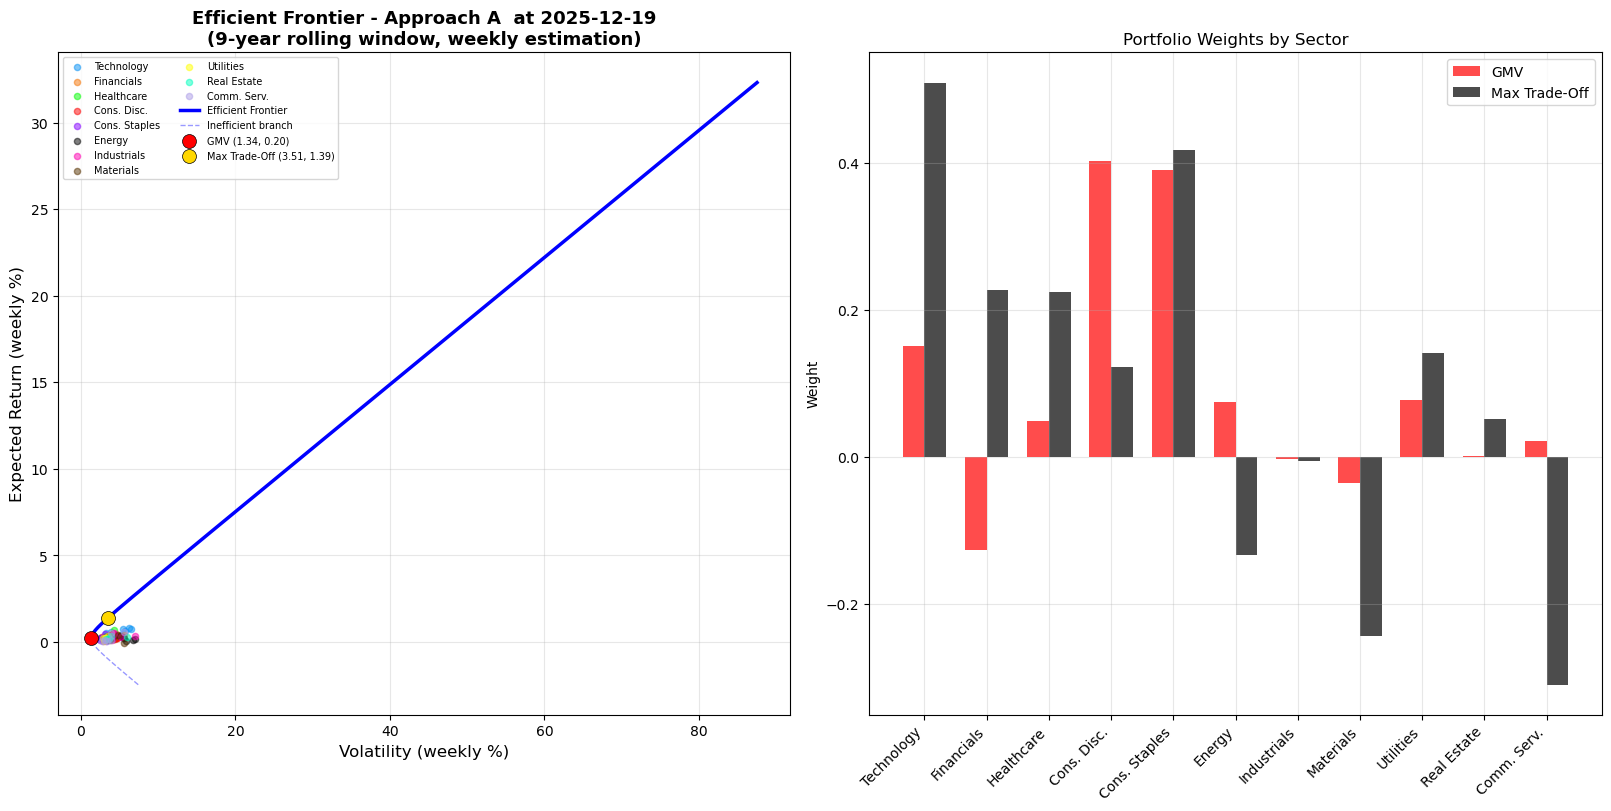

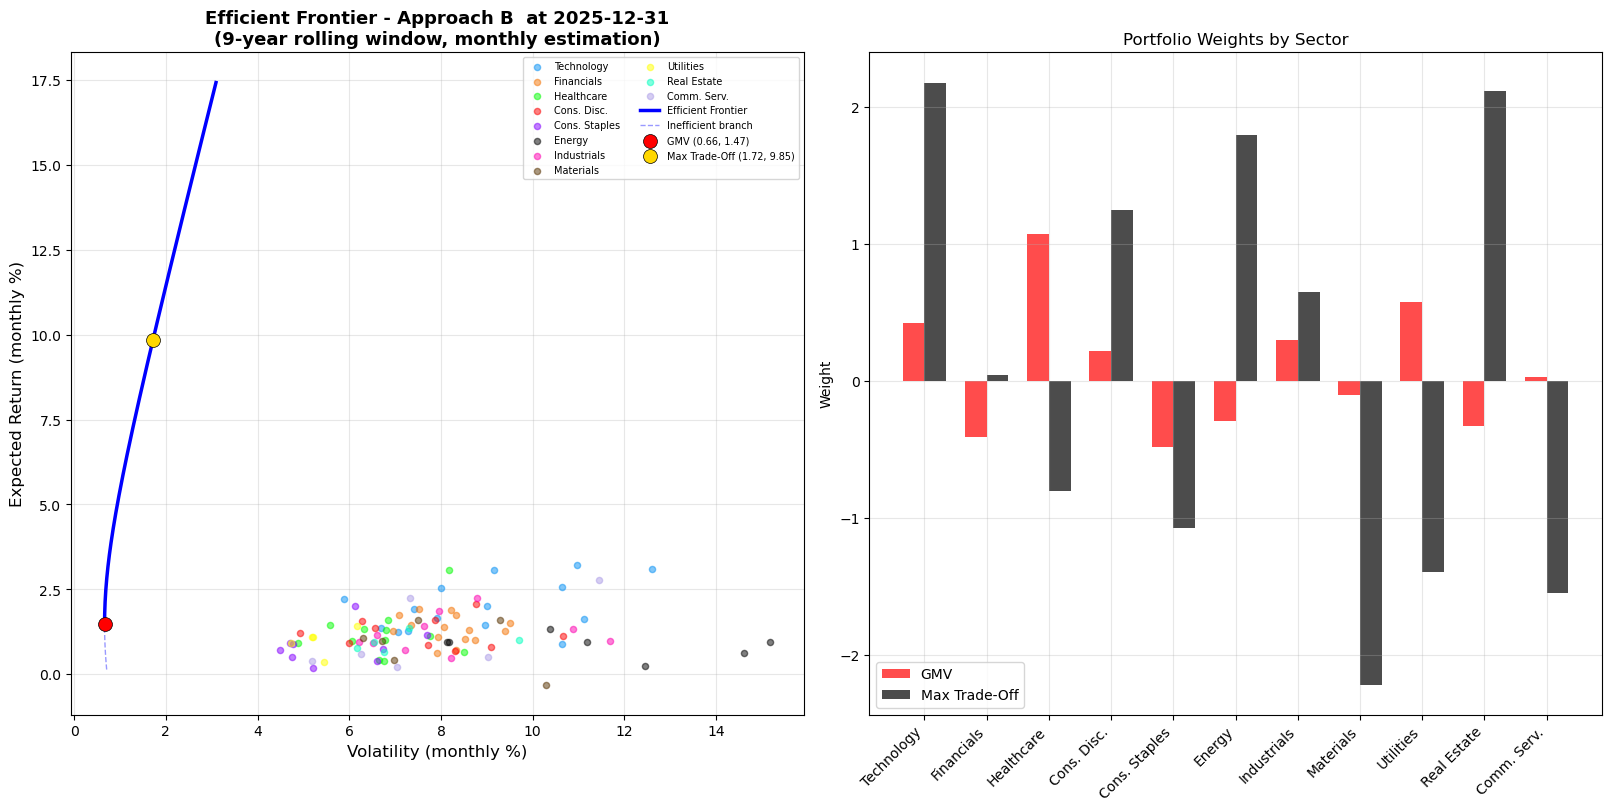

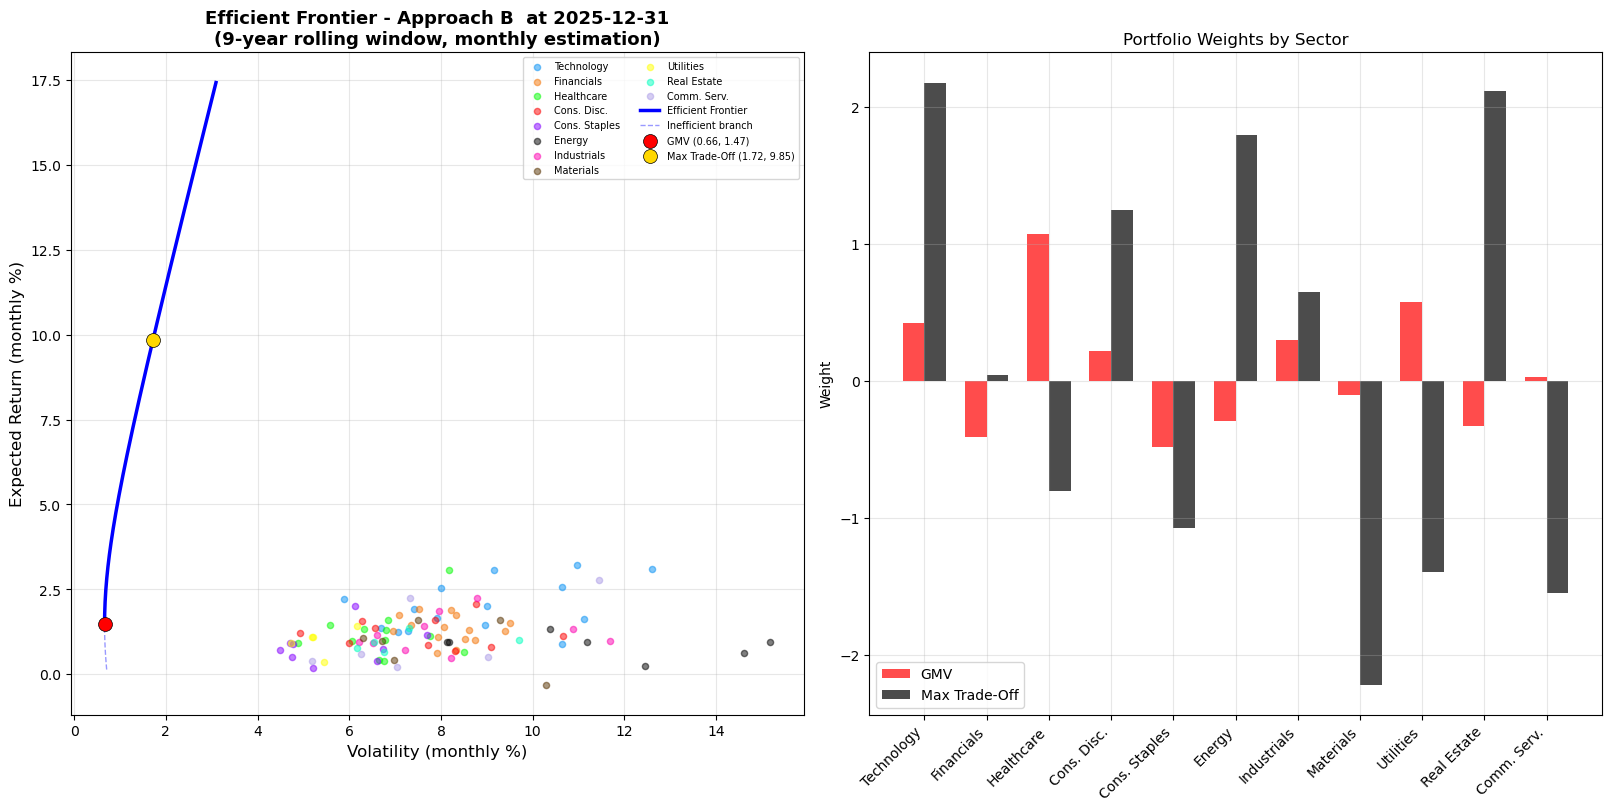

In [13]:
# =============================================================================
# STEP 9: GENERATE PLOTS
# =============================================================================
## Computing the efficent frontier at the last date--> 2025-12-31

# Approach A. With the plot frontier i will plot the efficent frontier with the last weights. 
last_A = list(rolling_mu_A.keys())[-1] # taking the last weight. 
plot_frontier_standard(rolling_mu_A[last_A], rolling_cov_A[last_A],
              weights_A_gmv[last_A], weights_A_T[last_A],
              'Approach A ', 'weekly', last_A,
              'plot_ef_A.png')


# Approach B. i will plot the efficent frontier with the last weights even for the 
last_B = list(rolling_mu_B.keys())[-1]
plot_frontier_standard(rolling_mu_B[last_B], rolling_cov_B[last_B],
              weights_B_gmv[last_B], weights_B_T[last_B],
              'Approach B ', 'monthly', last_B,
              'plot_ef_B.png')




In [14]:
# =============================================================================
# SECTOR ALLOCATION OF THE LATEST UNCONSTRAINED PORTFOLIOS
# =============================================================================
# Reuse the portfolio weights, sector_map, and sector_order already computed
# above. No portfolio weights are recomputed in this cell.

latest_portfolio_weights = {
    "Approach A - GMV": weights_A_gmv[last_A],
    "Approach A - Maximum Trade-Off": weights_A_T[last_A],
    "Approach B - GMV": weights_B_gmv[last_B],
    "Approach B - Maximum Trade-Off": weights_B_T[last_B],
}

# Each sector allocation is the sum of the individual asset weights belonging
# to that sector. Multiplying by 100 expresses the allocation in percentage.
sector_allocation_percent = pd.DataFrame(index=sector_order)

for portfolio_name, portfolio_weights in latest_portfolio_weights.items():
    sector_allocation_percent[portfolio_name] = [
        portfolio_weights.loc[
            [
                ticker
                for ticker in portfolio_weights.index
                if sector_map.get(ticker) == sector
            ]
        ].sum() * 100
        for sector in sector_order
    ]

sector_allocation_percent.index.name = "Sector"

print(f"Approach A portfolio date: {last_A.date()}")
print(f"Approach B portfolio date: {last_B.date()}")
print("\nSector allocation as a percentage of portfolio net value:")
display(sector_allocation_percent.round(2))

# The column totals should equal 100%, even when some sector allocations are
# negative because the unconstrained portfolios permit short selling.
print("\nSector-allocation totals (%):")
display(sector_allocation_percent.sum().round(6).to_frame("Total (%)"))


Approach A portfolio date: 2025-12-19
Approach B portfolio date: 2025-12-31

Sector allocation as a percentage of portfolio net value:


,Approach A - GMV,Approach A - Maximum Trade-Off,Approach B - GMV,Approach B - Maximum Trade-Off
Sector,,,,
Technology,15.02,50.89,42.21,217.99
Financials,-12.71,22.74,-40.86,4.25
Healthcare,4.86,22.43,107.27,-80.39
Cons. Disc.,40.29,12.22,22.26,124.84
Cons. Staples,38.97,41.78,-48.38,-107.32
Energy,7.43,-13.36,-29.27,179.76
Industrials,-0.25,-0.52,29.70,64.88
Materials,-3.54,-24.36,-10.13,-221.82
Utilities,7.75,14.06,57.45,-139.32



Sector-allocation totals (%):


,Total (%)
Approach A - GMV,100.0
Approach A - Maximum Trade-Off,100.0
Approach B - GMV,100.0
Approach B - Maximum Trade-Off,100.0


#### IMPLEMENTATION OF THE EXPONENTIALLY WEIGHTED MOVING AVERAGE WITH A 9-YEAR PAST-ONLY WINDOW

In [15]:

## IMPLEMENTATION OF EWMA FOR MEAN AND COVARIANCE USING PAST-ONLY ROLLING WINDOWS.

def EWMA(returns_window, Sigma_init, mu_init, lam):
    """
    EWMA estimation using the EWMA (conditional) mean for demeaning.
    we can use also values in deviations for the mean 

    
    Parameters
    ----------
    returns_window : DataFrame (T x n)
        Returns in the rolling window, ordered from oldest to newest.
    Sigma_init : DataFrame (n x n)
        Initial covariance matrix estimated from observations preceding the update window.
    mu_init : Series (n,)
        Initial mean vector estimated from observations preceding the update window.
    lam : float
        Decay parameter λ ∈ (0.9, 0.99). Default 0.97.
    
    Returns
    -------
    mu_ewma : Series (n,)
        EWMA mean vector.
    Sigma_ewma : DataFrame (n x n)
        EWMA covariance matrix (demeaned with conditional EWMA mean).
    """

    # Input = returns window; Sigma_init = covariance matrix; mu_init = vector of mean return and lam = controls the decay factor of EWMA.
    # it computes the vector with \mu_{t+1} = (1-lam ) r_t + \lam \mu_t 

    # Setting the returns window # (T × n)
    R = returns_window.values            

    # raws = return observations through time (T) and columns = assets = (n)
    T, n = R.shape 
    
    # initialize the \mu series and the covariance series. 
    mu = mu_init.values.copy()             # initialize μ_0
    Sigma = Sigma_init.values.copy()       # initialize Σ_0
    
    ## Updating the EWMA mean and covariances sequentially (at every step ) for every return observation int he rolling window.
    
    for t in range(T):
        # ------------------------------------------------------------------
        # Step 1: Demean using the OLD mean μ_{t-1} (BEFORE update!)
        # This is the prediction we had BEFORE seeing r_t
        # ------------------------------------------------------------------
        demeaned = R[t] - mu
        
        # ------------------------------------------------------------------
        # Step 2: Update covariance using the properly demeaned return
        # Σ_t = (1-λ)(r_t - μ_{t-1})(r_t - μ_{t-1})' + λ Σ_{t-1}
        # ------------------------------------------------------------------
        Sigma = (1 - lam) * np.outer(demeaned, demeaned) + lam * Sigma
        
        # ------------------------------------------------------------------
        # Step 3: NOW update the mean (AFTER using the old one)
        # μ_t = (1-λ) r_t + λ μ_{t-1}                       [slide 21]
        # ------------------------------------------------------------------
        mu = (1 - lam) * R[t] + lam * mu
    
    mu_ewma = pd.Series(mu, index=returns_window.columns)
    Sigma_ewma = pd.DataFrame(Sigma,
                              index=returns_window.columns,
                              columns=returns_window.columns)
    
    #print(mu_ewma)
    return mu_ewma, Sigma_ewma


In [16]:
# =============================================================================
# STEP 3: PAST-ONLY EWMA INITIALIZATION
# =============================================================================


# helper functions that estimates the EWMA mean and covariance using only the avaiable returns before every rebalancing dates. 
# I split the each nine-year rolling window into two parts :  At first  computes sample mean and covariance and then proceed with a 
# rolling rebalance window. 

def estimate_ewma_from_past_window(returns_window, initialization_observations, lam):
    """Estimate EWMA using only observations inside the historical rolling window."""

    # computing the return windows. sort the index from the oldest to the most recent
    returns_window = returns_window.dropna(axis=0, how="any").sort_index()

    ## adding a safety check. 
    if len(returns_window) <= initialization_observations:
        raise ValueError("The EWMA window is too short for the requested initialization.")
    
    # selecting the first 9 year window span and computes the avarage. 
    initialization_window = returns_window.iloc[:initialization_observations]
    mu_init = initialization_window.mean()

    
    # computes the sample variance of each asset using the initialization period. use bressel correction. --> sample variance estimate. 
    initial_variances = initialization_window.var(ddof=1)

    ## create a very small positive minimum variance. this is necessary for the numerical stability. 
    variance_floor = max(float(initial_variances.median()) * 1e-8, 1e-12)

    ## replece every variance smaller than variance floor with variance floor. Necessary for numerical stability. 
    initial_variances = initial_variances.clip(lower=variance_floor)

    # Build the initial covariance matrix. 
    Sigma_init = pd.DataFrame(
        np.diag(initial_variances.to_numpy()),# place each asset variance on the diagonal and puts zero everywhere else. 
        index=returns_window.columns,
        columns=returns_window.columns,
    )

    ## selecting all the observaitons after the initialization block.
    update_window = returns_window.iloc[initialization_observations:]

    ## runs the EWMA procedurre. 
    return EWMA(update_window, Sigma_init, mu_init, lam=lam)


# =============================================================================
# STEP 4: ROLLING EWMA ESTIMATION
# =============================================================================

## We set the lambda both for weekly and monthly return at a 0.97 level which is an appropiate level. 
lam = 0.97 

# --- APPROACH A: WEEKLY ---
print("\n" + "=" * 70)
print(f"APPROACH A (EWMA): WEEKLY RETURNS, lambda = {lam}")
print("=" * 70)

rolling_mu_A_ewma = {} ## this dictionares contains the rolling window for the mean with EWMA for the approach A 
rolling_cov_A_ewma = {} ## this dictionares contains the rolling window for the var/cov with EWMA for the approach A 

## initialize the rolling procedure in the case of the EWMA. 

for date in rebalancing_dates_A:
    history = weekly_estimation_windows[date]
    window = history.iloc[-WEEKLY_WINDOW_OBS:]
    mu_ewma, Sigma_ewma = estimate_ewma_from_past_window(window, 52, lam)
    rolling_mu_A_ewma[date] = mu_ewma
    rolling_cov_A_ewma[date] = Sigma_ewma

print(f"Number of estimates: {len(rolling_mu_A_ewma)}")

# --- APPROACH B: MONTHLY ---
print(f"\nAPPROACH B (EWMA): MONTHLY RETURNS, lambda = {lam}")
print("=" * 70)

rolling_mu_B_ewma = {}
rolling_cov_B_ewma = {}

for date in rebalancing_dates:
    history = monthly_return.loc[monthly_return.index < date].dropna(axis=0, how="any")
    window = history.iloc[-MONTHLY_WINDOW_OBS:]
    mu_ewma, Sigma_ewma = estimate_ewma_from_past_window(window, 12, lam)
    rolling_mu_B_ewma[date] = mu_ewma
    rolling_cov_B_ewma[date] = Sigma_ewma

print(f"Number of estimates: {len(rolling_mu_B_ewma)}")


APPROACH A (EWMA): WEEKLY RETURNS, lambda = 0.97
Number of estimates: 162

APPROACH B (EWMA): MONTHLY RETURNS, lambda = 0.97
Number of estimates: 148


In [17]:
# =============================================================================
# STEP 5: DIAGNOSTIC CHECK
# =============================================================================

print("\n" + "=" * 70)
print("DIAGNOSTIC CHECK: EWMA COVARIANCE MATRICES")
print("=" * 70)

test_A = list(rolling_cov_A_ewma.keys())[0]
Sig_A = rolling_cov_A_ewma[test_A].values
print(f"\nApproach A (EWMA, λ={lam}):")
print(f"  Matrix rank:      {np.linalg.matrix_rank(Sig_A)}")
print(f"  Condition number: {np.linalg.cond(Sig_A):.2e}")
id_A = Sig_A @ np.linalg.inv(Sig_A)
print(f"  Σ × Σ⁻¹ deviation: {np.max(np.abs(id_A - np.eye(Sig_A.shape[0]))):.10f}")

test_B = list(rolling_cov_B_ewma.keys())[0]
Sig_B = rolling_cov_B_ewma[test_B].values
print(f"\nApproach B (EWMA, λ={lam}):")
print(f"  Matrix rank:      {np.linalg.matrix_rank(Sig_B)}")
print(f"  Condition number: {np.linalg.cond(Sig_B):.2e}")
id_B = Sig_B @ np.linalg.inv(Sig_B)
print(f"  Σ × Σ⁻¹ deviation: {np.max(np.abs(id_B - np.eye(Sig_B.shape[0]))):.10f}")


DIAGNOSTIC CHECK: EWMA COVARIANCE MATRICES

Approach A (EWMA, λ=0.97):
  Matrix rank:      100
  Condition number: 6.15e+03
  Σ × Σ⁻¹ deviation: 0.0000000000

Approach B (EWMA, λ=0.97):
  Matrix rank:      100
  Condition number: 2.75e+03
  Σ × Σ⁻¹ deviation: 0.0000000000


In [18]:
# =============================================================================
# STEP 6: OPTIMIZATION LOOP
# =============================================================================
# Report some info about the optimziation process. 
# --- APPROACH A ---
print("\n" + "=" * 70)
print("OPTIMIZATION: APPROACH A (WEEKLY + EWMA)")
print("=" * 70)

results_A_gmv_ewma = []
results_A_T_ewma = []
weights_A_gmv_ewma = {}
weights_A_T_ewma = {}

for date in rolling_mu_A_ewma.keys():
    mu = rolling_mu_A_ewma[date]
    Sigma = rolling_cov_A_ewma[date]
    
    # GMV
    w_gmv, ret_gmv, std_gmv = gmv_portfolio(mu, Sigma)
    weights_A_gmv_ewma[date] = w_gmv
    results_A_gmv_ewma.append({
        'Date': date, 
        'Return': ret_gmv,
        'Volatility': std_gmv, 
        'Variance': std_gmv ** 2
    })
    
    # Max Trade-Off
    w_T, ret_T, std_T = max_tradeoff_portfolio(mu, Sigma)
    weights_A_T_ewma[date] = w_T
    results_A_T_ewma.append({
        'Date': date, 
        'Return': ret_T, 
        'Volatility': std_T,
        'Variance': std_T ** 2
    })

df_results_A_gmv_ewma = pd.DataFrame(results_A_gmv_ewma).set_index('Date')
df_results_A_T_ewma = pd.DataFrame(results_A_T_ewma).set_index('Date')

print(f"\nGMV Portfolio (Approach A, EWMA):")
print(f"  Average expected return: {df_results_A_gmv_ewma['Return'].mean():.4f}%")
print(f"  Average volatility:     {df_results_A_gmv_ewma['Volatility'].mean():.4f}%")
print(f"\nMax Trade-Off Portfolio (Approach A, EWMA):")
print(f"  Average expected return: {df_results_A_T_ewma['Return'].mean():.4f}%")
print(f"  Average volatility:     {df_results_A_T_ewma['Volatility'].mean():.4f}%")

# --- APPROACH B ---
print("\n" + "=" * 70)
print("OPTIMIZATION: APPROACH B (MONTHLY + EWMA)")
print("=" * 70)

results_B_gmv_ewma = []
results_B_T_ewma = []
weights_B_gmv_ewma = {}
weights_B_T_ewma = {}

for date in rolling_mu_B_ewma.keys():
    mu = rolling_mu_B_ewma[date]
    Sigma = rolling_cov_B_ewma[date]
    
    # GMV
    w_gmv, ret_gmv, std_gmv = gmv_portfolio(mu, Sigma)
    ret_gmv = w_gmv @ mu
    weights_B_gmv_ewma[date] = w_gmv
    results_B_gmv_ewma.append({
        'Date': date, 'Return': ret_gmv,
        'Volatility': std_gmv, 'Variance': std_gmv ** 2
    })
    
    # Max Trade-Off
    w_T, ret_T, std_T = max_tradeoff_portfolio(mu, Sigma)
    weights_B_T_ewma[date] = w_T
    results_B_T_ewma.append({
        'Date': date, 'Return': ret_T, 'Volatility': std_T
    })

df_results_B_gmv_ewma = pd.DataFrame(results_B_gmv_ewma).set_index('Date')
df_results_B_T_ewma = pd.DataFrame(results_B_T_ewma).set_index('Date')

print(f"\nGMV Portfolio (Approach B, EWMA):")
print(f"  Average expected return: {df_results_B_gmv_ewma['Return'].mean():.4f}%")
print(f"  Average volatility:     {df_results_B_gmv_ewma['Volatility'].mean():.4f}%")
print(f"\nMax Trade-Off Portfolio (Approach B, EWMA):")
print(f"  Average expected return: {df_results_B_T_ewma['Return'].mean():.4f}%")
print(f"  Average volatility:     {df_results_B_T_ewma['Volatility'].mean():.4f}%")



OPTIMIZATION: APPROACH A (WEEKLY + EWMA)

GMV Portfolio (Approach A, EWMA):
  Average expected return: 0.2148%
  Average volatility:     0.5025%

Max Trade-Off Portfolio (Approach A, EWMA):
  Average expected return: 5.6881%
  Average volatility:     4.7755%

OPTIMIZATION: APPROACH B (MONTHLY + EWMA)

GMV Portfolio (Approach B, EWMA):
  Average expected return: 1.2226%
  Average volatility:     1.1649%

Max Trade-Off Portfolio (Approach B, EWMA):
  Average expected return: 4.1936%
  Average volatility:     2.1791%


In [19]:
print(f"the result of the gmw with exponential weighted moving avarage is (APPROACH A ):\n {df_results_A_gmv_ewma}")
print(F" the results of the maximum tradeoff with exponential weighted moving avarage are (APPROACH A ):\n  {df_results_A_T_ewma }")
print(f" the results of the gmw with exponential weighted moving avarage is (APPROACH B) : \n {df_results_B_gmv_ewma} ")
print(f"the results of the maximum tradeoff with exponential weighted moving avarage is (APPROACH B ) : \n{df_results_B_T_ewma}")

# the value are the same between weekly and montly. Ask the professor. 

the result of the gmw with exponential weighted moving avarage is (APPROACH A ):
                              Return  Volatility  Variance
Date                                                     
2013-08-16 00:00:00+00:00  0.133659    0.519779  0.270171
2013-09-13 00:00:00+00:00  0.014848    0.581855  0.338555
2013-10-11 00:00:00+00:00 -0.014625    0.568906  0.323654
2013-11-08 00:00:00+00:00  0.033112    0.562762  0.316701
2013-12-06 00:00:00+00:00 -0.008252    0.554100  0.307027
...                             ...         ...       ...
2025-08-29 00:00:00+00:00  0.247292    0.508257  0.258325
2025-09-26 00:00:00+00:00  0.236649    0.492522  0.242578
2025-10-24 00:00:00+00:00  0.236373    0.467926  0.218954
2025-11-21 00:00:00+00:00  0.279357    0.471897  0.222687
2025-12-19 00:00:00+00:00  0.236181    0.466539  0.217658

[162 rows x 3 columns]
 the results of the maximum tradeoff with exponential weighted moving avarage are (APPROACH A ):
                                 Return  Vo

In [20]:
# =============================================================================
# STEP 7: WEIGHT INSPECTION
# =============================================================================

print("\n" + "=" * 70)
print("WEIGHT INSPECTION (EWMA) — LATEST REBALANCING DATE")
print("=" * 70)

# Approach A
last_A = list(weights_A_gmv_ewma.keys())[-1]
w_gmv_A = weights_A_gmv_ewma[last_A]
w_T_A = weights_A_T_ewma[last_A]

print(f"\nApproach A (EWMA) at {last_A.date()}:")
print(f"\n  GMV — Top 5 weights:")
print(w_gmv_A.nlargest(5).round(4))
print(f"\n  GMV — Bottom 5 weights:")
print(w_gmv_A.nsmallest(5).round(4))
print(f"  GMV — Sum: {w_gmv_A.sum():.6f}")
print(f"  GMV — Long: {(w_gmv_A > 0).sum()}, Short: {(w_gmv_A < 0).sum()}")
print(f"  GMV — Gross leverage: {w_gmv_A.abs().sum():.4f}")

print(f"\n  Max Trade-Off — Top 5 weights:")
print(w_T_A.nlargest(5).round(4))
print(f"\n  Max Trade-Off — Bottom 5 weights:")
print(w_T_A.nsmallest(5).round(4))
print(f"  Max Trade-Off — Sum: {w_T_A.sum():.6f}")
print(f"  Max Trade-Off — Gross leverage: {w_T_A.abs().sum():.4f}")

# Approach B
last_B = list(weights_B_gmv_ewma.keys())[-1]
w_gmv_B = weights_B_gmv_ewma[last_B]
w_T_B = weights_B_T_ewma[last_B]

print(f"\nApproach B (EWMA) at {last_B.date()}:")
print(f"\n  GMV — Top 5 weights:")
print(w_gmv_B.nlargest(5).round(4))
print(f"\n  GMV — Bottom 5 weights:")
print(w_gmv_B.nsmallest(5).round(4))
print(f"  GMV — Sum: {w_gmv_B.sum():.6f}")
print(f"  GMV — Long: {(w_gmv_B > 0).sum()}, Short: {(w_gmv_B < 0).sum()}")
print(f"  GMV — Gross leverage: {w_gmv_B.abs().sum():.4f}")

print(f"\n  Max Trade-Off — Top 5 weights:")
print(w_T_B.nlargest(5).round(4))
print(f"\n  Max Trade-Off — Bottom 5 weights:")
print(w_T_B.nsmallest(5).round(4))
print(f"  Max Trade-Off — Sum: {w_T_B.sum():.6f}")
print(f"  Max Trade-Off — Gross leverage: {w_T_B.abs().sum():.4f}")


WEIGHT INSPECTION (EWMA) — LATEST REBALANCING DATE

Approach A (EWMA) at 2025-12-19:

  GMV — Top 5 weights:
MO.N     0.1982
KO.N     0.1870
TJX.N    0.1774
BK.N     0.1430
DUK.N    0.1371
dtype: float64

  GMV — Bottom 5 weights:
SHW.N   -0.1463
SPG.N   -0.1350
PSA.N   -0.1285
BLK.N   -0.1239
GS.N    -0.1111
dtype: float64
  GMV — Sum: 1.000000
  GMV — Long: 55, Short: 45
  GMV — Gross leverage: 5.5354

  Max Trade-Off — Top 5 weights:
SO.N     1.6223
MO.N     1.3352
WFC.N    1.2029
TJX.N    1.1701
CAT.N    0.8050
dtype: float64

  Max Trade-Off — Bottom 5 weights:
BAC.N   -1.3447
JPM.N   -1.1910
DUK.N   -0.9018
PEP.O   -0.7988
MS.N    -0.7623
dtype: float64
  Max Trade-Off — Sum: 1.000000
  Max Trade-Off — Gross leverage: 33.6872

Approach B (EWMA) at 2025-12-31:

  GMV — Top 5 weights:
GILD.O    0.2057
JPM.N     0.2042
TFC.N     0.1989
MSFT.O    0.1690
INTU.O    0.1605
dtype: float64

  GMV — Bottom 5 weights:
SPG.N   -0.1760
MMM.N   -0.1681
BAC.N   -0.1627
TMO.N   -0.1318
BLK.N   

In [21]:
# =============================================================================
# STEP 8: EFFICIENT FRONTIER FUNCTIONS
# =============================================================================

## Same functioning of the previous efficent frontier function. 


def efficient_frontier(mu, Sigma, n_points=100):
    """Trace the efficient frontier using the closed-form parabola."""
    mu_vec = mu.values if isinstance(mu, pd.Series) else mu
    Sigma_mat = Sigma.values if isinstance(Sigma, pd.DataFrame) else Sigma
    n = len(mu_vec)
    ones = np.ones(n)
    
    Sigma_inv = np.linalg.inv(Sigma_mat)
    
    A = mu_vec @ Sigma_inv @ mu_vec
    B = ones @ Sigma_inv @ mu_vec
    C = ones @ Sigma_inv @ ones
    D = A * C - B**2
    
    if D <= 1e-10 or C <= 1e-10:
        return None, None
    
    mu_gmv = B / C
    mu_min = mu_gmv - 2 * np.sqrt(1/C) # this is the lower branch. we care less about it because they are not dominated 
    mu_max = mu_gmv + 12 * np.sqrt(1/C) ## upper branch of the frontier. this are efficent portfolios. 
    target_returns = np.linspace(mu_min, mu_max, n_points)
    
    variances = (C * target_returns**2 - 2 * B * target_returns + A) / D # this is the formula present in the slide 
    variances = np.maximum(variances, 0) # compare 2 arrays and return a new array containing the element-wise maxima.
    vols = np.sqrt(variances) # standard deviation. 
    
    return vols, target_returns


# Sector mapping
sector_map = {
    'AAPL.O': 'Technology', 'MSFT.O': 'Technology', 'IBM.N': 'Technology',
    'ORCL.N': 'Technology', 'CSCO.O': 'Technology', 'INTC.O': 'Technology',
    'TXN.O': 'Technology', 'QCOM.O': 'Technology', 'ADI.O': 'Technology',
    'ADBE.O': 'Technology', 'INTU.O': 'Technology', 'KLAC.O': 'Technology',
    'AMAT.O': 'Technology', 'MU.O': 'Technology', 'LRCX.O': 'Technology',
    'JPM.N': 'Financials', 'BAC.N': 'Financials', 'WFC.N': 'Financials',
    'C.N': 'Financials', 'GS.N': 'Financials', 'MS.N': 'Financials',
    'USB.N': 'Financials', 'PNC.N': 'Financials', 'TFC.N': 'Financials',
    'BK.N': 'Financials', 'STT.N': 'Financials', 'AXP.N': 'Financials',
    'BLK.N': 'Financials', 'SCHW.N': 'Financials', 'COF.N': 'Financials',
    'JNJ.N': 'Healthcare', 'UNH.N': 'Healthcare', 'PFE.N': 'Healthcare',
    'LLY.N': 'Healthcare', 'TMO.N': 'Healthcare', 'ABT.N': 'Healthcare',
    'MRK.N': 'Healthcare', 'DHR.N': 'Healthcare', 'BMY.N': 'Healthcare',
    'AMGN.O': 'Healthcare', 'GILD.O': 'Healthcare', 'CVS.N': 'Healthcare',
    'AMZN.O': 'Cons. Disc.', 'HD.N': 'Cons. Disc.', 'MCD.N': 'Cons. Disc.',
    'NKE.N': 'Cons. Disc.', 'LOW.N': 'Cons. Disc.', 'SBUX.O': 'Cons. Disc.',
    'TGT.N': 'Cons. Disc.', 'TJX.N': 'Cons. Disc.', 'F.N': 'Cons. Disc.',
    'TM': 'Cons. Disc.',
    'KR.N': 'Cons. Staples', 'PG.N': 'Cons. Staples', 'KO.N': 'Cons. Staples',
    'PEP.O': 'Cons. Staples', 'COST.O': 'Cons. Staples', 'CLX.N': 'Cons. Staples',
    'MO.N': 'Cons. Staples', 'CL.N': 'Cons. Staples', 'GIS.N': 'Cons. Staples',
    'XOM.N': 'Energy', 'CVX.N': 'Energy', 'COP.N': 'Energy',
    'EOG.N': 'Energy', 'SLB.N': 'Energy', 'HAL.N': 'Energy', 'OXY.N': 'Energy',
    'BA.N': 'Industrials', 'HON.O': 'Industrials', 'UNP.N': 'Industrials',
    'UPS.N': 'Industrials', 'CAT.N': 'Industrials', 'GE.N': 'Industrials',
    'MMM.N': 'Industrials', 'LMT.N': 'Industrials', 'RTX.N': 'Industrials',
    'DE.N': 'Industrials',
    'PPG.N': 'Materials', 'APD.N': 'Materials', 'SHW.N': 'Materials',
    'ECL.N': 'Materials', 'NEM.N': 'Materials', 'FMC.N': 'Materials',
    'NEE.N': 'Utilities', 'DUK.N': 'Utilities', 'SO.N': 'Utilities',
    'D.N': 'Utilities', 'EXC.O': 'Utilities',
    'PLD.N': 'Real Estate', 'AMT.N': 'Real Estate', 'CCI.N': 'Real Estate',
    'PSA.N': 'Real Estate', 'SPG.N': 'Real Estate',
    'GOOGL.O': 'Comm. Serv.', 'NFLX.O': 'Comm. Serv.', 'DIS.N': 'Comm. Serv.',
    'CMCSA.O': 'Comm. Serv.', 'VZ.N': 'Comm. Serv.', 'T.N': 'Comm. Serv.'
}

sector_order = ['Technology', 'Financials', 'Healthcare', 'Cons. Disc.',
                'Cons. Staples', 'Energy', 'Industrials', 'Materials',
                'Utilities', 'Real Estate', 'Comm. Serv.']

sector_colors = {
    'Technology': "#0791f4", 'Financials': "#f47506", 'Healthcare': "#02fc02",
    'Cons. Disc.': "#fc0000", 'Cons. Staples': "#8402fe", 'Energy': "#000000",
    'Industrials': "#fd00b1", 'Materials': "#573200", 'Utilities': "#ffff00",
    'Real Estate': "#00ffbf", 'Comm. Serv.': "#ac9de7"
}


def plot_frontier(mu, Sigma, w_gmv, w_T, approach_label, freq_label, date, filename):
    """Plot efficient frontier with stocks, GMV and Max Trade-Off."""
    
    ef_vols, ef_rets = efficient_frontier(mu, Sigma) #efficent volatility and efficent returns
    
    ret_gmv = w_gmv @ mu ## return of the global minimum variance 
    vol_gmv = np.sqrt(max(w_gmv @ Sigma @ w_gmv, 0)) ## variance of the global minimum variance 
    
    ret_T = w_T @ mu # return in the case of the maximum tradeoff portfolios 
    vol_T = np.sqrt(max(w_T @ Sigma @ w_T, 0))## volatility in the case for maximum trade-offs portfolios. 
    
    stock_vols = np.sqrt(np.maximum(np.diag(Sigma.values), 0))## the volatility are in the diagonal of the covariance matrix. This calculate the stock volatilities. 
    stock_rets = mu.values # this calculates the stock return
    
    fig, (ax1, ax2) = plt.subplots(1,2, figsize=(16, 8), layout='constrained')## 1,2 represents the number of raws and the number of columns.
    # layout = contrained fits the plot within your figure clearly.  
    
    # Individual stocks colored by sector
    ## check this for cycle because it's very complicate.
    for sector in sector_order:
        tickers_in_sector = [t for t in sector_map if sector_map[t] == sector and t in mu.index] # mu.index take the index of this 
        if tickers_in_sector:
            idx = [list(mu.index).index(t) for t in tickers_in_sector]
            ax1.scatter(stock_vols[idx], stock_rets[idx], ## this is the scatter plot. x = stock[vols], y = stock_rets[idx]
                       color=sector_colors[sector], s=20, alpha=0.5, # s = float or array like. represents the marker size in points**2.
                       label=sector, zorder=2)
                        # alpha = The alpha blending value, between 0 (transparent) and 1 (opaque). label = 
                        # zorder = Set the zorder for the artist. Artists with lower zorder values are drawn first. The artist are the foundamental structure for plottin
    
    


    # Efficient frontier
    # efficent frontier is an array. 
    if ef_vols is not None:
        upper = ef_rets >= ret_gmv # the upper branch are the array above the return of the global minimum variance 
        lower = ef_rets < ret_gmv # the lower  branch of the return of the global minimum return 
        ax1.plot(ef_vols[upper], ef_rets[upper], # plotting the upper of efficent volatilities. b- is printing with a blue solid line. linewidth = width of the line. 
                'b-', linewidth=2.5, label='Efficient Frontier', zorder=3)
        ax1.plot(ef_vols[lower], ef_rets[lower],
                'b--', linewidth=1, alpha=0.4, label='Inefficient branch', zorder=3)
    
    # GMV and Max Trade-Off stars. printing the gmv and maximum trade-off star. 
    ax1.scatter(vol_gmv, ret_gmv, color='red', marker='o', s=100, zorder=5,
               edgecolors='black', linewidth=0.5,
               label=f'GMV ({vol_gmv:.2f}, {ret_gmv:.2f})')# x = vol_gmv. y = ret_gmv. edgecolors = the edgecolor of the marker 
    ax1.scatter(vol_T, ret_T, color='gold', marker='o', s=100, zorder=5,
               edgecolors='black', linewidth=0.5,
               label=f'Max Trade-Off ({vol_T:.2f}, {ret_T:.2f})')
    
    ax1.set_xlabel(f'Volatility ({freq_label} %)', fontsize=12)
    ax1.set_ylabel(f'Expected Return ({freq_label} %)', fontsize=12)
    ax1.set_title(f'Efficient Frontier - {approach_label} at {date.date()}\n'
                 f'({ESTIMATION_WINDOW_YEARS}-year rolling window, EWMA lambda={lam}, {freq_label} estimation)',
                 fontsize=13, fontweight='bold')
    
    ax1.legend(loc='upper left', fontsize=7, ncol=2) # ncol = 2 number of the columns that the legend should  have 
    ax1.grid(True, alpha=0.3)

    # Compute sector weights of gmv and maximum tradeoff for the sector weights
    # Controls the for cycle for understanding what it does.  
    sector_weights_gmv = {}
    sector_weights_T = {}
    for sector in sector_order:
        tickers_gmv = [t for t in sector_map if sector_map[t] == sector and t in w_gmv.index]
        sector_weights_gmv[sector] = w_gmv[tickers_gmv].sum() if tickers_gmv else 0
        tickers_T = [t for t in sector_map if sector_map[t] == sector and t in w_T.index]
        sector_weights_T[sector] = w_T[tickers_T].sum() if tickers_T else 0

    # Bar chart for weights
    positions = np.arange(len(sector_order))
    width = 0.35
    ax2.bar(positions - width/2, list(sector_weights_gmv.values()), width, label='GMV', alpha=0.7, color='red')# the height is given by the gmv.values and the width = 0.35 
    ax2.bar(positions + width/2, list(sector_weights_T.values()), width, label='Max Trade-Off', alpha=0.7, color='black')
    ax2.set_xticks(positions) # setting the x axis tick labels with list of string labels. 
    ax2.set_xticklabels(sector_order, rotation=45, ha='right') ## setting the xticklabel with a list of string. 
    ax2.set_ylabel('Weight')
    ax2.set_title('Portfolio Weights by Sector')
    ax2.legend()
    ax2.grid(True, alpha=0.3)

    plt.tight_layout() # adjust the padding between and around subplots.
    plt.savefig(
    filename,
    dpi=300,
    bbox_inches="tight"
) 
    plt.show()

    


 
    


EFFICIENT FRONTIER PLOTS (EWMA)


/var/folders/5c/269t06rj1d14f579s223j9s00000gn/T/ipykernel_2891/1786508404.py:169: UserWarning: The figure layout has changed to tight
  plt.tight_layout() # adjust the padding between and around subplots.


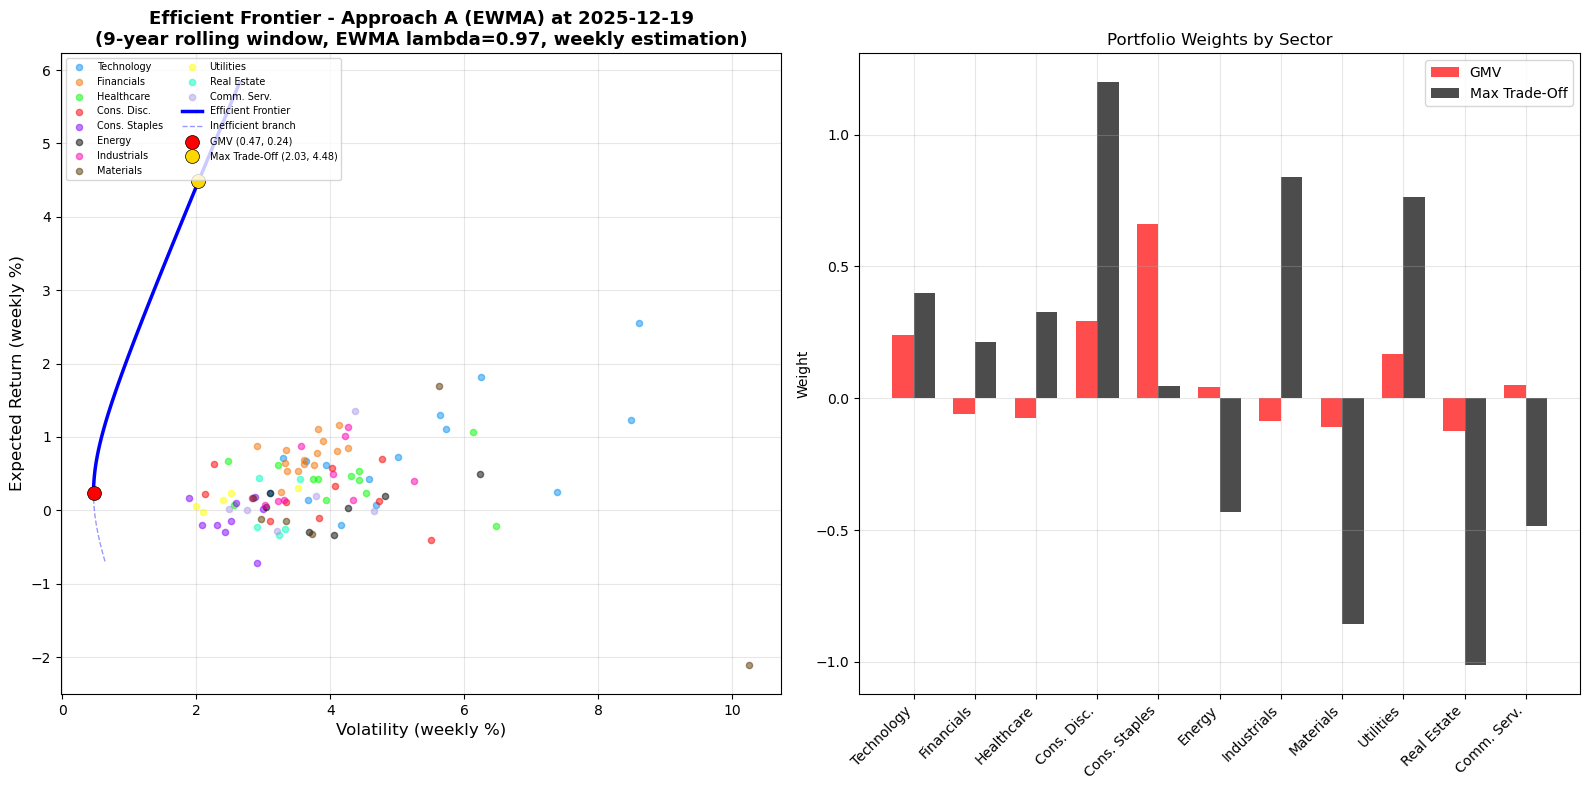

/var/folders/5c/269t06rj1d14f579s223j9s00000gn/T/ipykernel_2891/1786508404.py:169: UserWarning: The figure layout has changed to tight
  plt.tight_layout() # adjust the padding between and around subplots.


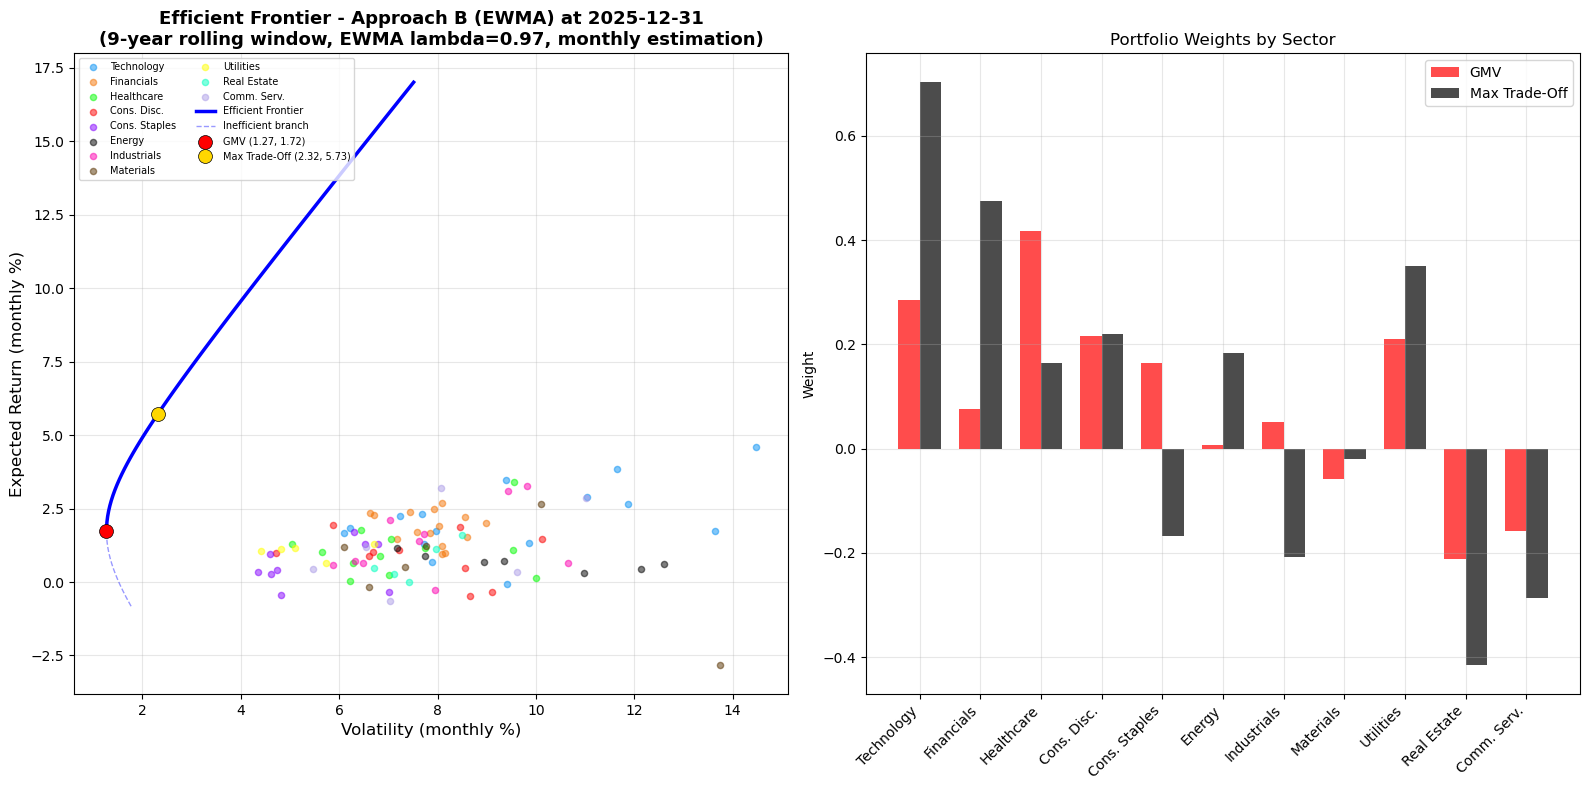

In [22]:
# =============================================================================
# STEP 9: GENERATE PLOTS
# =============================================================================

print("\n" + "=" * 70)
print("EFFICIENT FRONTIER PLOTS (EWMA)")
print("=" * 70)

# Approach A. With the plot frontier i will plot the efficent frontier with the last weights. 
last_A = list(rolling_mu_A_ewma.keys())[-1] # taking the last weight. 
plot_frontier(rolling_mu_A_ewma[last_A], rolling_cov_A_ewma[last_A],
              weights_A_gmv_ewma[last_A], weights_A_T_ewma[last_A],
              'Approach A (EWMA)', 'weekly', last_A,
              'plot_ef_A_ewma.png')

# Approach B. i will plot the efficent frontier with the last weights even for the 
last_B = list(rolling_mu_B_ewma.keys())[-1]
plot_frontier(rolling_mu_B_ewma[last_B], rolling_cov_B_ewma[last_B],
              weights_B_gmv_ewma[last_B], weights_B_T_ewma[last_B],
              'Approach B (EWMA)', 'monthly', last_B,
              'plot_ef_B_ewma.png')


### CONSTRAINED  MARKOWITZ MODEL 

Here we begin  with constrained of the markowitz model.  
The first constrained that we impose is the positivy of the weigths will result in the following problem :
$$\min_{w} \quad w^\top \Sigma w$$

$$\text{s.t.} \quad \mu_p = w^\top \mu$$

$$\quad \quad \quad w^\top \mathbf{1}_n = 1$$

$$w_i > 0 \quad \text{with i = 0,1,2}$$

Given the positivity of the constraints (or no-short selling constrained ) an analytical solution does not exist. The vector of optimal weights must be estimated using the numerical methods (through he use of the numerical optimization algorithm.) All the weights must be between 0 and 1. 
Doing this the effient frontier is bounded. upper bound --> we allocate 100% in the asset with the highest expected return.   
The efficent lower bound is given by the maximum of the two possible allocations : the first investing in 100 % in the minimum expected return, the second given the minimum variance portfolios under no short selling.  
We can introduce also un upper bound to a single position so we have $ 0 \le w_i \le u_i$ and in general the upper-bound is specific. The number of u needs to be associated with the number of asset/positions included in the allocation model (n)

Under no-short ---> reference point is the equally weighted portfolios, that has maximum diversification  and for measuring the distance from EW we use : 
$$ DI = \sum_{j=1}^{n} \left| \omega_i - \frac{1}{n} \right|^q$$

We can impose both a lower contrained in the upper and lower bound :  
$$\min_{w} \quad w^\top \Sigma w$$

$$\text{s.t.} \quad \mu_p = w^\top \mu$$

$$\quad \quad \quad w^\top \mathbf{1}_n = 1$$

$$ l_i< w_i < u_i \quad \text{with i = 1,2,..n}$$




A different type of portfolio constraints can be recast into a set of inequalities; so we have to solve the following problem : 

$$\min_{w} \quad w^\top \Sigma w$$

$$\text{s.t.} \quad \mu_p = w^\top \mu$$

$$\quad \quad \quad w^\top \mathbf{1}_n = 1$$

$$\text{H} \omega = \text{h} \quad \text{or} \quad \textbf{I} <= \textbf{H}*w <= h $$

where H as size q x n and **h** and **I** have size qx1 with q lienar contraint. 

we can impose equality between 2 country weights, impose upper/lower bound on a specific sector weights, impose a specific weight weigths to a given geographical area. 
The problem allow the presence of both bounds and linear constrained. More constraiend --> more complex the efficent frontier becomes. 
Note that setting complex efficent frontier the target return could not be reached ---> very important. 



In [23]:
### IMPOSING THE CONSTRAINED MARKOTIA MODEL.
### THE USE THE CVXPY PACKAGE TO SOLVE THE CONSTRAINED MARKOWITZ OPTIMIZATION PROBLEM.
### The code also include the ability to impose upper or lower bounds on portfolio weigths. 

def constrained_markowitz(
    mu, Sigma,
    target_return=None,
    l = 0.0, # we can change this value for allowing a bit of short-selling for example.
    u = 1.0,
    H_eq=None,  h_eq=None, # this allow us to settle the exposures to a country/sector or geographical area as we want i.e. financial sector = max 30% 
    H_ineq=None, h_ineq=None, # i think i can remove  this part.
    ):
    """
    Solve the  constrained Markowitz minimum-variance problem with cvxpy. we use the cvxpy package

    Parameters
    ----------
    mu            : array-like (n,)    expected returns
    Sigma         : array-like (n,n)   covariance matrix
    target_return : float, optional    return target
    u             : float              per-asset upper bound (default 1.0)
    H_eq, h_eq    : optional           H_eq  w = h_eq   (general equality)
    H_ineq,h_ineq : optional           H_ineq w <= h_ineq (general inequality)
    x0            : optional           kept for compatibility; not needed by cvxpy

    Returns
    -------
    w             : np.ndarray (n,)
    port_return   : float
    port_variance : float
    port_std      : float
    result        : SimpleNamespace with success, status, message and problem
    """

    ## Initialize the input parameter. 

    ## convert the input to a numpy an array. mu = expected returns 
    mu_arr    = np.asarray(mu,    dtype=float) 

    ## sigma is the covariance matrix
    Sigma_arr = np.asarray(Sigma, dtype=float)

    ## take the same lenghts of the vector of expected return 
    n = len(mu_arr)
     
    # This create the variable that our optimizier needs to solve. it creates the unknown portfolio-weigth vector that CVXPY must 
    ## determine  solving the contrained markwoitz optimization problem. n = number of assets. 
    # create n unkown decision variables, one portfolio weights for each asset. 
    w = cp.Variable(n) 

    # Objective: portfolio variance (quadratic, convex)
    # this represetns w\Sigmaw to be minimized
    #cp.quad_form = x vector argument, y = matrix argument. 
    objective = cp.Minimize(cp.quad_form(w, cp.psd_wrap(Sigma_arr))) #psd_wrap Asserts that a square matrix is PSD.

    # REMEBER NEED TO CHANGE THE POSITIVITY CONTRAINT SO WE CAN USE 
    # Constraints: this are the constraint that i can use.
    # the contrained needs to be changed in the input parameters of this function.  
    constraints = [
        cp.sum(w) == 1.0,
        w >= float(l),
        w <= float(u),
    ]

    # Optional return target. if the user passes a given return, then use it. user defiens the input for a given portfolio. 
    # (check the feasibility problem ). If None this block is skipped.
    # if you choose the target return = 1.6 the optimizer needs to provide the weight that target return of at least 1,6 (if feasible) 
    if target_return is not None:

        # this stand for target return. it stores the desired return as a standard numerical scalar. 
        r_tgt = float(target_return)

        # it must respect this condition. \mu^Tw = r_{tgt}. mu_arr @ w  is the dot product of w_1\mu_1+ \dots \mu_ w_n
        constraints.append(mu_arr @ w == r_tgt)

    # General equality constraints: H_eq w = h_eq (one row at a time)
    # this is for additional equality constraint. for example setting consumer staples = 30 %%
    # Mathematically it does H_eqw=h_eq where the LHS is the matrix of contraint and RHS required values on the right side 

    if H_eq is not None:

        ##view input as arrays with at least 2 dimensions (rows). 
        H_eq_arr = np.atleast_2d(np.asarray(H_eq, dtype=float))

        #Return a contiguous flattened array. A 1-D array, containing the elements of the input, is returned. A copy is made only if needed.
        h_eq_arr = np.asarray(h_eq, dtype=float).ravel() 


        constraints.append(H_eq_arr @ w == h_eq_arr)

    ## same as above 
    if H_ineq is not None:
        H_ineq_arr = np.atleast_2d(np.asarray(H_ineq, dtype=float))
        h_ineq_arr = np.asarray(h_ineq, dtype=float).ravel()
        constraints.append(H_ineq_arr @ w <= h_ineq_arr)


    # cp.problems is the entry point to specifying and solving optimization problems. Each Problem instance encapsulates an optimization problem,
    #  i.e., an objective and a set of constraints. The solve() method either solves the problem encoded by the instance, returning the optimal value
    #  and setting variables values to optimal points, or reports that the problem was in fact infeasible or unbounded
    problem = cp.Problem(objective, constraints) # objective function of the optimizer and the constraints 

    # here the optimzer finds the numerical values of the 100 unknown weights that minimize the portfolio variance while satisfying all the constraints above 
    problem.solve(
        solver=cp.OSQP, ##this solver solve QP with ADMM (derivative based ) algorithm. there are other solver but this one is the best free solver 
        eps_abs=1e-9, # absolute accuracy
        eps_rel=1e-9, # relative accuracy
        max_iter=20_000, # number of maximum iterations. 
        verbose=False, # displays all the information about the optimization process. 
    )


    # cp.optimal found an optimal solution and cp.innacurate means it founds a solution, but with numerical approximation issues. w.value
    #  return the value of the optimizer. if success is equal to true. extracts the numerical values solved by the optimizer 
    success = problem.status in (cp.OPTIMAL, cp.OPTIMAL_INACCURATE) and w.value is not None 

    ## if the optimizer have completed the constrained we have that : 
    if success:
        weights = np.asarray(w.value, dtype=float).ravel()

         ## this are extremely tiny weights and set them to zero in order to avoid very tiny positions. 
        weights[np.abs(weights) < 1e-12] = 0.0

        ## forces every solved to stay inside the lower and upper bound. Another numerical-cleaning set-up 
        weights = np.clip(weights, float(l), float(u)) 

    # if otpimization failed, this return a matrix of full nan. 
    else:
        weights = np.full(n, np.nan)

    # compute the portfolio return 
    port_return   = float(weights @ mu_arr) if success else np.nan  

    # compute the portfolio variance 
    port_variance = float(weights @ Sigma_arr @ weights) if success else np.nan

    # compute the portfolio standard deviation.
    port_std      = float(np.sqrt(max(port_variance, 0.0))) if success else np.nan 

    # we can use also the solver stats for display the solver statistics 
    
    #create an object that store some information about the status of our optimizer. it's just a safety check.
    result = SimpleNamespace(
        success=success,
        status=problem.status,
        message=problem.status,
        problem=problem,
    ) 

    return weights, port_return, port_variance, port_std, result


In [24]:
# =============================================================================
# EFFICIENT FRONTIER BOUNDS WITH PER-ASSET UPPER BOUND u
# =============================================================================
# For 0 <= wi <= u, a portfolio can sum to 1 only if u >= 1/n.
# The maximum feasible return is obtained by filling the highest-return assets
# up to u until the budget is exhausted. If 1/u is not an integer, the last
# selected asset receives the leftover weight, not u.
# =============================================================================

# remember to use. u = is the maximum allocation for the assets. maximize = true compute the highest possible feasible return. 
# if false compute the lowest minimum return 

def _extreme_return_with_bounds(mu, l, u, maximize=True):
    """Return the extreme feasible portfolio return under l <= wi <= u, sum(w)=1."""

    ## creating array that store the expected return. 
    mu_arr = np.asarray(mu, dtype=float)

    # n creates the lenght of the vector as the same shape as the expected return. 
    n = len(mu_arr)

    # if there are n bounds because every asset have a lower bound so n*l gives a lower bound 
    # the largest possible portfolio weights is n*u because every asset have an upper bound. 
    ## so we have n*l <= 1 <= n*u. this checks the feasibility. 

    if n * l > 1 + 1e-12 or n * u < 1 - 1e-12:
        raise ValueError(f"Infeasible bounds: n*l = {n*l:.4f}, n*u = {n*u:.4f}")
    

    # sort the assets according to the expected return, from the lowest to the highest. 
    order = np.argsort(mu_arr)

    # reverse the assets if maximize = true -->  from the highest expected return to the lowest. 
    if maximize:
        order = order[::-1]

    ## this block initiliaze the portfolio at the lower bound and then computes how much weight is still avaiable to allocate. 
    ## then computes how much weight still needs to be allocated. 
    
    # start with every asset at the lower bound
    w = np.full(n, float(l))

    # computing the remaining part of the assets that needs still to be allocated 
    remaining = 1.0 - float(l) * n

    # computes how much additional weigths each asset can receive. 
    capacity = float(u) - float(l)
    
    # filling the portfolio starting from the best assets if maximizing, or the worst asset if minimizing. 
    # each asset receives at most u 

    # loop over the asset in a specific order. if maximize = True order start from the assets with the highest expected return 
    for idx in order:

        # decide how much weight to give to the current asset 
        alloc = min(capacity, remaining)

        # adds the allocation to the current asset 
        w[idx] += alloc 
        
        # Updates the amount of a portfolio weigth still left to allocate 
        remaining -= alloc

        # stop once the portfolio is fully allocated.
        if remaining <= 1e-12:
            break

    # return the portfolio weights and the portfolio return produce by this assets
    return float(w @ mu_arr), w  


# this functions computes the range of target returns that you will use to draw the constraiend efficent frontier.
# u is always the maximum % of allocation that i need to impose. 
# remember the constrained is : 0 < w_i <= u  
def compute_ef_bounds_with_upper(mu, Sigma, u, l=0.0):
    """
    Compute the efficient-frontier return range for long-only weights with wi <= u.

    The upper efficient branch starts at the constrained GMV return and ends at
    the highest feasible return under the same upper-bound constraint.
    """

    # transforming the mean vector in np.array vector. 
    mu_arr = np.asarray(mu, dtype=float)

    ## transforming the sigma array in the numoy array 
    Sigma_arr = np.asarray(Sigma, dtype=float)


    n = len(mu_arr)

    # only meaningful in the long-only case. Computes the minimum number of assets needed when 0<= w_i < u. each asset can receive at most u 
    #np.ceil rounds upward, and int(...) converts the result to an integer. 
    k_min = int(np.ceil(1.0 / u)) if l == 0 else np.nan 


    # computes the maximum feasible expected return under the bounds 
    max_ret, w_max = _extreme_return_with_bounds(mu_arr, l, u, maximize=True)

    # computes the minimum feasible expected return under the bounds 
    min_feasible_ret, w_min = _extreme_return_with_bounds(mu_arr, l, u, maximize=False) 

    # GMV return with upper bound u (no return target). This is the lower bound
    # for the upper/economic branch of the efficient frontier.
    # computes the constrained GMV 
    w_gmv, r_gmv, _, _, res_gmv = constrained_markowitz(mu_arr, Sigma_arr, l=l, u=u) 

    #  Safety check in the case it fails
    if not res_gmv.success:
        raise RuntimeError(f"GMV optimisation failed: {res_gmv.message}") 

    # remember for plotting the efficent frontier the lower bound is given by the GMV. 
    min_ret = r_gmv 


# min_ret = minimum return of the constrained GMV portfolio 
# max_ret = maximum feasible return 
# k_min = minimum number of assets needed because of the upper bound. 

# it computes the constrained efficent frontier by solving many constrained Markowitz problems, one for each target return. 
# n_points : number of points to compute on the frontier. 
# tol = tollerance. 
## Reporting part of the functions : compute_ef_bounds_with_upper 

# printing the lower and upper limit applied to every portfolio weight.
    print(f"  Bounds : {l:.4f} <= wi <= {u:.4f}")

    ## if we don't have a lower bound,  see what l_min is in the upper part of the code. 
    if l == 0:
        print(f"  Minimum assets needed = ceil(1/u) = {k_min}")

    
    print(f"  Max feasible return : {max_ret:.4%}")
    print(f"  Min feasible return : {min_feasible_ret:.4%}   (diagnostic only)")
    print(f"  GMV return          : {r_gmv:.4%}")
    print(f"  EF target range     : [{min_ret:.4%}, {max_ret:.4%}]")

    # min_ret :lower target return, 
    # max_ret = maximum return feasible under bounds
    # r_gmv = contrained GMV expected returs. 
    # k_min = minimum number of asset required only in the long-only case
    return min_ret, max_ret, r_gmv, k_min


## Constructs the constrained efficent frontier. It resolve the contrained Markowitz problems for many target return so we
# plots the efficent frontier. 

def constrained_ef_with_upper(mu, Sigma, u, l=0.0, n_points=60, tol=1e-6):
    """
    Trace the constrained efficient frontier with per-asset upper bound u.

    Returns
    -------
    vols    : (m,) portfolio standard deviations
    rets    : (m,) portfolio expected returns
    weights : (m, n) weight matrix
    """
    mu_arr = np.asarray(mu, dtype=float)
    Sigma_arr = np.asarray(Sigma, dtype=float)

    # compute the return interval for the frontier. Assets GMV frontier. u = upper bound 
    min_ret, max_ret, r_gmv, k = compute_ef_bounds_with_upper(mu_arr, Sigma_arr, u, l=l) 

    # computes constrained gmv weigths 
    w_gmv, _, _, _, _ = constrained_markowitz(mu_arr, Sigma_arr, l=l, u=u)

    # computes the weigths of the maximum-return feasible. 
    _, w_max = _extreme_return_with_bounds(mu_arr, l, u, maximize=True)

    # creates a grid of target return between the GMV return and maximum feasible return. 
    target_rets = np.linspace(min_ret, max_ret, n_points) 

    # create empty list to store the results 
    #vols = volatiltiy of each frontier portfolio, used ofr x-axis.
    # rets = expected return of each frontier portfolio, used for y axis. 
    # weight = one portfolio-weight vector for every portfolio. 
    vols, rets, weights_list = [], [], []

    # initialize a counting for the number of failures that i could have. 
    failed = 0

    # for each target return the optimziation that we have solved. 
    for r_target in target_rets: 
        
        # computes where the current target return is between GMV return and maximum feasible return.
        # alpha = 0 near the GMV and 1 near the maximum-return portfolio 
        try:

            # x0 = (1.0 - alpha) * w_gmv + alpha * w_max
            if max_ret > min_ret:
                alpha = (r_target - min_ret) / (max_ret - min_ret)
            else:
                alpha = 0.0
            

            w, pr, pv, ps, res = constrained_markowitz(
                mu_arr, Sigma_arr, target_return=r_target, l=l, u=u,# x0=x0
            )

            #chekc solution satisfying the constrained. 
            feasible = (
                abs(np.sum(w) - 1.0) <= tol
                and abs(w @ mu_arr - r_target) <= max(tol, tol * max(1.0, abs(r_target)))
                
                # np.all test whether elemnts over a given axis evaluate to true
                and np.all(w >= l - tol)
                and np.all(w <= u + tol)
            )

            # if the solution is feasible. 
            if feasible:
                vols.append(ps)
                rets.append(pr)
                weights_list.append(w)
            else:
                failed += 1 # counting the failed points 
        except Exception:
            failed += 1

    if failed > 0:
        print(f"  Skipped {failed} infeasible/non-converged EF target(s).")

    return np.array(vols), np.array(rets), np.array(weights_list) 


  Bounds : 0.0000 <= wi <= 1.0000
  Minimum assets needed = ceil(1/u) = 1
  Max feasible return : 255.2542%
  Min feasible return : -210.4752%   (diagnostic only)
  GMV return          : 14.9309%
  EF target range     : [14.9309%, 255.2542%]


/var/folders/5c/269t06rj1d14f579s223j9s00000gn/T/ipykernel_2891/3218254371.py:104: UserWarning: Solution may be inaccurate. Try another solver, adjusting the solver settings, or solve with verbose=True for more information.
  problem.solve(


  Skipped 7 infeasible/non-converged EF target(s).


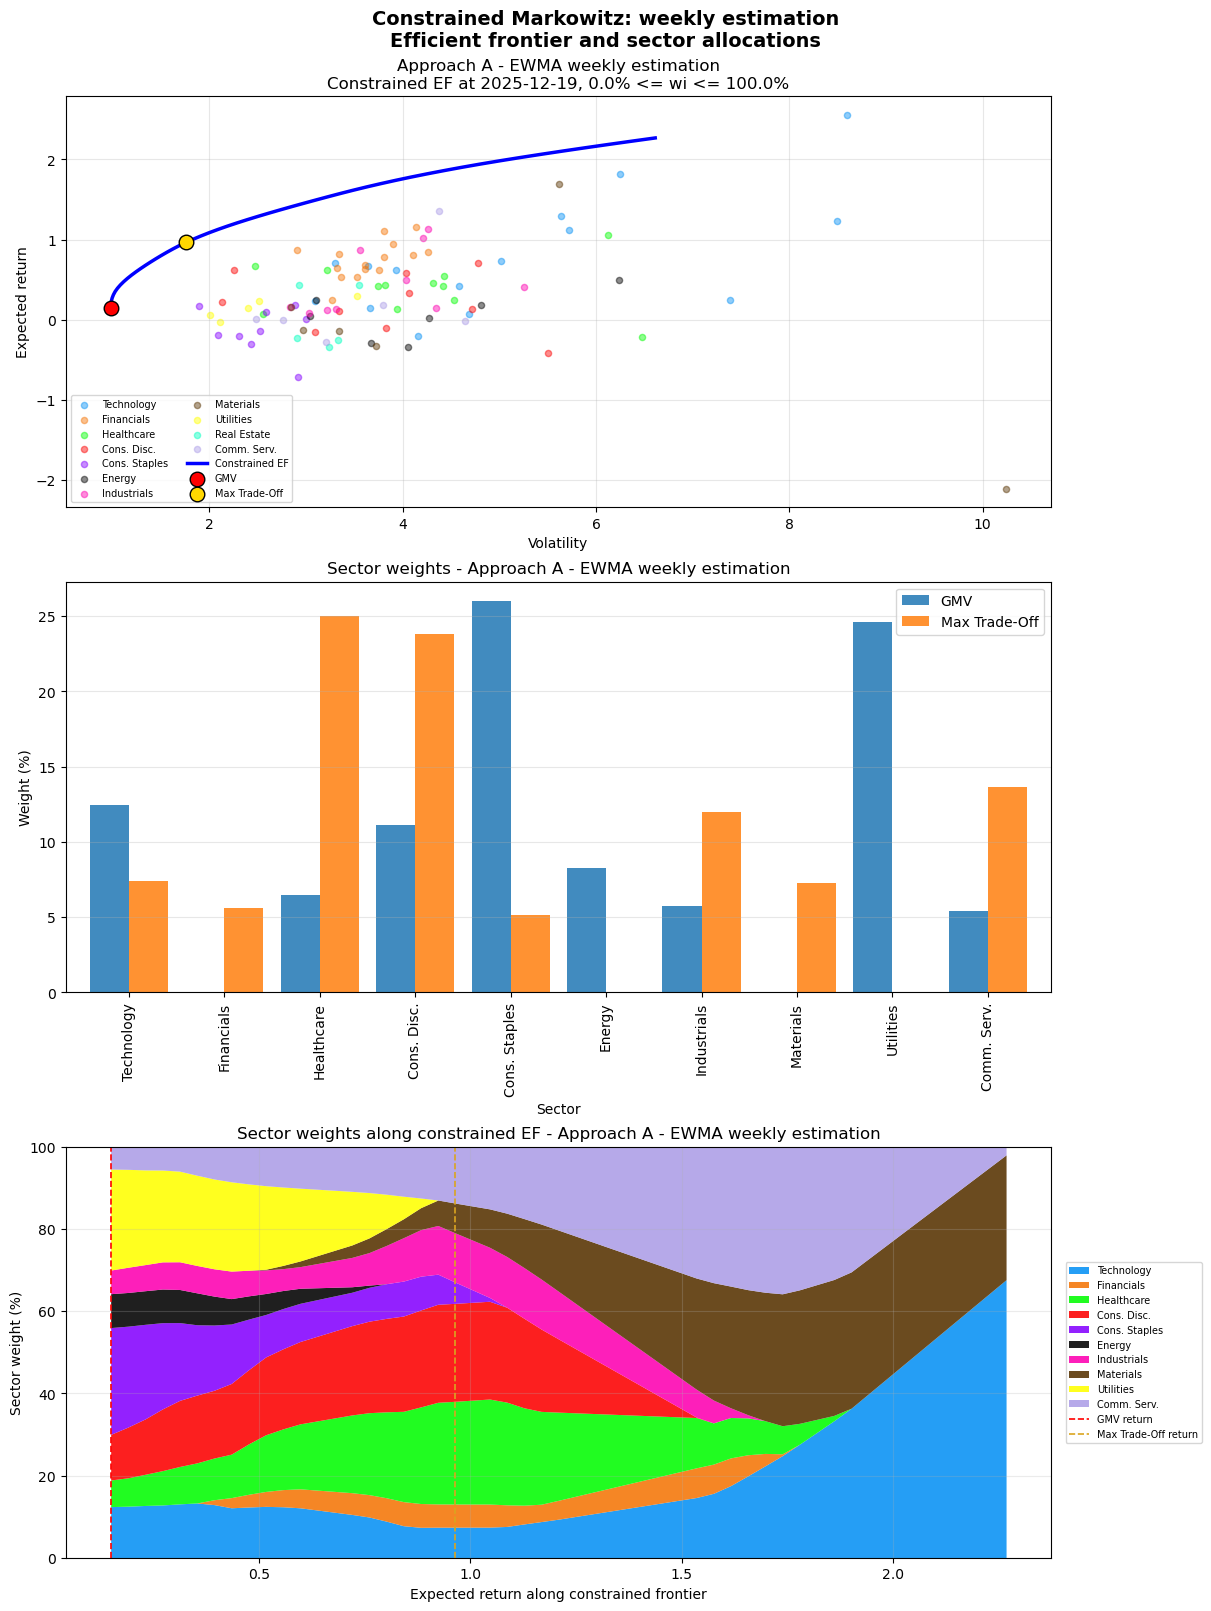

  Bounds : 0.0000 <= wi <= 1.0000
  Minimum assets needed = ceil(1/u) = 1
  Max feasible return : 461.1820%
  Min feasible return : -281.3294%   (diagnostic only)
  GMV return          : 99.0006%
  EF target range     : [99.0006%, 461.1820%]


/var/folders/5c/269t06rj1d14f579s223j9s00000gn/T/ipykernel_2891/3218254371.py:104: UserWarning: Solution may be inaccurate. Try another solver, adjusting the solver settings, or solve with verbose=True for more information.
  problem.solve(


  Skipped 12 infeasible/non-converged EF target(s).


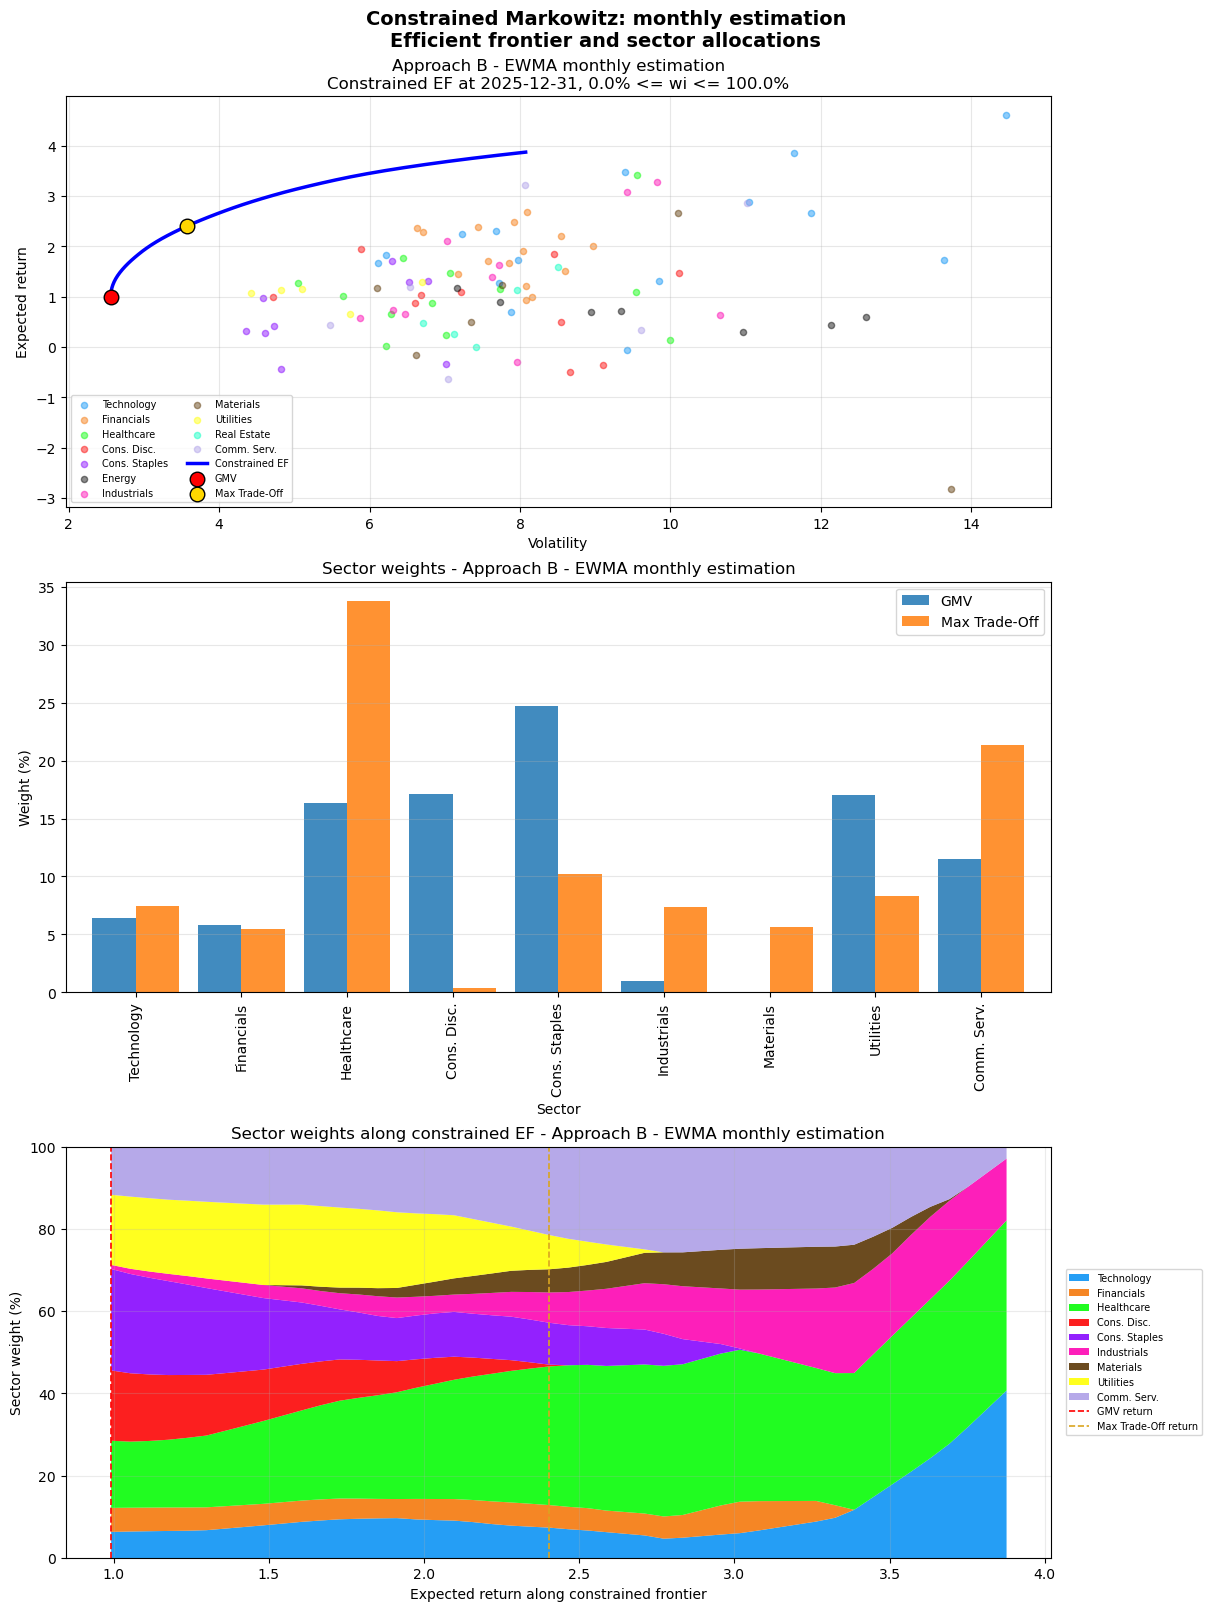


Constrained GMV and Maximum Trade-Off return-risk comparison:


Approach  \
Frequency Portfolio                                                 
Monthly   GMV                Approach B - EWMA monthly estimation   
          Maximum Trade-Off  Approach B - EWMA monthly estimation   
Weekly    GMV                 Approach A - EWMA weekly estimation   
          Maximum Trade-Off   Approach A - EWMA weekly estimation   

                                                 Date  \
Frequency Portfolio                                     
Monthly   GMV               2025-12-31 00:00:00+00:00   
          Maximum Trade-Off 2025-12-31 00:00:00+00:00   
Weekly    GMV               2025-12-19 00:00:00+00:00   
          Maximum Trade-Off 2025-12-19 00:00:00+00:00   

                             Expected Return per Period (%)  \
Frequency Portfolio                                           
Monthly   GMV                                        0.9900   
          Maximum Trade-Off                          2.4019   
Weekly    GMV                                        0.1493   
          Maximum Trade-Off                          0.9640   

                             Volatility per Period (%)  \
Frequency Portfolio                                      
Monthly   GMV                                   2.5592   
          Maximum Trade-Off                     3.5697   
Weekly    GMV                                   0.9782   
          Maximum Trade-Off                     1.7558   

                             Annualized Expected Return (%)  \
Frequency Portfolio                                           
Monthly   GMV                                       11.8801   
          Maximum Trade-Off                         28.8228   
Weekly    GMV                                        7.7641   
          Maximum Trade-Off                         50.1261   

                             Annualized Volatility (%)  Weight Sum  
Frequency Portfolio                                                 
Monthly   GMV                                   8.8654         1.0  
          Maximum Trade-Off                    12.3659         1.0  
Weekly    GMV                                   7.0539         1.0  
          Maximum Trade-Off                    12.6615         1.0

Constrained frontier plotted with bounds: 0.00 <= wi <= 1.00
Cardinality constraint is not used in this plot.


In [25]:
# =============================================================================
# PLOTS - CONSTRAINED EFFICIENT FRONTIER 
# =============================================================================
# This cell uses the constrained frontier already defined above:
# constrained_ef_with_upper(mu, Sigma, u, n_points).
#     sum(w) = 1, 0 <= wi <= u.

# Read the current default upper bound directly from constrained_markowitz.
# At the moment this is u = 1.0, meaning no short sales and no tighter upper bound.
# If later you change the default u in constrained_markowitz, this plos updates automatically.

# A Signature object represents the call signature of a function and its return annotation. For each parameter accepted by the 
# function it stores a Parameter object in its parameters collection.
# An ordered mapping of parameters’ names to the corresponding Parameter objects. Parameters appear in strict definition order, 
# including keyword-only parameters.


# Using python ispect module to read the definition of the function contrained markowut. it reads the default lower bound l from your 
# constraiend_markowitz function necessary for the plot to take the same lower bound and upper bound  as the optimizer. 
signature_constrained_markowitz = inspect.signature(constrained_markowitz)

# it reads the default lower bound l from your constraiend_markowitz function. 
# necessary for the plot to take the same lower bound as the optimizer. 


#This code retrieves the default lower bound l from the definition of constrained_markowitz, checks that it exists, 
# and converts it into a normal numeric value.
l_constrained_plot = signature_constrained_markowitz.parameters["l"].default 
if l_constrained_plot is inspect._empty:
    raise ValueError(' insert the correct lower bound : l ')

#Converts the retrieved value into a floating-point number. It ensures that later numerical operations and plot labels work correctly.
l_constrained_plot = float(l_constrained_plot)

## does the same as the code above. 
u_constrained_plot = signature_constrained_markowitz.parameters["u"].default # 
if u_constrained_plot is inspect._empty:  
    raise ValueError(' insert the correct upper  bound : u ')
    
u_constrained_plot = float(u_constrained_plot)

## this sets the number of points used to trace the efficent frontier. 
#then the code creates 60 target returns between the constrained GMV return and the maximum feasible return, and solves 60 
# constrained Markowitz problems. More points means a smoother efficient frontier plot, but slower computation.
n_constrained_points = 60


## taking the last sorted date for both approach A and B
last_A_constrained_plot = sorted(rolling_mu_A_ewma.keys())[-1]
last_B_constrained_plot = sorted(rolling_mu_B_ewma.keys())[-1]

## creates a list that contains the data needed to produce the constraiend efficent frontier. 
## This provides the input needed for the CVXPY to calculate the weights later. 
## rolling_mu_A_ewma contains the vector of sample expected return along with the vector of sample covariance. 

# short recap : the weight vectors are computed later in the plotting loop, in these two places. First the code calculates the weights of 
# every efficent-frontier point with contrained_ef_with_upper for every target return then CVXPY solves the contrained optimziation a
# return one weight vector w for each point. 

## second, the contrained GMV weights are computed in hte contrained markowitz functions, the variable w_gmv_arr = is the contrained GMW weight vector
constrained_plot_inputs = [
    (
        "Approach A - EWMA weekly estimation",
        rolling_mu_A_ewma[last_A_constrained_plot],
        rolling_cov_A_ewma[last_A_constrained_plot],
        last_A_constrained_plot,
    ),
    (
        "Approach B - EWMA monthly estimation",
        rolling_mu_B_ewma[last_B_constrained_plot],
        rolling_cov_B_ewma[last_B_constrained_plot],
        last_B_constrained_plot,
    ),
]


# Each frequency receives its own figure with three vertically arranged panels.

# contains dictionary to store numerical results used in the plots.
constrained_plot_results = {} 


# raw = 0 for approach a and raw = 1 for approach b. 
for row, (approach_label, mu_s, sigma_df, plot_date) in enumerate(constrained_plot_inputs):
    frequency = "weekly" if row == 0 else "monthly"
    fig, axes = plt.subplots(3, 1, figsize=(12, 16), layout="constrained")
    
    # stores the asset name.
    tickers = mu_s.index  

    # computes the constrained efficent frontier. 
    vols, rets, frontier_weights = constrained_ef_with_upper(
        mu_s.values,
        sigma_df.values,
        u=u_constrained_plot,
        l=l_constrained_plot,
        n_points=n_constrained_points,
    )

    # chekc if the frontier was actually computed. if no valid portfolio was found, the code stops and shows an error. 
    if len(frontier_weights) == 0:
        raise RuntimeError(f"No constrained frontier points computed for {approach_label}.")


    # tranform the frontier weigths into a dataframe. raws are frontier portfolios. columns are asset. index is expected return 
    frontier_weights_df = pd.DataFrame(frontier_weights, columns=tickers, index=rets)
    frontier_weights_df.index.name = "Expected return"


    # computes the constrained global minimum variance portfolios. 
    w_gmv_arr, ret_gmv, var_gmv, vol_gmv, res_gmv = constrained_markowitz(
        mu_s.values,
        sigma_df.values,
        l=l_constrained_plot,
        u=u_constrained_plot,
    )
    if not res_gmv.success:
        raise RuntimeError(f"Constrained GMV failed for {approach_label}: {res_gmv.message}")


    ## converts the GMV weights from a Numpy array into a pandas series. this gives each weight the correct asset ticker. 
    w_gmv = pd.Series(w_gmv_arr, index=tickers, name="Constrained GMV")

    # Constrained Max Trade-Off: point on the constrained frontier with the highest return/risk ratio.

    # compute the return-to-risk ratio for each point on the constraiend frontier. 
    # np.divide = divide arguments element-wise. 
    # computes the return-to-risk ratio for each point on the constraiend frontier. 
    ## it is used to approximate the constrained markowitz. 

    tradeoff_ratio = np.divide(
        rets,
        vols,
        out=np.full_like(rets, np.nan, dtype=float),
        where=vols > 1e-12, # avoids division by zero. 
    )


     #if not np.all(np.isnan(tradeoff_ratio)) # else len(rets) - 1
    idx_tradeoff = int(np.nanargmax(tradeoff_ratio)) 

    # takes the expected return of the maximum trade-off portfolio. 
    ret_T = float(rets[idx_tradeoff]) 

    # takes the volatility of the maximum trade-off portfolio. 
    vol_T = float(vols[idx_tradeoff])

    # takes the weights of the maximum trade-off portfolios. 
    # tunrs the weight vector into a pandas Series with the asset names.
    w_T = pd.Series(frontier_weights[idx_tradeoff], index=tickers, name="Constrained Max Trade-Off")

    # stores the numerical results for the current approach. 
    constrained_plot_results[approach_label] = {
        "vols": vols,
        "rets": rets,
        "weights_frontier": frontier_weights_df,
        "weights_gmv": w_gmv,
        "weights_max_tradeoff": w_T,
        "gmv_expected_return": ret_gmv,
        "gmv_volatility": vol_gmv,
        "max_tradeoff_expected_return": ret_T,
        "max_tradeoff_volatility": vol_T,
        "date": plot_date,
        "l": l_constrained_plot,
        "u": u_constrained_plot,
    }
    # it also stored the upper bound used int he optimization. 


    # -------------------------------------------------------------------------
    # Left plot: constrained efficient frontier.
    # -------------------------------------------------------------------------

    # this block creates two plot for each approach : left plot the efficent frontier. right plot : sector weigths of constrained GMV and constrained maximum trade-off 

    # select the left subplots in the left column 
    ax_frontier = axes[0]

    # computes the volatiltiy of each individual stock. 
    stock_vols = np.sqrt(np.maximum(np.diag(sigma_df.values), 0.0))

    # stores the expeted returns of the individual assets.
    stock_rets = mu_s.values 


    # loops over all sectors. plot stock with differenct colors by sector. 
    for sector in sector_order:

        # finds the ticker that belong to a given sector.
        tickers_in_sector = [ticker for ticker in tickers if sector_map.get(ticker) == sector] 

         # if there are no tickers for that sector, skip it.
        if len(tickers_in_sector) == 0: 
            print("this ticker has no reference for the secotr it belongs. ")



        # fidn the numerical position of those tickers inside the return/covariance arrays.
        idx = [tickers.get_loc(ticker) for ticker in tickers_in_sector]
        ax_frontier.scatter(
            stock_vols[idx], # x-axis stock volatilities 
            stock_rets[idx], # y-axis stock expected return. 
            color=sector_colors.get(sector, "#999999"),
            s=20, # marker size 
            alpha=0.45, # makes dots partially transparent 
            label=sector,
        )


     # plots the contrained efficent frontier. 
     # this line plots the constraiend efficent frontier.
      # each point on the blue line is an optimzied efficent frontier. 
    ax_frontier.plot(vols, rets, color="blue", linewidth=2.5, label="Constrained EF") 
   

    ax_frontier.scatter(vol_gmv, ret_gmv, color="red", s=110, edgecolors="black", zorder=5, label="GMV")## GMV volatiltiy y axis : expected returns 
    ax_frontier.scatter(vol_T, ret_T, color="gold", s=110, edgecolors="black", zorder=5, label="Max Trade-Off")
    ax_frontier.set_title(f"{approach_label}\nConstrained EF at {plot_date.date()}, {l_constrained_plot:.1%} <= wi <= {u_constrained_plot:.1%}")
    ax_frontier.set_xlabel("Volatility")
    ax_frontier.set_ylabel("Expected return")
    ax_frontier.grid(True, alpha=0.3)
    ax_frontier.legend(loc="best", fontsize=7, ncol=2) # ncol decides which is the best position. 

    # -------------------------------------------------------------------------
    # Right plot: sector weights for constrained GMV and constrained Max Trade-Off.
    # -------------------------------------------------------------------------

    # creates an empty dataframe indexed by sector. 
    #rows are secotr. columns will be portfolios. 
    sector_weights = pd.DataFrame(index=sector_order)

    # loop over the the 2 portfolios whose sector weigths we want to compare. 

    for portfolio_name, weights in [("GMV", w_gmv), ("Max Trade-Off", w_T)]:

        
        sector_weights[portfolio_name] = [
            weights.loc[[ticker for ticker in weights.index if sector_map.get(ticker) == sector]].sum()
            for sector in sector_order
        ]

    sector_weights = sector_weights.loc[sector_weights.abs().sum(axis=1) > 1e-8]

    ax_weights = axes[1]
    (sector_weights * 100).plot.bar(ax=ax_weights, width=0.82, alpha=0.85)
    ax_weights.set_title(f"Sector weights - {approach_label}")
    ax_weights.set_ylabel("Weight (%)")
    ax_weights.set_xlabel("Sector")
    ax_weights.grid(True, axis="y", alpha=0.3)
    ax_weights.legend(loc="best")

    # -------------------------------------------------------------------------
    # Third plot: sector weights along the constrained efficient frontier.--> this is the area plots. 
    # -------------------------------------------------------------------------

    # The area plots If I move from the constrained GMV portfolio toward portfolios with higher expected return, how does the allocation to each sector change?

    sector_frontier_weights = pd.DataFrame(index=frontier_weights_df.index)
    for sector in sector_order:
        sector_tickers = [
            ticker for ticker in frontier_weights_df.columns
            if sector_map.get(ticker) == sector
        ]
        if sector_tickers:
            sector_frontier_weights[sector] = frontier_weights_df[sector_tickers].sum(axis=1)

    # Remove sectors that have zero weight at every point of the frontier.
    sector_frontier_weights = sector_frontier_weights.loc[
        :, sector_frontier_weights.abs().sum(axis=0) > 1e-8
    ]
    constrained_plot_results[approach_label]["sector_weights_frontier"] = (
        sector_frontier_weights
    )

    sector_frontier_pct = sector_frontier_weights * 100
    area_colors = [
        sector_colors.get(sector, "#999999")
        for sector in sector_frontier_pct.columns
    ]

    # Stack sectors in the no-short case. If the lower bound is later set
    # below zero, use an unstacked area plot to handle negative sector weights.
    use_stacked_area = bool((sector_frontier_pct >= -1e-8).all().all())
    ax_area = axes[2]
    sector_frontier_pct.plot.area(
        ax=ax_area,
        stacked=use_stacked_area,
        color=area_colors,
        linewidth=0,
        alpha=0.88,
    )
    ax_area.axvline(ret_gmv, color="red", linestyle="--", linewidth=1.2, label="GMV return")
    ax_area.axvline(ret_T, color="goldenrod", linestyle="--", linewidth=1.2, label="Max Trade-Off return")
    ax_area.set_title(f"Sector weights along constrained EF - {approach_label}")
    ax_area.set_xlabel("Expected return along constrained frontier")
    ax_area.set_ylabel("Sector weight (%)")
    if use_stacked_area:
        ax_area.set_ylim(0, 100)
    else:
        ax_area.axhline(0, color="black", linewidth=0.8)
    ax_area.grid(True, alpha=0.25)
    ax_area.legend(loc="center left", bbox_to_anchor=(1.01, 0.5), fontsize=7)

    fig.suptitle(
        f"Constrained Markowitz: {frequency} estimation\nEfficient frontier and sector allocations",
        fontsize=14,
        fontweight="bold",
    )
    fig.savefig(
        f"plot_constrained_markowitz_frontier_sector_weights_{frequency}.png",
        dpi=300,
        bbox_inches="tight",
    )
    plt.show()
    plt.close(fig)

# -------------------------------------------------------------------------
# Numerical comparison of constrained GMV and Maximum Trade-Off portfolios.
# -------------------------------------------------------------------------
# The return inputs are expressed in percentage units. Approach A uses weekly
# estimates and Approach B uses monthly estimates. Arithmetic expected return
# is annualized by multiplying by the number of periods per year, while
# volatility is annualized by multiplying by the square root of that number.


annualization_by_approach = {
    "Approach A - EWMA weekly estimation": 52,
    "Approach B - EWMA monthly estimation": 12,
}
frequency_by_approach = {
    "Approach A - EWMA weekly estimation": "Weekly",
    "Approach B - EWMA monthly estimation": "Monthly",
}

constrained_return_risk_rows = []

for approach_label, results in constrained_plot_results.items():
    periods_per_year = annualization_by_approach[approach_label]

    for portfolio_name, return_key, volatility_key, weight_key in [
        ("GMV", "gmv_expected_return", "gmv_volatility", "weights_gmv"),
        (
            "Maximum Trade-Off",
            "max_tradeoff_expected_return",
            "max_tradeoff_volatility",
            "weights_max_tradeoff",
        ),
    ]:
        expected_return = float(results[return_key])
        volatility = float(results[volatility_key])
        portfolio_weights = results[weight_key]

        constrained_return_risk_rows.append({
            "Approach": approach_label,
            "Frequency": frequency_by_approach[approach_label],
            "Portfolio": portfolio_name,
            "Date": results["date"],
            "Expected Return per Period (%)": expected_return,
            "Volatility per Period (%)": volatility,
            "Annualized Expected Return (%)": expected_return * periods_per_year,
            "Annualized Volatility (%)": volatility * np.sqrt(periods_per_year),
            "Weight Sum": float(portfolio_weights.sum()),
        })

df_constrained_return_risk = (
    pd.DataFrame(constrained_return_risk_rows)
    .set_index(["Frequency", "Portfolio"])
    .sort_index()
)

print("\nConstrained GMV and Maximum Trade-Off return-risk comparison:")
display(df_constrained_return_risk.round(4))

print(f"Constrained frontier plotted with bounds: {l_constrained_plot:.2f} <= wi <= {u_constrained_plot:.2f}")
print("Cardinality constraint is not used in this plot.")


In [26]:
# =============================================================================
# STORE ROLLING CONSTRAINED GMV WEIGHTS - EWMA
# =============================================================================
# These dictionaries are needed by the backtesting procedure.
# Each key is a rebalancing date.
# Each value is a pd.Series of constrained GMV weights indexed by ticker.

weights_A_constrained_gmv_ewma = {}
results_A_constrained_gmv_ewma = {}

for date in sorted(rolling_mu_A_ewma.keys()):
    mu_d = rolling_mu_A_ewma[date]
    Sigma_d = rolling_cov_A_ewma[date]

    # Use the current defaults of constrained_markowitz. If l or u is changed
    # in that function, rerunning this cell rebuilds the corresponding weights.
    w, port_return, port_variance, port_std, result = constrained_markowitz(
        mu_d.values,
        Sigma_d.values,
    )

    if result.success:
        weights_A_constrained_gmv_ewma[date] = pd.Series(
            w,
            index=mu_d.index,
            name=date,
        )

    results_A_constrained_gmv_ewma[date] = {
        "success": result.success,
        "status": result.status,
        "return": port_return,
        "variance": port_variance,
        "std": port_std,
    }


weights_B_constrained_gmv_ewma = {}
results_B_constrained_gmv_ewma = {}

for date in sorted(rolling_mu_B_ewma.keys()):
    mu_d = rolling_mu_B_ewma[date]
    Sigma_d = rolling_cov_B_ewma[date]

    w, port_return, port_variance, port_std, result = constrained_markowitz(
        mu_d.values,
        Sigma_d.values,
    )

    if result.success:
        weights_B_constrained_gmv_ewma[date] = pd.Series(
            w,
            index=mu_d.index,
            name=date,
        )

    results_B_constrained_gmv_ewma[date] = {
        "success": result.success,
        "status": result.status,
        "return": port_return,
        "variance": port_variance,
        "std": port_std,
    }


df_weights_A_constrained_gmv_ewma = pd.DataFrame(weights_A_constrained_gmv_ewma).T
df_weights_B_constrained_gmv_ewma = pd.DataFrame(weights_B_constrained_gmv_ewma).T

df_results_A_constrained_gmv_ewma = pd.DataFrame(results_A_constrained_gmv_ewma).T
df_results_B_constrained_gmv_ewma = pd.DataFrame(results_B_constrained_gmv_ewma).T

print("Constrained EWMA GMV weights stored")
print(f"Approach A constrained EWMA GMV portfolios: {len(weights_A_constrained_gmv_ewma)}")
print(f"Approach B constrained EWMA GMV portfolios: {len(weights_B_constrained_gmv_ewma)}")

print("\nApproach A constrained optimization status:")
print(df_results_A_constrained_gmv_ewma["status"].value_counts())

print("\nApproach B constrained optimization status:")
print(df_results_B_constrained_gmv_ewma["status"].value_counts())

Constrained EWMA GMV weights stored
Approach A constrained EWMA GMV portfolios: 162
Approach B constrained EWMA GMV portfolios: 148

Approach A constrained optimization status:
status
optimal    162
Name: count, dtype: int64

Approach B constrained optimization status:
status
optimal    148
Name: count, dtype: int64


In [27]:
# =============================================================================
# SECTOR ALLOCATION OF THE LATEST CONSTRAINED MARKOWITZ PORTFOLIOS
# =============================================================================
# Reuse the constrained GMV and Maximum Trade-Off weights already stored in
# constrained_plot_results. This cell does not rerun any optimization.

constrained_latest_portfolio_weights = {
    "Approach A - Constrained GMV": constrained_plot_results[
        "Approach A - EWMA weekly estimation"
    ]["weights_gmv"],
    "Approach A - Constrained Maximum Trade-Off": constrained_plot_results[
        "Approach A - EWMA weekly estimation"
    ]["weights_max_tradeoff"],
    "Approach B - Constrained GMV": constrained_plot_results[
        "Approach B - EWMA monthly estimation"
    ]["weights_gmv"],
    "Approach B - Constrained Maximum Trade-Off": constrained_plot_results[
        "Approach B - EWMA monthly estimation"
    ]["weights_max_tradeoff"],
}

# Sum the existing asset weights within each sector and express the result
# as a percentage of portfolio net value.
constrained_sector_allocation_percent = pd.DataFrame(index=sector_order)

for portfolio_name, portfolio_weights in constrained_latest_portfolio_weights.items():
    constrained_sector_allocation_percent[portfolio_name] = [
        portfolio_weights.loc[
            [
                ticker
                for ticker in portfolio_weights.index
                if sector_map.get(ticker) == sector
            ]
        ].sum() * 100
        for sector in sector_order
    ]

constrained_sector_allocation_percent.index.name = "Sector"

print(f"Approach A constrained portfolio date: {last_A_constrained_plot.date()}")
print(f"Approach B constrained portfolio date: {last_B_constrained_plot.date()}")
print("\nConstrained sector allocation as a percentage of portfolio net value:")
display(constrained_sector_allocation_percent.round(2))

# Every column should sum to 100%. If the lower weight bound is negative,
# individual sectors may have negative allocations because short sales are allowed.
print("\nConstrained sector-allocation totals (%):")
display(
    constrained_sector_allocation_percent.sum()
    .round(6)
    .to_frame("Total (%)")
)


Approach A constrained portfolio date: 2025-12-19
Approach B constrained portfolio date: 2025-12-31

Constrained sector allocation as a percentage of portfolio net value:


,Approach A - Constrained GMV,Approach A - Constrained Maximum Trade-Off,Approach B - Constrained GMV,Approach B - Constrained Maximum Trade-Off
Sector,,,,
Technology,12.44,7.44,6.41,7.44
Financials,0.00,5.64,5.85,5.49
Healthcare,6.47,25.00,16.34,33.75
Cons. Disc.,11.11,23.84,17.11,0.42
Cons. Staples,25.99,5.17,24.70,10.19
Energy,8.25,0.00,0.00,0.00
Industrials,5.75,11.99,0.99,7.38
Materials,0.00,7.25,0.00,5.64
Utilities,24.59,0.00,17.07,8.33



Constrained sector-allocation totals (%):


,Total (%)
Approach A - Constrained GMV,100.0
Approach A - Constrained Maximum Trade-Off,100.0
Approach B - Constrained GMV,100.0
Approach B - Constrained Maximum Trade-Off,100.0


### IMPLEMENTING THE LASSO REGRESSION 

The main objective of this master thesis is the implementation of the alsso regression with a gross exposures constrained, as proposed by Fan et all 2012. 
The idea is that we approach the utility optimization problem by introducing a gross-exposure constraint on the allocation vector. As the gross exposure parameter increases from 1 to infinity, our utility optimization progressively ranges from no-short-sale constraint to no constraint on short sales. The oracle and empirical optimal portfolios, based, respectively,
on the true and estimated parameters, have approximately the same utility.Ideally, we would like to constructa robust portfolio of a reasonably small size to reduce trading,rebalancing, monitoring, and research costs. We start by defining : 

for allocation with portfolio **w** the total $w^+ = \frac{\||w\||_1 + 1}{2}$ and $w^- = \frac{\||w\||_1 - 1}{2}$.  
The constrained $ ||w_1|| ≤ c$ prevents extreme positions in the portfolio. if c= 1 --> no short sales are allowed. if c = $ \infty$ --> there is no constrained on short sales. Our optimization process becomes : 
$$
\begin{aligned}
\max_{w} \quad & \mathbb{E} [U(w^T R)] \\
\text{s.t.} \quad & w^T \mathbf{1} = 1, \quad \|w\|_1 \le c, \quad Aw = a
\end{aligned}
$$ 

The extra constrained $Aw = a$ are related to the constraints on the  percentage of allocations on each sector or industry and it must be considered as an extra constraint.  
The utility optimization is equivalent to maximizing the Markowitz mean-variance function : 
$$
\begin{aligned}
\mathbb{U}(\mu, \Sigma ) = w^T \mu - \lambda w^T \Sigma 
\end{aligned}
$$
where $\lambda = B/2$ with B being the absolute risk aversion parameter. 
The solution of the following problem is given by : 
$$ 
\begin{aligned}
w_{opt} = c_{1} \Sigma^{-1} \mu + c_{2} \Sigma^{-1} \mathbf{1} \quad  \text{with} c_{1} \quad  \text{and} \quad  c_{2} \quad  \text{depending on} \mu \quad  \text{and} \quad \sigma \quad \text{as well}
\end{aligned}
$$
Clearly the solutions depends sensitively on the two input vectors and on their accumulated errors. if we impose the sensitivity constrained : $ |w|_{1} \le c $ the sensitivity of the utility function to the estimation errors can be easily bounded as : 
$$
\left| M(\hat{\mu}, \hat{\Sigma}) - M(\mu, \Sigma) \right| \leq \|\hat{\mu} - \mu\|_\infty \|w\|_1 + \lambda \|\hat{\Sigma} - \Sigma\|_\infty \|w\|_1^2
$$ 
where $\|\hat{\mu} - \mu\|_\infty \quad \text{and } \quad \|\hat{\Sigma} - \Sigma\|_\infty$ are the maximum componentwise estimation errors. The story is very different if $ c = \infty$ because the estimation error does accumulate (neglegible only for portfolio with a moderate size)


### OPTIMIZATION PART. 

From now on we consider the following risk minimization 
$$
\begin{aligned}
\min w^{T} \Sigma w \quad
\text{s.t.} \quad w^{T} 1 = 1, |w|_{1} \le c 
\end{aligned}
$$

letting $R(W) = w^{T} \Sigma w, \quad R_{n}(w) = W^{T} \hat{\Sigma}w$ be, respectively, the theoretical and empirical portfolio risks with allocation w, where $\hat{\Sigma}$ is an estimated covariance matrix based on the data with sample size *n*. Let : 
$$
w_{opt} = \argmin_{w^T \mathbf{1} = 1, \; \|w\|_1 \leq c} \; R(w)
$$
and 
$$
\hat{w_{opt}} = \argmin_{w^T \mathbf{1} = 1, \; \|w\|_1 \leq c} \; R_{n}(w)
$$
be respectively the theoretical optimal allocation vector we want and the empirical allocation vector vector we get. 

Let $ a_{n} =  \|\hat{\Sigma} - \Sigma\|_\infty $. Then we have : 
$$
\left |\mathcal{R}(w_{opt}) - \mathcal{R}_n(\hat{w}_{opt}) \right| \leq a_{n} c^2
$$
and 
$$
\left |\mathcal{R}(\hat{w}_{opt}) - \mathcal{R}({w}_{opt}) \right| \leq 2a_{n} c^2
$$
and 
$$
\mathbb{E}\left[ \mathcal{R}_n(\hat{w}_{opt}) \right] \leq \mathcal{R}(w_{opt}) \leq \mathcal{R}(\hat{w}_{opt})
$$
The theoretical minimum risk $\mathcal{R}(w_{opt})$ --> oracle risk and $\mathcal{R}(\hat{w}_{opt})$ --> actual risk ARE aproximately the same as long as the *c* is not too large and the accuracy of the estimated covariance matrix is not too poor. --> both are unknown. 
The empirical minimum risk is known $\mathcal{R}_{n}(\hat{w}_{opt})$ is known and veen since can be too small it is to close to both theoretical risk and actuarial risk. Result hold without any conditions on $\hat{\Sigma}$.   $a_{n}$ depends on the model assumption and method of estimation. 
To understand the impact of the portfolio size *p* on the accuracy $a_{n}$, let us consider the sample covariance matrix $S_{n}$ based on the sample $\{R_t\}_{t=1}^{n}$. When *p* is fixed we have : 
$\|\hat{S}_n - \Sigma\|_\infty = O_p\!\left(\sqrt{\frac{\log p}{n}}\right)$ --> the portfolio size enters into the maximum estimation error only at a logarithmic scale. Hence, the portfolio size does not play a signiﬁcant role in risk minimization as long as the constraint on gross exposure is in place.  

Theorem 3 : Let $\sigma_{ij}$ and $\hat{\sigma_{ij}}$ be the (i,j)th element of the matrices $\Sigma$ and $\hat{\Sigma}$, respectively. then we have : 
$$
\max_{i,j} \; \mathbb{P}\left\{ \sqrt{n} \, |\sigma_{ij} - \hat{\sigma}_{ij}| > x \right\} < \exp\!\left(-C x^{1/a}\right)
$$
for two positive contant a and C, then we have : 
$$\|{\Sigma} - \hat{\Sigma}\|_\infty =O_p\!\left(\frac{(\log p)^a}{\sqrt{n}}\right)$$

ADD SOME CONSTANT FOR THIS 3 THEOREM 




### RELATION WITH COVARIANCE REGULARIZATION 

by the langrangian multiplier method the minimum problems become 
$$w^T \hat{\Sigma} w / 2 + \lambda_1 \left(\|w\|_1 - c\right) + \lambda_2 \left(1 - w^T \mathbf{1}\right)
$$
Letting **g** be the subgradient vector of the function $w_1$, whose  *i*th element being −1, 1, or any values in [−1, 1] depending on whether $w_{i}$ is positive, negative, or zero.
Then, the Karush–Kuhn–Tucker conditions for the constrained optimization are : 
$$
\hat{\Sigma} w + \lambda_1 g - \lambda_2 \mathbf{1} = 0, \qquad
\lambda_1 (c - \|w\|_1) = 0, \qquad
\lambda_1 \geq 0
$$
in addition to the constraints $w_{T} = 1 $ and $\|w \| =1 \le c$.  
Let $\tilde{w}$ the solution of the previous 2 equations.   
The constraiend portfolio optimization is equivalent to the mean-variance problem : 
$$
\min_{w^T \mathbf{1} = 1} \; w^T \tilde{\Sigma} w
$$
with the regularazed covariance matrix : 
$$
\tilde{\Sigma}_{c} = \hat{\Sigma} + \lambda_{1}(\tilde{g}_{1}^{T} + \mathbf{1}\tilde{g}^{T})
$$
where  $\tilde{g}$ is the subgradient evaluated at $\tilde{w}$ and $\lambda_{1}$ is the langrangin multiplier define as above. 

### CHOICE OF GROSS-EXPOSURES PARAMETER 

The gross-exposure parameter *c* is given by invvestor. Let m be the number of data used in the
testing period. A natural estimate of the risk profile with gross exposure c is to use the first n-m data points to get a sample covariance matrix and hence the allocation vectors $\hat{w}_{c}$. Then compute the risk profile :  
$$
\begin{aligned} 
R(c;\, n-m,\, m) = m^{-1} \sum_{t=n-m+1}^{n} \hat{w}_{c}^{T} R_{t}^{2} 
\end{aligned}
$$
in which the learning period up to time **n-m** and the testing period of lenght **m** are stressed. The optimal data-driven choiche is the one that minimize the function. In practise, one is not willing to use a large *m*. This leaves the formula above unstable. To increase the reliability of the risk evaluation, we can use : 
$$
R(c) = K^{-1} \sum_{j=1}^{K} R(c;n-jm,m)
$$
Increases the testing period by a factor of K times. 

### PORTFOLIO TRACKING AND ASSET ALLOCATION
CONNECTION WITH REGRESSION PROBLEM.
Markowitz’s risk minimization problem can be recast as a regression problem. By using the fact that the sum of total weights is one, we have : 
$$
\text{var}(w^{T} R) = \min_{b}\, \mathbb{E}(w^{T} R - b)^{2} = \min_{b}\, \mathbb{E}(Y - w_{1}X_{1} - \cdots - w_{p-1}X_{p-1} - b)^{2}
$$

where $Y = R_p$ and $X_j = R_p - R_j (j = 1,...., p-1)$. Finding the optimal weight **w** is the same as finding the regression coefficent $\mathbf{w^*} = (w_1,...,w_{p-1})^T$
The gross-exposures contraint $\|w_{1}\| \le c$ can now be expressed as $\|w_{1}\| \le c- | 1-1^T w^*|$. Thus our minimization problem :
$$
\begin{aligned}
\min w^{T} \Sigma w \quad
\text{s.t.} \quad w^{T} 1 = 1, |w|_{1} \le c 
\end{aligned}
$$

can be expressed as : 
$$
\min_{b,\, \|w^*\|_{1} \leq d}\, \mathbb{E}(Y - w^{*T} X - b)^{2}
$$
where $ X = (X_1,...., X_{p-1})^T$. But they are not equivalent. The latter depends ont he choiche of asset **Y**, while the former does not. Efron et al. (2004) developed an efficient algorithm by using
the least-angle regression (LARS), called the LARS-LASSO algorithm,to efficiently find the whole solution path $w^{*}_{opt}(d)$ for all $ \ge d$.  
If the variable Y is the portfolio to be tracked the previous minimization problem can be can be interpreted as finding a limited number of stocks with a gross-exposures constraint to minimize the expected tracking error. 
AN ABSOLUTE PATH TO RISK MINIMIZATION: 
If we impose the allocation with $-w^{*}_{opt}(d)$ on the first p-1 stock and the rest of the last stock is a feasible allocation vector to our original minimization problem with $ c = d + | 1 - w^{*}_{opt}(d)|$. This will not be the optimal solution to the problem  as
it depends on the choice of Y.This will not be the optimal solution to the problem  as it depends on the choice of Y. However, when Y is properly chosen, the solution is nearly optimal, as to be demonstrated.
For example, by taking Y to be the no-short-sale portfolio, then
problem  with d= 0 is the same as the solution to problem  with c = 1. We can then use to provide a nearly optimal solution.

#### SUMMARY 
In summary, to compute 
$$
\begin{aligned}
\min w^{T} \Sigma w \quad
\text{s.t.} \quad w^{T} 1 = 1, |w|_{1} \le c 
\end{aligned}
$$
for all c, we first find the solution with c = 1 using a quadratic programming. This yields the optimal no-short-sale portfolio. We then take this problem as Y in 
$$
\min_{b,\, \|w^*\|_{1} \leq d}\, \mathbb{E}(Y - w^{*T} X - b)^{2}
$$
and apply the LARS-LASSO algorithm to compute the solution path $- w^{*}_{opt}(d)$. Finally, compute the gross exposures of the portfolio with $w^{*}_{opt}(d)$ ont he first p-1 stocks and the rest on the optimal no-short-sales portfolio, called it c, namely regard the aforementioned portfolio as an approximate solution to the original minimzation problem 



In [28]:
# =============================================================================
# STANDARDIZED 9-YEAR ROLLING RETURN WINDOWS
# =============================================================================
# Use fixed observation counts and separate decision calendars:
# A advances by four weekly observations; B retains its monthly calendar.
#     Approach A: 468 weekly observations (52 * 9 years)
#     Approach B: 108 monthly observations (12 * 9 years)
# A includes the weekly decision-close observation; the next week is OOS.
# B retains its original strict-before-monthly-date convention.
##  the returns are standardized before implementing the lasso regression. 


# =============================================================================
# APPROACH A: WEEKLY RETURNS, 9-YEAR WINDOW, REBALANCING EVERY FOUR WEEKS
# =============================================================================
rolling_return_A_standardized = {}
rolling_mu_A_standardized = {}
rolling_cov_A_standardized = {}
rolling_scaler_A = {}

for date in rebalancing_dates_A:
    # Use the 468 observations ending at the weekly decision close.
    weekly_history = weekly_estimation_windows[date]

    # Retain exactly the most recent 468 weekly observations.
    weekly_window = weekly_history.iloc[-WEEKLY_WINDOW_OBS:]

    if len(weekly_window) != WEEKLY_WINDOW_OBS:
        raise ValueError(
            f"Approach A: {date.date()} has {len(weekly_window)} observations; "
            f"{WEEKLY_WINDOW_OBS} are required."
        )

    # Fit the scaler only on the current historical window. Each asset column
    # is transformed to have sample location approximately zero and unit scale.
    scaler_A = StandardScaler()
    weekly_window_standardized = pd.DataFrame(
        scaler_A.fit_transform(weekly_window),
        index=weekly_window.index,
        columns=weekly_window.columns,
    )

    rolling_return_A_standardized[date] = weekly_window_standardized
    rolling_mu_A_standardized[date] = weekly_window_standardized.mean()
    rolling_cov_A_standardized[date] = weekly_window_standardized.cov()
    rolling_scaler_A[date] = scaler_A


# =============================================================================
# APPROACH B: MONTHLY RETURNS, 9-YEAR WINDOW, MONTHLY REBALANCING
# =============================================================================
rolling_return_B_standardized = {}
rolling_mu_B_standardized = {}
rolling_cov_B_standardized = {}
rolling_scaler_B = {}

for date in rebalancing_dates:
    # Select all complete monthly observations available before the rebalance.
    monthly_history = monthly_return.loc[
        monthly_return.index < date
    ].dropna(axis=0, how="any")

    # Retain exactly the most recent 108 monthly observations.
    monthly_window = monthly_history.iloc[-MONTHLY_WINDOW_OBS:]

    if len(monthly_window) != MONTHLY_WINDOW_OBS:
        raise ValueError(
            f"Approach B: {date.date()} has {len(monthly_window)} observations; "
            f"{MONTHLY_WINDOW_OBS} are required."
        )

    # Fit a new scaler on each monthly estimation window. This prevents future
    # observations from influencing the transformation used at the current date.
    scaler_B = StandardScaler()
    monthly_window_standardized = pd.DataFrame(
        scaler_B.fit_transform(monthly_window),
        index=monthly_window.index,
        columns=monthly_window.columns,
    )

    rolling_return_B_standardized[date] = monthly_window_standardized
    rolling_mu_B_standardized[date] = monthly_window_standardized.mean()
    rolling_cov_B_standardized[date] = monthly_window_standardized.cov()
    rolling_scaler_B[date] = scaler_B


# Convert the rolling standardized means into DataFrames for inspection.
df_rolling_mu_A_standardized = pd.DataFrame(rolling_mu_A_standardized).T
df_rolling_mu_B_standardized = pd.DataFrame(rolling_mu_B_standardized).T

print(f"Approach A standardized windows: {len(rolling_return_A_standardized)}")
print(f"Approach B standardized windows: {len(rolling_return_B_standardized)}")
print(f"Weekly observations per window: {WEEKLY_WINDOW_OBS}")
print(f"Monthly observations per window: {MONTHLY_WINDOW_OBS}")

first_A_std = min(rolling_return_A_standardized)
first_B_std = min(rolling_return_B_standardized)

print(f"\nFirst standardized Approach A date: {first_A_std.date()}")
print("Mean of first five standardized weekly assets:")
print(rolling_mu_A_standardized[first_A_std].head().round(6))

print(f"\nFirst standardized Approach B date: {first_B_std.date()}")
print("Mean of first five standardized monthly assets:")
print(rolling_mu_B_standardized[first_B_std].head().round(6))

# Safety checks confirm that every stored window uses the intended fixed length.
if not all(
    len(window) == WEEKLY_WINDOW_OBS
    for window in rolling_return_A_standardized.values()
):
    raise RuntimeError("At least one standardized weekly window has the wrong length.")

if not all(
    len(window) == MONTHLY_WINDOW_OBS
    for window in rolling_return_B_standardized.values()
):
    raise RuntimeError("At least one standardized monthly window has the wrong length.")


Approach A standardized windows: 162
Approach B standardized windows: 148
Weekly observations per window: 468
Monthly observations per window: 108

First standardized Approach A date: 2013-08-16
Mean of first five standardized weekly assets:
AAPL.O    0.0
MSFT.O   -0.0
IBM.N     0.0
ORCL.N    0.0
CSCO.O    0.0
dtype: float64

First standardized Approach B date: 2013-09-30
Mean of first five standardized monthly assets:
AAPL.O   -0.0
MSFT.O   -0.0
IBM.N     0.0
ORCL.N   -0.0
CSCO.O   -0.0
dtype: float64


REFERENCE-ASSET LARS-LASSO COMPLETE
Monthly rebalancing calendar: 2013-09-30 to 2025-12-31 (148 dates)

Approach A - latest selected portfolios:


,Approach,Selected gross exposure,Alpha,Beta L1,Sample variance,Sample volatility,Active positions,Short positions,Weight sum,Reference asset
Target c,,,,,,,,,,
1.00,Approach A - weekly standardized returns,1.000000,0.053328,0.948929,0.222589,0.471794,28,0,1.0,T.N
1.25,Approach A - weekly standardized returns,1.214218,0.035038,1.193337,0.201051,0.448387,32,2,1.0,T.N
1.50,Approach A - weekly standardized returns,1.467967,0.022409,1.463693,0.185964,0.431236,39,7,1.0,T.N
2.00,Approach A - weekly standardized returns,1.984070,0.012455,1.982265,0.168593,0.410601,54,16,1.0,T.N
2.50,Approach A - weekly standardized returns,2.488972,0.007910,2.484316,0.158609,0.398257,68,23,1.0,T.N



Approach B - latest selected portfolios:


,Approach,Selected gross exposure,Alpha,Beta L1,Sample variance,Sample volatility,Active positions,Short positions,Weight sum,Reference asset
Target c,,,,,,,,,,
1.00,Approach B - monthly standardized returns,1.000000,0.063229,0.908644,0.191252,0.437324,24,0,1.0,T.N
1.25,Approach B - monthly standardized returns,1.235547,0.044611,1.176289,0.162408,0.402999,26,1,1.0,T.N
1.50,Approach B - monthly standardized returns,1.462370,0.036641,1.407460,0.143765,0.379164,31,6,1.0,T.N
2.00,Approach B - monthly standardized returns,1.948648,0.024167,1.903538,0.114041,0.337699,41,12,1.0,T.N
2.50,Approach B - monthly standardized returns,2.462280,0.016515,2.419719,0.093417,0.305642,47,16,1.0,T.N


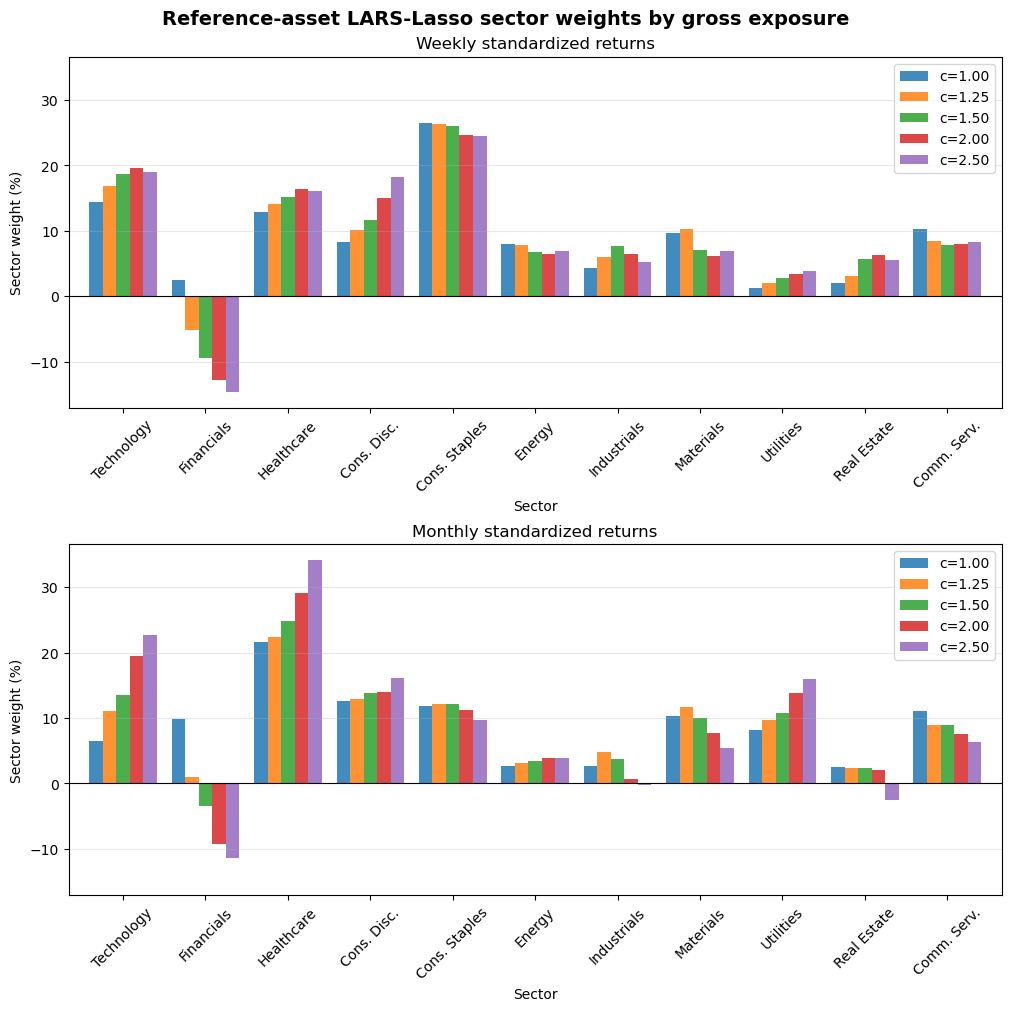


Latest gross-exposure diagnostics - Approach A:


,Gross exposure,Weight sum,Active positions,Short positions
c=1.00,1.000000,1.0,28,0
c=1.25,1.214218,1.0,32,2
c=1.50,1.467967,1.0,39,7
c=2.00,1.984070,1.0,54,16
c=2.50,2.488972,1.0,68,23



Latest gross-exposure diagnostics - Approach B:


,Gross exposure,Weight sum,Active positions,Short positions
c=1.00,1.000000,1.0,24,0
c=1.25,1.235547,1.0,26,1
c=1.50,1.462370,1.0,31,6
c=2.00,1.948648,1.0,41,12
c=2.50,2.462280,1.0,47,16


Weekly LARS decisions: 162, every four observations


In [29]:
## Implementation of the lasso regression. 

gross_exposure_grid = [1.0, 1.25, 1.50, 2.00,2.50]

## handling errors. This determines whether a portfolio weight is considered different from zero.
LASSO_POSITION_TOLERANCE = 1e-6 

## this controls a tiny numerical margin when checking the gross-exposures contraint. 
LASSO_EXPOSURE_TOLERANCE = 1e-10


# Each frequency has its own estimation/decision calendar.
weekly_lasso_rebalancing_dates = pd.DatetimeIndex(sorted(rolling_return_A_standardized))
canonical_lasso_rebalancing_dates = pd.DatetimeIndex(sorted(rolling_return_B_standardized))
if weekly_lasso_rebalancing_dates.empty or canonical_lasso_rebalancing_dates.empty:
    raise ValueError("Both estimation calendars must contain observations.")

# this function prepares the input data X and Y required by the lasso regression for one standardized nine-year
# rolling window 
def build_reference_asset_lasso_data(standardized_returns):
    """Construct Y and X from one standardized rolling return window."""

    ## 
    returns_window = standardized_returns.dropna(axis=0, how="any").astype(float)
    tickers = pd.Index(returns_window.columns)

    # sanity check. the regression required one reference asset and one predictior
    if len(tickers) < 2:
        raise ValueError("The Lasso regression requires at least two assets.")
    if len(returns_window) < 2:
        raise ValueError("The Lasso regression requires at least two observations.")

    # The final asset is used only as a reference for imposing the budget.
    # this is the reference asset Y
    reference_asset = tickers[-1]

    # this takes all other asset X_j
    other_assets = tickers[:-1]

    # The preceding cell has already standardized every asset return series.
    # setting Y as the reference asset. The response variable is the standardize return Y_t = R_N,t
    Y = returns_window[reference_asset].to_numpy(dtype=float)

    ## this as are the vector of the indipendent variables
    # X_i,t = Y_t - R_i,t
    # reshape converts Y from a onel-dimensional vector into a column vector
    X = (
        Y.reshape(-1, 1)
        - returns_window.loc[:, other_assets].to_numpy(dtype=float)
    )

    # safety check  to prevents the regression from running X and Y contains NaN, positive infinty and negative infinity. 
    if not np.isfinite(Y).all() or not np.isfinite(X).all():
        raise ValueError("The Lasso regression data contain non-finite values.")

    return X, Y, tickers, other_assets, reference_asset

## this function reconstructs the weights
## beta = is thre N-1 coefficent estimated by LARS-LASSO 
def reconstruct_reference_asset_weights(beta, tickers, other_assets, reference_asset):
    """Convert the N-1 Lasso coefficients into N portfolio weights."""

    # vector of portfolio weigths, initialized as zero with asset tickers as labels. 
    weights = pd.Series(0.0, index=tickers, dtype=float)

    # The regression coefficients are the weights of the non-reference assets.
    # assing every lasso coefficents to it's corresponding non-reference asset. w_i = \beta_i
    weights.loc[other_assets] = np.asarray(beta, dtype=float)

    # The remaining weight is assigned to the reference asset, so sum(w) = 1.
    # respecting the budget constraint. 
    weights.loc[reference_asset] = 1.0 - weights.loc[other_assets].sum()
    weights.name = "Reference-asset LARS-Lasso"

    if not np.isclose(weights.sum(), 1.0, atol=1e-6):
        raise ValueError("The reconstructed Lasso weights do not sum to one.")


    ## return the complete portfolio vector w, including the reference asset. ||w|| = \sum_i=1^N |w_i|
    return weights



def reference_asset_lasso_path(standardized_returns):
    """Compute all reference-asset portfolios along one LARS-Lasso path."""
    X, Y, tickers, other_assets, reference_asset = (
        build_reference_asset_lasso_data(standardized_returns)
    )

    # The inputs are already standardized, and their means are approximately zero.
    # lars_path therefore estimates the no-intercept Lasso solution path directly.
    # alphas are the maximum of covariance in abs values
    # Indices of active variables at the end of the path.
    # coefficents = Coefficients along the path.
    alphas, active, coefficients = lars_path(
        X,# set of indipendent variables 
        Y,# target assets 
        method="lasso",
        max_iter=10000,
        verbose=False,# if you want to print all the info about the optimziation procedure 
    )


    ## storing the result for every point along the LARS-LASSO solution path. 
    # this list contains the weights
    path_weights = []

    # this list contains the diagnostic of the portfolio constructed with the data. necessary for 
    # comparing different strategies. 
    path_rows = []

    # this loops considers one Lasso solution at a time along the full-lars lasso path. 
    # coefficnets is a matri returned by lars_path where N_1 is the number of regression coefficents,
    # one for each non-negative asset. K is the number of points on the LARS-LAsso path. 
    # coefficents shape [1] is the number of candidate lasso portfolios produced by the algorithm. 
    for path_index in range(coefficients.shape[1]):

        # \beta is the vector lasso regression coefficents and determines the portfolio coefficents
        # \beta>0 = long positions, \beta<0 = short positions. 
        beta = coefficients[:, path_index]
        weights = reconstruct_reference_asset_weights(
            beta,
            tickers,
            other_assets,
            reference_asset,
        )

        # This residual is exactly the standardized return of the reconstructed
        # portfolio under the reference-asset regression identity.
        # computes the regression residual at the current LAso-path point 
        # X\bet = \sum_i=1^N-1 \beta_i @x_i
        # this computes the residual Y_t - \sum_{i=1}^{N-1} \beta_i X_{i,t}
        residual = Y - X @ beta

        # because the returns are standardize beforehand and have approximately zero mean within each rolling 
        # rolling window
        sample_variance = float(np.mean(residual ** 2))

        # list of all the possible path_weigths
        path_weights.append(weights)

        # storing the diagnostic. 
        path_rows.append({
            "Path index": path_index,# store the position k of the candidate along the LArs path
            "Alpha": float(alphas[path_index]),# \lambda parameter associated with this path point. 
            # a higher \alpha parameter set more coefficent to zero

            # computes the L_1 norm of the N-1 regression coefficents |\beta|_1 = \sum_{i=1}^{N-1} |\beta_i|
            "Beta L1": float(np.abs(beta).sum()),

            # gross exposures contraint. 
            "Gross exposure": float(weights.abs().sum()),

            "Sample variance": sample_variance,

            "Sample volatility": float(np.sqrt(max(sample_variance, 0.0))),

            # long positions 
            "Active positions": int(
                (weights.abs() > LASSO_POSITION_TOLERANCE).sum()
            ),

            # short positions 
            "Short positions": int(
                (weights < -LASSO_POSITION_TOLERANCE).sum()
            ),
            "Weight sum": float(weights.sum()),
            "Reference asset": reference_asset,
        })

    path_info = pd.DataFrame(path_rows).set_index("Path index")
    return path_weights, path_info



## chooses one portfolio from the candidate portfolios produced by the Lars-path. 
## among all LARS portfolios with |w|<c select the one with lowest variance
def select_lasso_weight_by_gross_exposure(path_weights, path_info, c_target):
    """Select the minimum-variance path portfolio satisfying ||w||_1 <= c."""
    eligible = path_info["Gross exposure"] <= (
        float(c_target) + LASSO_EXPOSURE_TOLERANCE
    )

    if not eligible.any():
        raise RuntimeError(
            f"The LARS path has no portfolio satisfying gross exposure c={c_target}."
        )

    # Among the feasible LARS candidates, retain the one with the lowest
    # in-sample variance. The gross-exposure bound is therefore respected.
    selected_index = path_info.loc[eligible, "Sample variance"].idxmin()
    selected_weight = path_weights[int(selected_index)].copy()
    selected_info = path_info.loc[selected_index].copy()
    selected_info["Target c"] = float(c_target)

    return selected_weight, selected_info


def build_rolling_reference_asset_lasso_weights(
    standardized_windows,
    rebalancing_calendar,
    c_grid,
    approach_label,
):
    """Estimate reference-asset LARS-Lasso weights at every rolling date."""
    weights_by_c = {float(c): {} for c in c_grid}
    path_info_by_date = {}
    selected_rows = []

    for date in rebalancing_calendar:
        if date not in standardized_windows:
            raise ValueError(
                f"{approach_label}: standardized window missing at {date.date()}."
            )

        path_weights, path_info = reference_asset_lasso_path(
            standardized_windows[date]
        )
        path_info_by_date[date] = path_info

        for c_target in c_grid:
            selected_weight, selected_info = select_lasso_weight_by_gross_exposure(
                path_weights,
                path_info,
                c_target,
            )
            weights_by_c[float(c_target)][date] = selected_weight

            selected_rows.append({
                "Date": date,
                "Target c": float(c_target),
                "Approach": approach_label,
                "Selected gross exposure": selected_info["Gross exposure"],
                "Alpha": selected_info["Alpha"],
                "Beta L1": selected_info["Beta L1"],
                "Sample variance": selected_info["Sample variance"],
                "Sample volatility": selected_info["Sample volatility"],
                "Active positions": selected_info["Active positions"],
                "Short positions": selected_info["Short positions"],
                "Weight sum": selected_info["Weight sum"],
                "Reference asset": selected_info["Reference asset"],
            })

    selected_info = pd.DataFrame(selected_rows).set_index(["Date", "Target c"])
    return weights_by_c, path_info_by_date, selected_info


# Estimate the simple reference-asset Lasso on the standardized weekly and
# monthly rolling windows produced in the preceding cell.
(
    weights_A_reference_lars_lasso_by_c,
    path_info_A_reference_lars_lasso,
    df_reference_lars_A_selected,
) = build_rolling_reference_asset_lasso_weights(
    rolling_return_A_standardized,
    weekly_lasso_rebalancing_dates,
    gross_exposure_grid,
    "Approach A - weekly standardized returns",
)

(
    weights_B_reference_lars_lasso_by_c,
    path_info_B_reference_lars_lasso,
    df_reference_lars_B_selected,
) = build_rolling_reference_asset_lasso_weights(
    rolling_return_B_standardized,
    canonical_lasso_rebalancing_dates,
    gross_exposure_grid,
    "Approach B - monthly standardized returns",
)


# Keep the established backtest variable names so the existing backtesting
# procedure can use the newly estimated reference-asset Lasso portfolios.
weights_A_lars_lasso_c100 = weights_A_reference_lars_lasso_by_c[1.00]
weights_A_lars_lasso_c125 = weights_A_reference_lars_lasso_by_c[1.25]
weights_A_lars_lasso_c150 = weights_A_reference_lars_lasso_by_c[1.50]
weights_A_lars_lasso_c200 = weights_A_reference_lars_lasso_by_c[2.00]
weights_A_lars_lasso_c250 = weights_A_reference_lars_lasso_by_c[2.50]


weights_B_lars_lasso_c100 = weights_B_reference_lars_lasso_by_c[1.00]
weights_B_lars_lasso_c125 = weights_B_reference_lars_lasso_by_c[1.25]
weights_B_lars_lasso_c150 = weights_B_reference_lars_lasso_by_c[1.50]
weights_B_lars_lasso_c200 = weights_B_reference_lars_lasso_by_c[2.00]
weights_B_lars_lasso_c250 = weights_B_reference_lars_lasso_by_c[2.50]




# Store all rolling weights in compact MultiIndex DataFrames.
df_weights_A_reference_lars_lasso = pd.concat(
    {
        c: pd.DataFrame(weights_by_date).T.sort_index()
        for c, weights_by_date in weights_A_reference_lars_lasso_by_c.items()
    },
    names=["Target c", "Date"],
)

df_weights_B_reference_lars_lasso = pd.concat(
    {
        c: pd.DataFrame(weights_by_date).T.sort_index()
        for c, weights_by_date in weights_B_reference_lars_lasso_by_c.items()
    },
    names=["Target c", "Date"],
)


print("REFERENCE-ASSET LARS-LASSO COMPLETE")
print(
    f"Monthly rebalancing calendar: "
    f"{canonical_lasso_rebalancing_dates[0].date()} to "
    f"{canonical_lasso_rebalancing_dates[-1].date()} "
    f"({len(canonical_lasso_rebalancing_dates)} dates)"
)

last_A_reference_lars = weekly_lasso_rebalancing_dates[-1]
last_B_reference_lars = canonical_lasso_rebalancing_dates[-1]

print("\nApproach A - latest selected portfolios:")
display(df_reference_lars_A_selected.loc[last_A_reference_lars].round(6))

print("\nApproach B - latest selected portfolios:")
display(df_reference_lars_B_selected.loc[last_B_reference_lars].round(6))


# =============================================================================
# PLOTS: LATEST SECTOR ALLOCATION BY GROSS-EXPOSURE LEVEL
# =============================================================================
def aggregate_lasso_weights_by_sector(weights_df, sector_map, sector_order):
    """Aggregate asset weights into sector weights for each portfolio column."""
    sector_weights = pd.DataFrame(index=sector_order, dtype=float)

    for portfolio_name in weights_df.columns:
        sector_weights[portfolio_name] = [
            weights_df.loc[
                [
                    ticker
                    for ticker in weights_df.index
                    if sector_map.get(ticker) == sector
                ],
                portfolio_name,
            ].sum()
            for sector in sector_order
        ]

    return sector_weights.loc[sector_weights.abs().sum(axis=1) > 1e-8]


latest_weights_A = pd.concat(
    [
        weights_A_reference_lars_lasso_by_c[c][last_A_reference_lars].rename(
            f"c={c:.2f}"
        )
        for c in gross_exposure_grid
    ],
    axis=1,
)

latest_weights_B = pd.concat(
    [
        weights_B_reference_lars_lasso_by_c[c][last_B_reference_lars].rename(
            f"c={c:.2f}"
        )
        for c in gross_exposure_grid
    ],
    axis=1,
)

sector_weights_A_reference_lars = aggregate_lasso_weights_by_sector(
    latest_weights_A,
    sector_map,
    sector_order,
)
sector_weights_B_reference_lars = aggregate_lasso_weights_by_sector(
    latest_weights_B,
    sector_map,
    sector_order,
)

fig, axes = plt.subplots(2, 1, figsize=(10, 10), sharey=True, layout="constrained")

(sector_weights_A_reference_lars * 100).plot.bar(
    ax=axes[0],
    width=0.82,
    alpha=0.85,
)
axes[0].axhline(0, color="black", linewidth=0.8)
axes[0].set_title("Weekly standardized returns")
axes[0].set_xlabel("Sector")
axes[0].set_ylabel("Sector weight (%)")
axes[0].grid(True, axis="y", alpha=0.3)
axes[0].tick_params(axis="x", rotation=45)

(sector_weights_B_reference_lars * 100).plot.bar(
    ax=axes[1],
    width=0.82,
    alpha=0.85,
)
axes[1].axhline(0, color="black", linewidth=0.8)
axes[1].set_title("Monthly standardized returns")
axes[1].set_xlabel("Sector")
axes[1].set_ylabel("Sector weight (%)")
axes[1].grid(True, axis="y", alpha=0.3)
axes[1].tick_params(axis="x", rotation=45)

fig.suptitle(
    "Reference-asset LARS-Lasso sector weights by gross exposure",
    fontsize=14,
    fontweight="bold",
)
plt.savefig(
    "Reference_asset_LARS_Lasso_sector_weights.png",
    dpi=300,
    bbox_inches="tight",
)
plt.show()


print("\nLatest gross-exposure diagnostics - Approach A:")
display(pd.DataFrame({
    "Gross exposure": latest_weights_A.abs().sum(),
    "Weight sum": latest_weights_A.sum(),
    "Active positions": (
        latest_weights_A.abs() > LASSO_POSITION_TOLERANCE
    ).sum(),
    "Short positions": (
        latest_weights_A < -LASSO_POSITION_TOLERANCE
    ).sum(),
}).round(6))

print("\nLatest gross-exposure diagnostics - Approach B:")
display(pd.DataFrame({
    "Gross exposure": latest_weights_B.abs().sum(),
    "Weight sum": latest_weights_B.sum(),
    "Active positions": (
        latest_weights_B.abs() > LASSO_POSITION_TOLERANCE
    ).sum(),
    "Short positions": (
        latest_weights_B < -LASSO_POSITION_TOLERANCE
    ).sum(),
}).round(6))

print(f"Weekly LARS decisions: {len(weekly_lasso_rebalancing_dates)}, every four observations")


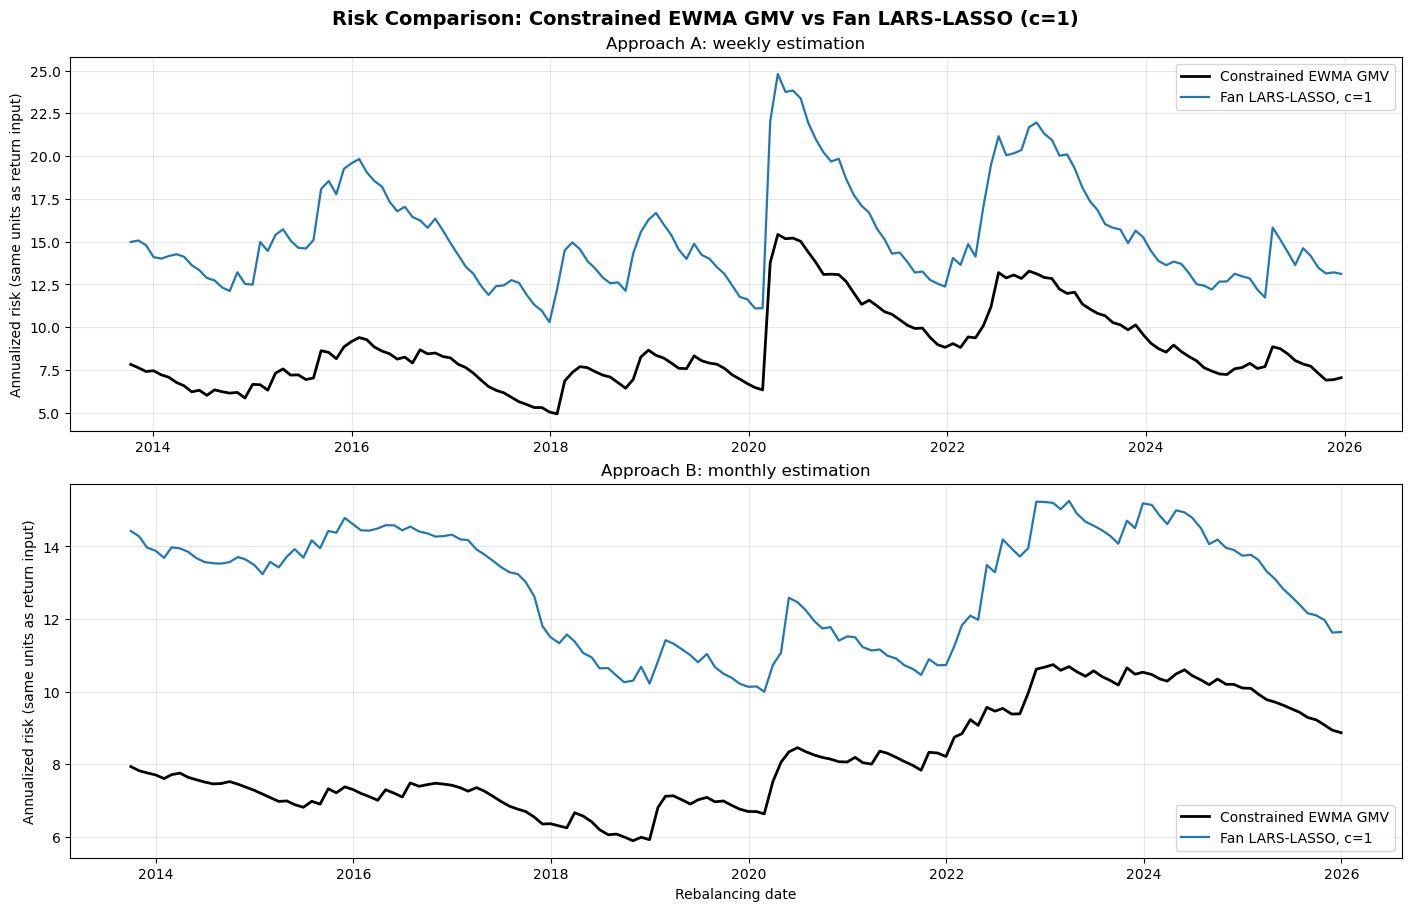

Common comparison period:
Approach A: 2013-10-11 to 2025-12-19 (160 dates)
Approach B: 2013-09-30 to 2025-12-31 (148 dates)

Mean risk comparison:


,GMV EWMA risk,LARS c=1 risk,Risk difference (LARS - GMV),Weight L1 distance
Approach,,,,
Approach A: weekly,8.758002,15.334353,6.576351,1.570478
Approach B: monthly,8.141811,12.902854,4.761043,1.340637


In [30]:

# =============================================================================
# RISK COMPARISON: CONSTRAINED EWMA GMV VS FAN LARS-LASSO (c = 1)
# =============================================================================
# Both portfolios are evaluated with the same rebalancing dates
# This makes the reported risks directly comparable.
#
# Important: equality is not guaranteed here because the LARS c=1 portfolio is
# estimated from a 9-year standardized window, whereas the GMV portfolio uses
# EWMA estimates. The comparison shows the effect of these two estimators.

## setting the comparison date for the 2 portfolio. Since the lasso uses a time-window of 9 years i also put a time window of 9 years for the EWMA GMV 
# portfolio. 
comparison_start_date = pd.Timestamp("2013-09-30")
position_tolerance = 1e-8


def to_naive_timestamp(value):
    """Convert date keys to timezone-naive timestamps for safe comparisons."""
    ## it converts any date into a timezone-naive pandas timestamp. 

    ## convert the input into a pandas timestamp 
    timestamp = pd.Timestamp(value)
    ## removes the timezone information. If it is already timezone-naive, the original timestamp is returned. We have to make date comparison safe. 
    return timestamp.tz_convert(None) if timestamp.tz is not None else timestamp


def ewma_gmv_vs_lars_c1_risk(
    gmv_weights_by_date,
    lars_c1_weights_by_date,
    ewma_covariance_by_date,
    start_date,
    periods_per_year,
    approach_label, 
    ):


    """Compare GMV-EWMA and Fan LARS c=1 risk on their common dates."""
    # the star date is the one above. 
    start_date = to_naive_timestamp(start_date)
    
    gmv_dates = {to_naive_timestamp(date): date for date in gmv_weights_by_date}
    lars_dates = {to_naive_timestamp(date): date for date in lars_c1_weights_by_date}
    covariance_dates = {to_naive_timestamp(date): date for date in ewma_covariance_by_date}

    ## Selecting all the common dates between the gmv,lars and covariance 
    common_dates = sorted(
        set(gmv_dates).intersection(lars_dates).intersection(covariance_dates)
    ) 

    ## keeps the only date are after the chosen date. In my cas this date is : 2013-09-30 

    common_dates = [date for date in common_dates if date >= start_date]
    ## checks whether the filtering producing an empty list, if there are no dates satisfying this condition, then the 2 strategies do not have any comparable 
    ## observation after the chosen start date 
    if not common_dates:
        raise ValueError(f"No common dates for {approach_label} after {start_date.date()}.")
    

    ## This block computes the risk comparison date by date 
    ## creates an empty list. Each comparison date wil produce one dictionary of results, later converted into a DataFrame. 
    rows = []

    ## loops over every date shared by the GMV portfolio, Lars portfolio, and EWMA covariance dictionary. 
    for date in common_dates:
        ## retrieves the GMV weigths for that date 
        w_gmv = pd.Series(gmv_weights_by_date[gmv_dates[date]], dtype=float)
        ## Lars weigths for the same date
        w_lars = pd.Series(lars_c1_weights_by_date[lars_dates[date]], dtype=float)
        ## Covariance EWMA matrix for the same date. 
        sigma = ewma_covariance_by_date[covariance_dates[date]]

        ## keeps only asset presents in the same objective. IMPORTANTE : ADD A CHECK TO COUNT HOW MANY ASSET ARE PRESENT BECAUSE WE NEED FULL ASSET. 

        tickers = w_gmv.index.intersection(w_lars.index).intersection(sigma.index)
        w_gmv = w_gmv.reindex(tickers)
        w_lars = w_lars.reindex(tickers)
        sigma = sigma.loc[tickers, tickers]

        ## check if the alignment didn't create any missing weigths. the function stops if any weigths is missing. 
        if w_gmv.isna().any() or w_lars.isna().any():
            raise ValueError(f"Missing weights in {approach_label} on {date.date()}.")
        

        ## computing the portfolio variance. Note that we have, from the previous script the variance. 
        gmv_variance = float(w_gmv @ sigma @ w_gmv)
        ## computing the Lars variance. 
        lars_variance = float(w_lars @ sigma @ w_lars)
        ##  computes the standard deviations. 
        annualization = np.sqrt(periods_per_year)

        rows.append({
            "Date": date,
            "Approach": approach_label,
            "GMV EWMA risk": np.sqrt(max(gmv_variance, 0.0)) * annualization,
            "LARS c=1 risk": np.sqrt(max(lars_variance, 0.0)) * annualization,
            "Risk difference (LARS - GMV)": (
                np.sqrt(max(lars_variance, 0.0)) - np.sqrt(max(gmv_variance, 0.0))
            ) * annualization, ## Computing the differences between risk. 
            "GMV gross exposure": float(w_gmv.abs().sum()),
            "LARS c=1 gross exposure": float(w_lars.abs().sum()),
            "GMV active positions": int((w_gmv.abs() > position_tolerance).sum()),
            "LARS c=1 active positions": int((w_lars.abs() > position_tolerance).sum()),## Count weigths whose abs value is greater than position tollerance. 
            "Weight L1 distance": float((w_lars - w_gmv).abs().sum()), ## this measure how different the two weight vectors are. 
        })

    return pd.DataFrame(rows).set_index("Date").sort_index() ### convert the list of results into a DataFrame, uses the data as the index, and sorth it in chronological order. 




risk_comparison_A_gmv_ewma_vs_lars_c1 = ewma_gmv_vs_lars_c1_risk(
    weights_A_constrained_gmv_ewma,
    weights_A_lars_lasso_c100,
    rolling_cov_A_ewma,
    comparison_start_date,
    periods_per_year=52,
    approach_label="Approach A: weekly",
)

risk_comparison_B_gmv_ewma_vs_lars_c1 = ewma_gmv_vs_lars_c1_risk(
    weights_B_constrained_gmv_ewma,
    weights_B_lars_lasso_c100,
    rolling_cov_B_ewma,
    comparison_start_date,
    periods_per_year=12,
    approach_label="Approach B: monthly",
)

risk_comparison_gmv_ewma_vs_lars_c1 = pd.concat(
    [risk_comparison_A_gmv_ewma_vs_lars_c1, risk_comparison_B_gmv_ewma_vs_lars_c1]
)

fig, axes = plt.subplots(2, 1, figsize=(14, 9), sharex=False, layout="constrained")
for ax, comparison, title in [
    (axes[0], risk_comparison_A_gmv_ewma_vs_lars_c1, "Approach A: weekly estimation"),
    (axes[1], risk_comparison_B_gmv_ewma_vs_lars_c1, "Approach B: monthly estimation"),
]:
    ax.plot(comparison.index, comparison["GMV EWMA risk"], color="black", linewidth=2.0, label="Constrained EWMA GMV")
    ax.plot(comparison.index, comparison["LARS c=1 risk"], color="tab:blue", linewidth=1.6, label="Fan LARS-LASSO, c=1")
    ax.set_title(title)
    ax.set_ylabel("Annualized risk (same units as return input)")
    ax.grid(True, alpha=0.3)
    ax.legend()

axes[1].set_xlabel("Rebalancing date")
fig.suptitle("Risk Comparison: Constrained EWMA GMV vs Fan LARS-LASSO (c=1)", fontsize=14, fontweight="bold")
plt.savefig("gmv_ewma_vs_lars_c1_risk_comparison.png", dpi=300, bbox_inches="tight")
plt.show()

risk_comparison_summary = (
    risk_comparison_gmv_ewma_vs_lars_c1
    .groupby("Approach")
    [["GMV EWMA risk", "LARS c=1 risk", "Risk difference (LARS - GMV)", "Weight L1 distance"]]
    .mean()
)

print("Common comparison period:")
print(
    f"Approach A: {risk_comparison_A_gmv_ewma_vs_lars_c1.index.min().date()} to "
    f"{risk_comparison_A_gmv_ewma_vs_lars_c1.index.max().date()} "
    f"({len(risk_comparison_A_gmv_ewma_vs_lars_c1)} dates)"
)
print(
    f"Approach B: {risk_comparison_B_gmv_ewma_vs_lars_c1.index.min().date()} to "
    f"{risk_comparison_B_gmv_ewma_vs_lars_c1.index.max().date()} "
    f"({len(risk_comparison_B_gmv_ewma_vs_lars_c1)} dates)"
)

print("\nMean risk comparison:")
display(risk_comparison_summary.round(6))


Equal-weighted benchmark created
Number of assets: 100
Weight per asset: 0.010000
Sum of weights: 1.000000

First 10 weights:
AAPL.O    0.01
MSFT.O    0.01
IBM.N     0.01
ORCL.N    0.01
CSCO.O    0.01
INTC.O    0.01
TXN.O     0.01
QCOM.O    0.01
ADI.O     0.01
ADBE.O    0.01
Name: Equal Weighted, dtype: float64

Expected return of equal-weighted portfolio (weekly estimates): 0.2949%
Expected return of equal-weighted portfolio (monthly estimates): 1.2394%
Volatility of equal-weighted portfolio (weekly estimates): 5.9881%
Volatility of equal-weighted portfolio (monthly estimates): 20.6796%


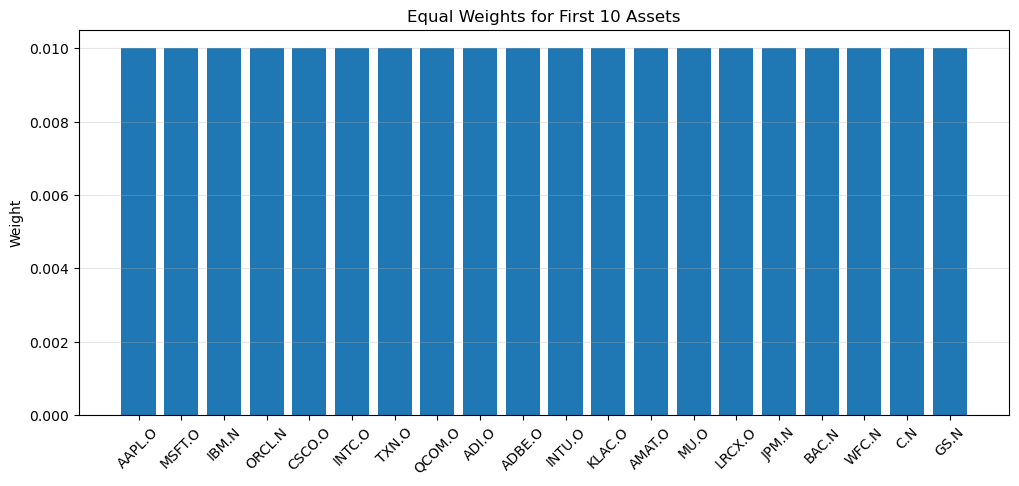

In [31]:
# before implementing the backtesting procedure i will implement the equal-weighted portfolio to serve as a benchmark 
# for my backtesting procedure. Add comment to this function. 
# =============================================================================
# EQUAL-WEIGHTED PORTFOLIO BENCHMARK
# =============================================================================
# Each asset receives the same portfolio weight: w_i = 1 / n.

def equally_weighted_portfolio(tickers):
    tickers = pd.Index(tickers)
    n = len(tickers)
    return pd.Series(1.0 / n, index=tickers, name="Equal Weighted")


# One equal-weight vector for the asset universe.
weights_equal = equally_weighted_portfolio(weekly_return.columns)

# Same benchmark weights aligned to the rebalancing dates of Approach A and B.
weights_equal_A = {
    date: weights_equal.reindex(rolling_mu_A[date].index)
    for date in rolling_mu_A.keys()
}

weights_equal_B = {
    date: weights_equal.reindex(rolling_mu_B[date].index)
    for date in rolling_mu_B.keys()
}

# Period-by-period equal-weight returns, useful for the next backtesting step.
equal_weighted_return_weekly = weekly_return[weights_equal.index] @ weights_equal
equal_weighted_return_monthly = monthly_return[weights_equal.index] @ weights_equal

print("Equal-weighted benchmark created")
print(f"Number of assets: {len(weights_equal)}")
print(f"Weight per asset: {1 / len(weights_equal):.6f}")
print(f"Sum of weights: {weights_equal.sum():.6f}")
print("\nFirst 10 weights:")
print(weights_equal.head(10).round(6))
port_ret_weekly_eq = weights_equal @ rolling_mu_A[last_A]
port_ret_monthly_eq = weights_equal @ rolling_mu_B[last_B]
print(f"\nExpected return of equal-weighted portfolio (weekly estimates): {port_ret_weekly_eq:.4f}%")
print(f"Expected return of equal-weighted portfolio (monthly estimates): {port_ret_monthly_eq:.4f}%")  
prt_var_weekly_eq = (weights_equal @ rolling_cov_A[last_A] @ weights_equal)
print(f"Volatility of equal-weighted portfolio (weekly estimates): {prt_var_weekly_eq:.4f}%")  
prt_var_monthly_eq = (weights_equal @ rolling_cov_B[last_B] @ weights_equal)
print(f"Volatility of equal-weighted portfolio (monthly estimates): {prt_var_monthly_eq:.4f}%")

plt.figure(figsize=(12, 5))
plt.bar(weights_equal.head(20).index, weights_equal.head(20).values)
plt.xticks(rotation=45)
plt.title("Equal Weights for First 10 Assets")
plt.ylabel("Weight")
plt.grid(axis='y', alpha=0.3)
plt.show()


#### MINIMIZATION OF THE CVAR-METRCIS 

Expected shortfall is a risk-measure which measures the avarage of the tail distribution fucntion. it measures the avarage of your worst day. Expeted shortfall answer this question : what is the avarage loss of during the worst X% of outcomes. It can be reformulated as a convex problem. Also it keeps the sub-addititivy property. Since it can be reformulated in a convex set-up, we can minimize the risk-metrics using standard lienar programming tecniques. If the returns are considered normal, the value at risk and the Conditional value at risk are considered equivalent and they provide the same optimal portfolios. The formal portfolio is obtained minimizing the Conditional Value at risk without setting a target return but usually it's standard practise in the industry to minimize an evaluation metrics while pursuing a target return. 
Constraining CvaR also restrics the Value at risk because we have this foundamental property : VaR $\leq$ CvaR. 
In the minimization of the CvaR metrics we are considering the no-short sales portfolio. 

for minimizing the actual return we have $ N $ scenarios of returns denoted by $r_i$ and we define the loss of scenario i as = $l_i = -r_i$
We write the VaR at level $\alpha$ as $VaR_{\alpha}(l) $. The CvaR is then : 
$$ CvaR(\alpha)(l) = E[l|l \ge Var_{\alpha}(l)]$$

We replace the expectation with a sample avarage so we have that  $VaR_{\alpha}(l)$ is the $\alpha$ sample quantile, so $(1 -\alpha) N $ scenarios lie in the tail. thus we have : 

$CvaR(\alpha)(l) = \frac{1}{ (1 - \alpha)N } \sum_{i = 1}^{N} l_i * 1 (l_i \ge l_i)VaR_(\alpha) (l)$ where I is the indicator fucntion. 

We repalce the indicator fucntion with a max function : 

$ CVaR_(\alpha) (l) = VaR_{\alpha}(l) + \frac{1}{(1 - \alpha)N } \sum_{i=1}^N | L_i - VaR_{\alpha} (l)| ^+$

Starting from this form we can make 2 tricks to make the CVaR problem convex : 
We replace the for VaR with an unknown variable $\tau$ and then we have : 

$F(\tau) = \tau + \frac{1} {(1-\alpha)N} \sum_{i=1}^N | l_i - \tau |^+$

If we minimize $F(\tau)$ w.r.t. $\tau$, the value of $\tau $ that minimises $F (\tau)$ is exactly the $VaR(\alpha)$ wo the following equalities holds true : 

$VaR(\alpha) = \argmin_{\tau} F (\tau) $

The second trick is : maximize the function as a linear problem : 

To handle the max function we replace each $|l_i - \tau|_+$, with a slack variable $u_i$  with contraint : 

$u_i \ge l_i - \tau $ and 
$ u_i > 0$

and if we minimize $u_i$ along with $ \tau$, the optimal solution will find the smallest $ u_i $ that satisfies these contraint.  These contraint whcih means : $ u_i = |l_i - \tau|_+$

Putting all together we can write these optimization problem as : 

$$ CVaR_(\alpha) (l) = \min_{\tau,u_i} \tau + \frac{1} {(1-\alpha)N} \sum_{i=1}^{N} u_i$$

subject to : $$ u_i \ge l_i - \tau $$  $$u_i \ge 0 $$ 

In [32]:
# =============================================================================
# PURE REFERENCE-ASSET LASSO-CVaR PORTFOLIOS
# =============================================================================
#
# The Lasso cell now uses the reference-asset regression
#
#     Y_t = R_{N,t},                 X_{i,t} = Y_t - R_{i,t},
#
# and reconstructs the complete portfolio as
#
#     w_i = beta_i,                  i = 1, ..., N-1,
#     w_N = 1 - sum_i(beta_i).
#
# Therefore, the CVaR problem below uses the same beta coordinates. For every
# rebalancing date and gross-exposure limit c, it minimizes historical CVaR
# subject to both the selected Lasso coefficient budget and the portfolio
# gross-exposure constraint:
#
#     minimize    CVaR_alpha( -(Y - X beta) )
#     subject to  ||beta||_1 <= d,
#                 ||w(beta)||_1 <= c.
#
# The coefficient budget d is read from the reference-asset LARS path selected
# in the preceding Lasso cell. The original LARS portfolio is consequently a
# feasible comparator for the same date, d, and c. CVaR is evaluated with raw
# percentage returns converted to decimals; standardized returns are used only
# to estimate the preceding Lasso path.

cvar_confidence_level = 0.95

# Use exactly the same gross-exposure values as the current Lasso analysis.
cvar_gross_exposure_grid = [float(c) for c in gross_exposure_grid]

# These tolerances classify positions and check numerical feasibility. They do
# not clip or renormalize the optimized portfolio after the solver finishes.
CVAR_POSITION_TOLERANCE = 1e-6
CVAR_FEASIBILITY_TOLERANCE = 1e-5


def returns_to_decimal_for_cvar(returns):
    """Convert the notebook's percentage returns to decimal returns."""
    return returns.astype(float).copy() / 100.0


def sample_cvar_from_losses(losses, alpha=0.95):
    """Evaluate historical VaR and CVaR from one finite loss sample."""
    losses = np.asarray(losses, dtype=float).ravel()

    if losses.size == 0:
        raise ValueError("CVaR cannot be computed from an empty loss vector.")
    if not np.isfinite(losses).all():
        raise ValueError("CVaR cannot be computed from non-finite losses.")
    if not 0.0 < alpha < 1.0:
        raise ValueError("alpha must be strictly between zero and one.")

    # Historical VaR is the observed loss at the alpha quantile. The `higher`
    # method avoids creating a loss value through interpolation.
    var_loss = float(np.quantile(losses, alpha, method="higher"))

    # Rockafellar-Uryasev sample CVaR evaluated at the historical VaR threshold.
    excess_loss = np.maximum(losses - var_loss, 0.0)
    cvar_loss = var_loss + float(excess_loss.mean()) / (1.0 - alpha)

    return var_loss, cvar_loss


def recover_raw_lasso_windows(raw_returns, standardized_windows, approach_label):
    """Recover the raw observations underlying each standardized Lasso window."""
    raw_returns = raw_returns.sort_index()
    raw_windows = {}

    for date, standardized_window in sorted(standardized_windows.items()):
        # Reuse exactly the dates and assets selected before standardization.
        raw_window = raw_returns.reindex(
            index=standardized_window.index,
            columns=standardized_window.columns,
        )

        if raw_window.isna().any().any():
            raise ValueError(
                f"{approach_label}: raw returns are missing inside the Lasso "
                f"window ending at {pd.Timestamp(date).date()}."
            )
        if raw_window.shape != standardized_window.shape:
            raise ValueError(
                f"{approach_label}: raw and standardized windows have different "
                f"dimensions at {pd.Timestamp(date).date()}."
            )

        raw_windows[date] = raw_window.astype(float).copy()

    return raw_windows


def minimize_lasso_cvar_with_gross_exposure(
    returns_window,
    lars_weights,
    beta_l1_limit,
    c,
    alpha=0.95,
    position_tolerance=CVAR_POSITION_TOLERANCE,
    feasibility_tolerance=CVAR_FEASIBILITY_TOLERANCE,
):
    """Minimize CVaR in the current reference-asset Lasso coordinates."""
    c = float(c)
    beta_l1_limit = float(beta_l1_limit)

    if c < 1.0:
        raise ValueError("The gross-exposure limit c must be at least one.")
    if beta_l1_limit < -feasibility_tolerance:
        raise ValueError("The Lasso coefficient budget d cannot be negative.")
    if not 0.0 < alpha < 1.0:
        raise ValueError("alpha must be strictly between zero and one.")

    # A very small negative value can only be numerical noise.
    beta_l1_limit = max(beta_l1_limit, 0.0)

    # CVaR concerns actual gains and losses, so use raw uncentered returns in
    # decimal form rather than standardized returns.
    returns_decimal = returns_to_decimal_for_cvar(
        returns_window.dropna(axis=0, how="any").sort_index()
    )

    if returns_decimal.shape[0] < 2:
        return None, None, {
            "Success": False,
            "Status": "insufficient complete return observations",
            "Target c": c,
            "Beta L1 limit": beta_l1_limit,
            "Window observations": returns_decimal.shape[0],
        }

    tickers = pd.Index(returns_decimal.columns)
    scenario_returns = returns_decimal.to_numpy(dtype=float)
    n_observations, n_assets = scenario_returns.shape

    if n_assets < 2:
        raise ValueError("Lasso-CVaR requires at least two assets.")
    if not np.isfinite(scenario_returns).all():
        raise ValueError("The Lasso-CVaR return window contains non-finite values.")

    # Align the LARS comparator to the return matrix. Missing assets are errors:
    # silently dropping an asset would alter both the budget and gross exposure.
    w_lars = pd.Series(lars_weights, dtype=float).reindex(tickers)
    if w_lars.isna().any():
        raise ValueError("The LARS weights and return window use different assets.")
    if not np.isclose(w_lars.sum(), 1.0, atol=feasibility_tolerance):
        raise ValueError("The reference-asset LARS weights do not sum to one.")
    if w_lars.abs().sum() > c + feasibility_tolerance:
        raise ValueError("The reference-asset LARS portfolio violates c.")

    # The Lasso cell uses the final asset as the reference asset.
    reference_asset = tickers[-1]
    other_assets = tickers[:-1]
    reference_position = n_assets - 1
    other_positions = np.arange(n_assets - 1)

    # In the current regression, the non-reference weights are beta and the
    # reference-asset weight is the amount required to make sum(w)=1.
    lars_beta = w_lars.loc[other_assets]
    reconstructed_reference_weight = 1.0 - float(lars_beta.sum())
    if not np.isclose(
        reconstructed_reference_weight,
        float(w_lars.loc[reference_asset]),
        atol=feasibility_tolerance,
    ):
        raise ValueError("The LARS comparator does not satisfy the reference identity.")
    if lars_beta.abs().sum() > beta_l1_limit + feasibility_tolerance:
        raise ValueError("The LARS comparator violates its coefficient budget d.")

    # Build Y and X from the raw scenarios using the same reference asset as the
    # LARS regression: Y = R_N and X_i = Y - R_i.
    Y = scenario_returns[:, reference_position]
    X = Y.reshape(-1, 1) - scenario_returns[:, other_positions]

    # This matrix places beta_i in the weight belonging to non-reference asset i.
    allocation_matrix = np.zeros((n_assets, n_assets - 1), dtype=float)
    allocation_matrix[other_positions, np.arange(n_assets - 1)] = 1.0

    # This vector assigns the residual budget to the reference asset.
    reference_vector = np.zeros(n_assets, dtype=float)
    reference_vector[reference_position] = 1.0

    # beta contains the portfolio weights of the N-1 non-reference assets. The
    # scalar variable var_loss is the optimized VaR threshold, while each entry
    # of excess_losses is the positive loss above that threshold in one scenario.
    beta_variable = cp.Variable(n_assets - 1)
    var_loss = cp.Variable()
    excess_losses = cp.Variable(n_observations, nonneg=True)

    # Reconstruct all N portfolio weights inside CVXPY. The expression satisfies
    # the budget constraint by construction.
    weights_expression = (
        allocation_matrix @ beta_variable
        + reference_vector * (1.0 - cp.sum(beta_variable))
    )

    # This regression residual equals the scenario return of the reconstructed
    # portfolio: Rw(beta) = Y - X beta.
    portfolio_returns_expression = Y - X @ beta_variable
    portfolio_losses_expression = -portfolio_returns_expression

    # Rockafellar-Uryasev linear representation of historical CVaR.
    cvar_expression = var_loss + cp.sum(excess_losses) / (
        (1.0 - alpha) * n_observations
    )

    constraints = [
        # State the portfolio budget explicitly as a numerical safeguard.
        cp.sum(weights_expression) == 1.0,

        # Constrained Lasso: use the same coefficient budget d selected on the
        # corresponding reference-asset LARS path.
        cp.norm1(beta_variable) <= beta_l1_limit,

        # Limit the gross exposure of the complete reconstructed portfolio.
        cp.norm1(weights_expression) <= c,

        # Define each non-negative excess loss above the optimized VaR threshold.
        excess_losses >= portfolio_losses_expression - var_loss,
    ]

    problem = cp.Problem(cp.Minimize(cvar_expression), constraints)

    try:
        problem.solve(solver=cp.GLPK, verbose=False)
    except cp.SolverError as error:
        return None, None, {
            "Success": False,
            "Status": f"Solver error: {error}",
            "Target c": c,
            "Beta L1 limit": beta_l1_limit,
            "Window observations": n_observations,
        }

    success = (
        problem.status in (cp.OPTIMAL, cp.OPTIMAL_INACCURATE)
        and beta_variable.value is not None
        and weights_expression.value is not None
        and cvar_expression.value is not None
    )

    if not success:
        return None, None, {
            "Success": False,
            "Status": problem.status,
            "Target c": c,
            "Beta L1 limit": beta_l1_limit,
            "Window observations": n_observations,
        }

    # Extract the solver result without clipping or renormalizing it.
    beta_array = np.asarray(beta_variable.value, dtype=float).ravel()
    weights_array = np.asarray(weights_expression.value, dtype=float).ravel()
    optimized_beta = pd.Series(
        beta_array,
        index=other_assets,
        name=f"beta c={c:.2f}",
    )
    optimized_weights = pd.Series(
        weights_array,
        index=tickers,
        name=f"Lasso-CVaR c={c:.2f}",
    )

    # Verify the regression identity independently using the numerical weights.
    portfolio_returns = scenario_returns @ weights_array
    regression_returns = Y - X @ beta_array
    if not np.allclose(portfolio_returns, regression_returns, atol=1e-8, rtol=1e-8):
        raise RuntimeError("Lasso-CVaR regression and weights produce different returns.")

    # Recompute historical VaR and CVaR independently from the solved portfolio.
    historical_var, historical_cvar = sample_cvar_from_losses(
        -portfolio_returns,
        alpha=alpha,
    )

    # Evaluate the variance-oriented LARS portfolio on the identical raw return
    # scenarios, giving a paired in-sample comparison.
    lars_returns = scenario_returns @ w_lars.to_numpy(dtype=float)
    lars_var, lars_cvar = sample_cvar_from_losses(-lars_returns, alpha=alpha)
    cvar_reduction = lars_cvar - historical_cvar

    weight_sum = float(optimized_weights.sum())
    gross_exposure = float(optimized_weights.abs().sum())
    optimized_beta_l1 = float(optimized_beta.abs().sum())
    minimum_weight = float(optimized_weights.min())

    # Check all constraints without modifying the optimizer's solution.
    budget_violation = abs(weight_sum - 1.0)
    exposure_violation = max(0.0, gross_exposure - c)
    beta_l1_violation = max(0.0, optimized_beta_l1 - beta_l1_limit)
    c1_short_violation = (
        max(0.0, -minimum_weight) if np.isclose(c, 1.0) else 0.0
    )
    maximum_constraint_violation = max(
        budget_violation,
        exposure_violation,
        beta_l1_violation,
        c1_short_violation,
    )

    if maximum_constraint_violation > feasibility_tolerance:
        return None, None, {
            "Success": False,
            "Status": "solver solution failed feasibility checks",
            "Target c": c,
            "Beta L1 limit": beta_l1_limit,
            "Window observations": n_observations,
            "Weight sum": weight_sum,
            "Gross exposure": gross_exposure,
            "Optimized beta L1": optimized_beta_l1,
            "Maximum constraint violation": maximum_constraint_violation,
        }

    # The original LARS portfolio is feasible under the same d and c, so the
    # optimized in-sample CVaR should not be greater apart from solver tolerance.
    if cvar_reduction < -feasibility_tolerance:
        return None, None, {
            "Success": False,
            "Status": "Lasso-CVaR did not dominate its feasible LARS comparator",
            "Target c": c,
            "Beta L1 limit": beta_l1_limit,
            "Window observations": n_observations,
            "Optimization CVaR": float(cvar_expression.value),
            "Historical CVaR check": historical_cvar,
            "LARS CVaR": lars_cvar,
            "CVaR reduction vs LARS": cvar_reduction,
        }

    diagnostics = {
        "Success": True,
        "Status": problem.status,
        "Target c": c,
        "Window observations": n_observations,
        "Approximate tail observations": int(
            np.ceil((1.0 - alpha) * n_observations)
        ),
        "Beta L1 limit": beta_l1_limit,
        "Optimized beta L1": optimized_beta_l1,
        "Unused beta L1": beta_l1_limit - optimized_beta_l1,
        "Optimization CVaR": float(cvar_expression.value),
        "Historical VaR check": historical_var,
        "Historical CVaR check": historical_cvar,
        "LARS VaR": lars_var,
        "LARS CVaR": lars_cvar,
        "CVaR reduction vs LARS": cvar_reduction,
        "CVaR reduction vs LARS (%)": (
            cvar_reduction / abs(lars_cvar) * 100
            if abs(lars_cvar) > 1e-12
            else np.nan
        ),
        "Expected period return": float(np.mean(portfolio_returns)),
        "LARS expected period return": float(np.mean(lars_returns)),
        "Period volatility": float(np.std(portfolio_returns, ddof=1)),
        "LARS period volatility": float(np.std(lars_returns, ddof=1)),
        "Weight sum": weight_sum,
        "Gross exposure": gross_exposure,
        "Unused gross exposure": c - gross_exposure,
        "Active positions": int(
            (optimized_weights.abs() > position_tolerance).sum()
        ),
        "Long positions": int(
            (optimized_weights > position_tolerance).sum()
        ),
        "Short positions": int(
            (optimized_weights < -position_tolerance).sum()
        ),
        "Total short weight": float(-optimized_weights.clip(upper=0.0).sum()),
        "Lasso coefficients": int(
            (optimized_beta.abs() > position_tolerance).sum()
        ),
        "Reference asset": reference_asset,
        "Minimum weight": minimum_weight,
        "Maximum weight": float(optimized_weights.max()),
        "Maximum constraint violation": maximum_constraint_violation,
    }

    return optimized_weights, optimized_beta, diagnostics


def build_rolling_lasso_cvar_weights(
    rolling_return_windows,
    lars_weights_by_c,
    lars_selected_info,
    c_grid,
    approach_label,
    alpha=0.95,
):
    """Estimate one reference-asset Lasso-CVaR portfolio per date and c."""
    c_grid = sorted(float(c) for c in c_grid)

    if len(c_grid) == 0:
        raise ValueError("The Lasso-CVaR gross-exposure grid cannot be empty.")
    if len(set(c_grid)) != len(c_grid):
        raise ValueError("The Lasso-CVaR gross-exposure grid contains duplicates.")
    if c_grid[0] < 1.0:
        raise ValueError("Every gross-exposure limit must be at least one.")

    # Store rolling weights and beta coefficients separately for each c.
    weights_by_c = {c: {} for c in c_grid}
    betas_by_c = {c: {} for c in c_grid}
    result_rows = []

    # Every raw return window uses the same dates as its past-only standardized
    # Lasso window, preserving the out-of-sample chronology.
    for date, returns_window in sorted(rolling_return_windows.items()):
        for c in c_grid:
            if c not in lars_weights_by_c or date not in lars_weights_by_c[c]:
                raise KeyError(f"Missing reference-asset LARS weights for c={c:.2f} at {date}.")

            # Reuse the d = ||beta_LARS||_1 value selected in the Lasso cell.
            beta_l1_limit = float(lars_selected_info.loc[(date, c), "Beta L1"])

            weights, beta, diagnostics = minimize_lasso_cvar_with_gross_exposure(
                returns_window=returns_window,
                lars_weights=lars_weights_by_c[c][date],
                beta_l1_limit=beta_l1_limit,
                c=c,
                alpha=alpha,
            )

            # Store only solutions that passed the solver and feasibility checks.
            if diagnostics["Success"]:
                weights_by_c[c][date] = weights
                betas_by_c[c][date] = beta

            result_rows.append({
                "Date": date,
                "Approach": approach_label,
                **diagnostics,
            })

    results = (
        pd.DataFrame(result_rows)
        .set_index(["Date", "Target c"])
        .sort_index()
    )

    return weights_by_c, betas_by_c, results


def validate_rolling_lasso_cvar_results(
    weights_by_c,
    betas_by_c,
    results,
    expected_dates,
    c_grid,
    approach_label,
):
    """Check calendar coverage, feasibility, and in-sample CVaR dominance."""
    expected_dates = pd.Index(expected_dates)
    c_grid = sorted(float(c) for c in c_grid)

    for c in c_grid:
        weight_dates = pd.Index(weights_by_c[c].keys())
        beta_dates = pd.Index(betas_by_c[c].keys())
        missing_weight_dates = expected_dates.difference(weight_dates)
        missing_beta_dates = expected_dates.difference(beta_dates)
        extra_dates = weight_dates.difference(expected_dates)
        results_c = results.xs(c, level="Target c")
        failed_dates = int((~results_c["Success"]).sum())

        if (
            len(missing_weight_dates) > 0
            or len(missing_beta_dates) > 0
            or len(extra_dates) > 0
            or failed_dates > 0
        ):
            raise RuntimeError(
                f"Incomplete {approach_label} Lasso-CVaR results for c={c:.2f}: "
                f"{len(missing_weight_dates)} missing weights, "
                f"{len(missing_beta_dates)} missing betas, "
                f"{len(extra_dates)} extra dates, {failed_dates} failed dates."
            )

        # The paired LARS portfolio is feasible under the same d and c.
        if (
            results_c["CVaR reduction vs LARS"]
            < -CVAR_FEASIBILITY_TOLERANCE
        ).any():
            raise RuntimeError(
                f"{approach_label}: Lasso-CVaR fails to dominate LARS "
                f"in sample for c={c:.2f}."
            )

        # With sum(w)=1 and ||w||_1<=1, c=1 implies a long-only portfolio.
        if np.isclose(c, 1.0) and (
            results_c["Minimum weight"] < -CVAR_FEASIBILITY_TOLERANCE
        ).any():
            raise RuntimeError(
                f"{approach_label}: the c=1 Lasso-CVaR portfolio contains shorts."
            )


# Recover the raw nine-year observations corresponding exactly to the current
# standardized Lasso windows. This replaces the deleted rolling_return_*_lasso_9y
# objects without recomputing or changing the rolling calendar.
rolling_return_A_lasso_cvar_9y = recover_raw_lasso_windows(
    weekly_return,
    rolling_return_A_standardized,
    "Approach A",
)
rolling_return_B_lasso_cvar_9y = recover_raw_lasso_windows(
    monthly_return,
    rolling_return_B_standardized,
    "Approach B",
)


(
    weights_A_lasso_cvar_by_c,
    betas_A_lasso_cvar_by_c,
    df_results_A_lasso_cvar_by_c,
) = build_rolling_lasso_cvar_weights(
    rolling_return_windows=rolling_return_A_lasso_cvar_9y,
    lars_weights_by_c=weights_A_reference_lars_lasso_by_c,
    lars_selected_info=df_reference_lars_A_selected,
    c_grid=cvar_gross_exposure_grid,
    approach_label="Approach A - weekly scenarios",
    alpha=cvar_confidence_level,
)


(
    weights_B_lasso_cvar_by_c,
    betas_B_lasso_cvar_by_c,
    df_results_B_lasso_cvar_by_c,
) = build_rolling_lasso_cvar_weights(
    rolling_return_windows=rolling_return_B_lasso_cvar_9y,
    lars_weights_by_c=weights_B_reference_lars_lasso_by_c,
    lars_selected_info=df_reference_lars_B_selected,
    c_grid=cvar_gross_exposure_grid,
    approach_label="Approach B - monthly scenarios",
    alpha=cvar_confidence_level,
)


validate_rolling_lasso_cvar_results(
    weights_A_lasso_cvar_by_c,
    betas_A_lasso_cvar_by_c,
    df_results_A_lasso_cvar_by_c,
    weekly_lasso_rebalancing_dates,
    cvar_gross_exposure_grid,
    "Approach A",
)
validate_rolling_lasso_cvar_results(
    weights_B_lasso_cvar_by_c,
    betas_B_lasso_cvar_by_c,
    df_results_B_lasso_cvar_by_c,
    canonical_lasso_rebalancing_dates,
    cvar_gross_exposure_grid,
    "Approach B",
)


# Backtest-ready dictionaries. These names are already used by the portfolio
# registry in the backtesting section.
weights_A_lasso_cvar_c100 = weights_A_lasso_cvar_by_c[1.00]
weights_A_lasso_cvar_c125 = weights_A_lasso_cvar_by_c[1.25]
weights_A_lasso_cvar_c150 = weights_A_lasso_cvar_by_c[1.50]
weights_A_lasso_cvar_c200 = weights_A_lasso_cvar_by_c[2.00]
weights_A_lasso_cvar_c250 = weights_A_lasso_cvar_by_c[2.50]


weights_B_lasso_cvar_c100 = weights_B_lasso_cvar_by_c[1.00]
weights_B_lasso_cvar_c125 = weights_B_lasso_cvar_by_c[1.25]
weights_B_lasso_cvar_c150 = weights_B_lasso_cvar_by_c[1.50]
weights_B_lasso_cvar_c200 = weights_B_lasso_cvar_by_c[2.00]
weights_B_lasso_cvar_c250 = weights_B_lasso_cvar_by_c[2.50]



# Store all rolling weights and beta coefficients in MultiIndex DataFrames.
df_weights_A_lasso_cvar_by_c = pd.concat(
    {
        c: pd.DataFrame(weights_by_date).T.sort_index()
        for c, weights_by_date in weights_A_lasso_cvar_by_c.items()
    },
    names=["Target c", "Date"],
)
df_weights_B_lasso_cvar_by_c = pd.concat(
    {
        c: pd.DataFrame(weights_by_date).T.sort_index()
        for c, weights_by_date in weights_B_lasso_cvar_by_c.items()
    },
    names=["Target c", "Date"],
)
df_betas_A_lasso_cvar_by_c = pd.concat(
    {
        c: pd.DataFrame(betas_by_date).T.sort_index()
        for c, betas_by_date in betas_A_lasso_cvar_by_c.items()
    },
    names=["Target c", "Date"],
)
df_betas_B_lasso_cvar_by_c = pd.concat(
    {
        c: pd.DataFrame(betas_by_date).T.sort_index()
        for c, betas_by_date in betas_B_lasso_cvar_by_c.items()
    },
    names=["Target c", "Date"],
)


def summarize_lasso_cvar_comparison(results, c_grid, approach_label):
    """Summarize the paired in-sample LARS and Lasso-CVaR comparison."""
    rows = []

    for c in sorted(float(value) for value in c_grid):
        results_c = results.xs(c, level="Target c")
        average_lars_cvar = results_c["LARS CVaR"].mean()
        average_lasso_cvar = results_c["Historical CVaR check"].mean()
        average_reduction = results_c["CVaR reduction vs LARS"].mean()

        rows.append({
            "Approach": approach_label,
            "Target c": c,
            "Portfolios": len(results_c),
            "First date": results_c.index.min(),
            "Last date": results_c.index.max(),
            "Average LARS CVaR (%)": average_lars_cvar * 100,
            "Average Lasso-CVaR (%)": average_lasso_cvar * 100,
            "Average CVaR reduction (percentage points)": average_reduction * 100,
            "Average CVaR reduction relative to LARS (%)": (
                average_reduction / abs(average_lars_cvar) * 100
                if abs(average_lars_cvar) > 1e-12
                else np.nan
            ),
            "Dates Lasso-CVaR no worse than LARS (%)": (
                (
                    results_c["CVaR reduction vs LARS"]
                    >= -CVAR_FEASIBILITY_TOLERANCE
                ).mean()
                * 100
            ),
            "Average beta L1 limit": results_c["Beta L1 limit"].mean(),
            "Average optimized beta L1": results_c["Optimized beta L1"].mean(),
            "Average gross exposure": results_c["Gross exposure"].mean(),
            "Average active positions": results_c["Active positions"].mean(),
            "Average short positions": results_c["Short positions"].mean(),
        })

    return pd.DataFrame(rows)


# This table compares the variance-oriented LARS portfolio with the direct
# Lasso-CVaR portfolio for the same date, coefficient budget d, and exposure c.
df_lasso_cvar_comparison_summary = pd.concat(
    [
        summarize_lasso_cvar_comparison(
            df_results_A_lasso_cvar_by_c,
            cvar_gross_exposure_grid,
            "Approach A - weekly scenarios",
        ),
        summarize_lasso_cvar_comparison(
            df_results_B_lasso_cvar_by_c,
            cvar_gross_exposure_grid,
            "Approach B - monthly scenarios",
        ),
    ],
    ignore_index=True,
).set_index(["Approach", "Target c"])


print("Reference-asset Lasso-CVaR rolling optimization complete")
print(
    f"Monthly rebalancing period: {canonical_lasso_rebalancing_dates[0].date()} to "
    f"{canonical_lasso_rebalancing_dates[-1].date()}"
)
print(f"CVaR confidence level: {cvar_confidence_level:.0%}")
print(f"Gross-exposure grid: {cvar_gross_exposure_grid}")
print("Each date-c comparison uses the same LARS coefficient budget d.")
print("Approach A uses weekly scenarios; Approach B uses monthly scenarios.")

display(df_lasso_cvar_comparison_summary.round(4))


# Display the latest date-c diagnostics as well as the average summary.
latest_lasso_cvar_date = canonical_lasso_rebalancing_dates[-1]
latest_weekly_lasso_cvar_date = weekly_lasso_rebalancing_dates[-1]
latest_lasso_cvar_diagnostics = pd.concat(
    [
        df_results_A_lasso_cvar_by_c.xs(
            latest_weekly_lasso_cvar_date,
            level="Date",
        ).assign(Approach="Weekly"),
        df_results_B_lasso_cvar_by_c.xs(
            latest_lasso_cvar_date,
            level="Date",
        ).assign(Approach="Monthly"),
    ]
)

print(f"\nLatest Lasso-CVaR dates: weekly {latest_weekly_lasso_cvar_date.date()}, monthly {latest_lasso_cvar_date.date()}:")
display(
    latest_lasso_cvar_diagnostics[
        [
            "Approach",
            "Beta L1 limit",
            "Optimized beta L1",
            "LARS CVaR",
            "Historical CVaR check",
            "CVaR reduction vs LARS",
        ]
    ].round(6)
)


Reference-asset Lasso-CVaR rolling optimization complete
Monthly rebalancing period: 2013-09-30 to 2025-12-31
CVaR confidence level: 95%
Gross-exposure grid: [1.0, 1.25, 1.5, 2.0, 2.5]
Each date-c comparison uses the same LARS coefficient budget d.
Approach A uses weekly scenarios; Approach B uses monthly scenarios.


Portfolios                First date  \
Approach                       Target c                                         
Approach A - weekly scenarios  1.00             162 2013-08-16 00:00:00+00:00   
                               1.25             162 2013-08-16 00:00:00+00:00   
                               1.50             162 2013-08-16 00:00:00+00:00   
                               2.00             162 2013-08-16 00:00:00+00:00   
                               2.50             162 2013-08-16 00:00:00+00:00   
Approach B - monthly scenarios 1.00             148 2013-09-30 00:00:00+00:00   
                               1.25             148 2013-09-30 00:00:00+00:00   
                               1.50             148 2013-09-30 00:00:00+00:00   
                               2.00             148 2013-09-30 00:00:00+00:00   
                               2.50             148 2013-09-30 00:00:00+00:00   

                                                        Last date  \
Approach                       Target c                             
Approach A - weekly scenarios  1.00     2025-12-19 00:00:00+00:00   
                               1.25     2025-12-19 00:00:00+00:00   
                               1.50     2025-12-19 00:00:00+00:00   
                               2.00     2025-12-19 00:00:00+00:00   
                               2.50     2025-12-19 00:00:00+00:00   
Approach B - monthly scenarios 1.00     2025-12-31 00:00:00+00:00   
                               1.25     2025-12-31 00:00:00+00:00   
                               1.50     2025-12-31 00:00:00+00:00   
                               2.00     2025-12-31 00:00:00+00:00   
                               2.50     2025-12-31 00:00:00+00:00   

                                         Average LARS CVaR (%)  \
Approach                       Target c                          
Approach A - weekly scenarios  1.00                     4.7408   
                               1.25                     4.6576   
                               1.50                     4.6088   
                               2.00                     4.5445   
                               2.50                     4.5166   
Approach B - monthly scenarios 1.00                     6.0217   
                               1.25                     5.8341   
                               1.50                     5.6312   
                               2.00                     5.1595   
                               2.50                     4.8271   

                                         Average Lasso-CVaR (%)  \
Approach                       Target c                           
Approach A - weekly scenarios  1.00                      3.1668   
                               1.25                      2.8149   
                               1.50                      2.5936   
                               2.00                      2.2702   
                               2.50                      2.0375   
Approach B - monthly scenarios 1.00                      3.3472   
                               1.25                      2.3368   
                               1.50                      1.6755   
                               2.00                      0.7626   
                               2.50                      0.2213   

                                         Average CVaR reduction (percentage points)  \
Approach                       Target c                                               
Approach A - weekly scenarios  1.00                                          1.5740   
                               1.25                                          1.8428   
                               1.50                                          2.0152   
                               2.00                                          2.2743   
                               2.50                                          2.4791   
Approach B - monthly scenarios 1


Latest Lasso-CVaR dates: weekly 2025-12-19, monthly 2025-12-31:


,Approach,Beta L1 limit,Optimized beta L1,LARS CVaR,Historical CVaR check,CVaR reduction vs LARS
Target c,,,,,,
1.00,Weekly,0.948929,0.948929,0.049096,0.035605,0.013491
1.25,Weekly,1.193337,1.193337,0.047925,0.031866,0.016059
1.50,Weekly,1.463693,1.463693,0.047666,0.029433,0.018233
2.00,Weekly,1.982265,1.982265,0.047670,0.025833,0.021837
2.50,Weekly,2.484316,2.484316,0.048054,0.023452,0.024602
1.00,Monthly,0.908644,0.908644,0.055719,0.038211,0.017508
1.25,Monthly,1.176289,1.176289,0.056506,0.030533,0.025973
1.50,Monthly,1.407460,1.407460,0.057189,0.025033,0.032157
2.00,Monthly,1.903538,1.903538,0.057643,0.015238,0.042405


#### IMPLEMENTATION OF THE BACKTESTING PROCEDURE

Approach A estimates with 468 weekly observations, trades at that weekly close,
holds for four weekly observations, and rolls the window forward by four.
The first realized return is the observation after the decision close. We record
every weekly return with drifting weights and costs only at four-week trades.
Four weeks is about 13 rebalances per year, not a calendar-month schedule.
The remaining weeks at the end of the file are retained as a partial block.

Approach B keeps its original monthly estimation calendar, monthly returns,
backtest function and cost convention. Comparisons, benchmarks and risk metrics
are computed separately at each return frequency (52/year for A, 12/year for B).
The two series are never intersected on monthly end dates.


In [33]:

# =============================================================================
# IMPLEMENTATION OF THE BACKTESTING PROCEDURE
# =============================================================================
# The original function below remains the monthly backtest for Approach B.
# Approach A uses backtest_weekly_portfolio, defined later in this cell, with
# weekly returns and an independent four-week trading schedule.
## IMPORTANT: the strict OOS comparison below uses only rolling weights already computed before each realized period.
# remember implememnt the procedure for different values of upper and lower bound. store the weigths and then appleid the procedure for the backtesting. 
# it do not account for the implementaiton cost. we fix the transaction cost at 20 bps. 
## IMPORTANT IMPLEMENT ALSO THE CONDITIONAL VALUE AT RISK IN THE BACKTESTING PROCEDURE. 
## missing the implementaiton of the l1 lasso regression. 

TRANSACTION_COST = 0.002        # 20 basis points per unit of turnover. avarages turnover fro montly rebalanced are around 0.2 - 0.5. 
PERIODS_PER_YEAR = 12           # monthly realized returns for performance ratios
RISK_FREE_RATE = 0.0            # annual risk-free rate. Change it if you add an RF series.
INCLUDE_INITIAL_TRADE_COST = False
CARDINALITY_TOL = 1e-8

## i have implement it to be consistent with the formula (1+r_t) where r_t is expressed as a decimal.
 
def to_decimal_returns(returns):# taking the returns as a decimal part because the return are not expressed as decimal in the data. 
    """Convert returns to decimals if the notebook data are expressed in percent."""
    r = returns.astype(float).copy() #casting return as float and  of the series. 
    #if r.abs().quantile(0.99).max() > 1.0:# if the 99th percentile of the absolute 
       # r = r / 100.0
    return r/100.0 # computing the %returns


def period_asset_return(returns_decimal, start_date, end_date):
    """Buy-and-hold asset return over (start_date, end_date].
    the interval is start date and end date. """
    # select all the returns after the rebalancing dates and up to the next rebalancing dates. 
    # we keep the end date and not the start date because we want to compute the return of the portfolio at the end of the period. 
    ## date > 2020-01-31 and date <= 2020-02-29
    # Safety check:
    # if the selected block is empty, but end_date exists in the return index,
    # take exactly the return observed at end_date.


    block = returns_decimal.loc[
        (returns_decimal.index > start_date) & (returns_decimal.index <= end_date)
    ]
    if block.empty and end_date in returns_decimal.index:
        block = returns_decimal.loc[[end_date]]

    # If we still do not have any realized return for this period,
    #return None. The backtest function will skip this period.

    if block.empty:
        return None
    # Compound the returns inside the holding period. If block contains one monthly return, this simply returns that monthly return.
    # If block contains several weekly returns inside one monthly holding period, this computes:
    # (1 + r_1)(1 + r_2)...(1 + r_k) - 1
    # axis=0 means that the product is computed column by column,
    # so we obtain one realized return for each asset.
    return (1.0 + block).prod(axis=0) - 1.0 # note that here we use pandas.prod for computing the product of the return. 


def backtest_rebalanced_portfolio(
    weights_by_date,
    realized_returns,
    name,
    transaction_cost=TRANSACTION_COST,
    periods_per_year=PERIODS_PER_YEAR,
    initial_value=1.0,
    include_initial_trade_cost=INCLUDE_INITIAL_TRADE_COST):
    """Backtest one rebalanced portfolio using already-computed weights.
    Main formulas used:
    remember w_{i,t} is equal to the weight of asset i at time t.
    return of portfolio at time t = w_t' r_t. # portfolio return at time t 
    w_hat_{i,t} = (w_{i,t} * (1 + r_{i,t}) / w_t * (1 + r_t) # chekc this formula because i don't know if it is correct. 
    turnover_t = sum_i |w_{i,t} - w_hat_{i,t-1}| 
    net portfolio value at time t : V_t = V_{t-1} * (1-0.02|w_t - w_hat_{t-1}| 1_n ) where 1_n is a vector of ones of size n. 
    net_return_t = (1 - transaction_cost * turnover_t) * (1 + gross_return_t) - 1 # this formula do not appear on the slide. 
    """
    returns_decimal = to_decimal_returns(realized_returns) # transform the returns as decimal. 
    dates = sorted(pd.to_datetime(list(weights_by_date.keys())))# dates with rebalancing weights.


    # we need at least 2 dates to compute the return of the portfolio, date t = portfolio formation and rebalancing dates. 
    #date t = portfolio formation rebalancing dates 
    #date t+1 = date where we observed the realized return of the portfolio. 
    if len(dates) < 2: 
        return pd.DataFrame()

    rows = []
    portfolio_value = initial_value
    previous_drifted_weights = None #  

    # rebalancing dates is the date 

    for i in range(len(dates) - 1): # dates_0 > date_1, date_1 -> date_2 so we take the -1 to avoid index error. 
        rebalance_date = dates[i] # selecting the date at the start of the period. 
        end_date = dates[i + 1] # selecting the dates at the end of the period. 
        # select the dates at the end of the period because we 


        #asset realized returns between rebalance_date and end_date. 
        # if monthly returns are used, this is ususally just one monthly return 
        # if weekly retunrs are used with monthly rebalancing dates, this compound
        #all weeekly returns inside the montlhy 

        asset_return = period_asset_return(returns_decimal, rebalance_date, end_date)
        if asset_return is None:
            raise ValueError(" insert the correct date. PAy attentation blocks are not working.")
            #print(f"Warning: no returns available for period ({rebalance_date}, {end_date}]. Skipping.")
            #continue

        # portfolio weigths are choosen at the beggining of the period 
        weights = pd.Series(weights_by_date[rebalance_date], dtype=float)

        # keep only assets that are present both in the weigth vector and in the realized return vector. 
        tickers = weights.index.intersection(asset_return.index)# taking the intersection of the tickers for which we have weigths and the tickers for which we have returns. 

        # Safety checks: report assets that cannot be matched between weights and returns.
        # we can remove because the weight index match the return index. 
        missing_returns = weights.index.difference(asset_return.index)
        missing_weights = asset_return.index.difference(weights.index)

        if len(missing_returns) > 0:
            print(
                f"Warning: {len(missing_returns)} assets have weights but no realized returns "
                f"for period ({rebalance_date}, {end_date}]. Example: {list(missing_returns[:5])}"
            )

        if len(missing_weights) > 0:
            print(
                f"Warning: {len(missing_weights)} assets have realized returns but no portfolio weights "
                f"for period ({rebalance_date}, {end_date}]. Example: {list(missing_weights[:5])}"
            )

        if len(tickers) == 0:
            print(f"Warning: no common assets for period ({rebalance_date}, {end_date}]. Skipping.")
            continue

        
        if weights.isna().any() or asset_return.isna().any():
            print(f"Warning: NaN values after alignment for period ({rebalance_date}, {end_date}]. Skipping.")
            continue



        # skipping the period if the weigths are invalid or non numerical stable. 
        if weights.empty or not np.isfinite(weights.values).all():
            print(f"Warning: invalid weights for period starting at {rebalance_date}. Skipping.")
            continue


        # turnover measures how much the portfolio must trade at the beginning of the period to move from the previous drifted allocations
        # to the new target allocation. 
        # for the first period, we can either charge the initial investment trade or set the turnover equal to zero. In the current setting we 
        # do not charge the initial trade unless include initial_trade_cost = True. 
        # this block computes turnover. this correspond with turnover = sum_i_[|w_{i,t} - w_hat_{i,t-1}|] in the formula.
        if previous_drifted_weights is None:
            turnover = weights.abs().sum()  ## we can insert now the transaction cost as we would. 
        else:
            previous_drifted_weights = previous_drifted_weights.reindex(tickers)
            turnover = float((weights - previous_drifted_weights).abs().sum())



        
        # transaction cost paid at the beginning of the holding period. 
        # i think we can change the formula for the transaction cost paid because in this way we are not consi
        # without transaction cost set turnover = 0.0 so we see the portfolio without transaction cost. 
        transaction_cost_paid = transaction_cost * turnover
        # realized portfolio return between rebalance_date and end_date 
        gross_return = float(weights @ asset_return)

        # Explicit portfolio-value recursion:
        # 1. start the period with V_{t-1}
        # 2. pay transaction costs when rebalancing
        # 3. earn the realized portfolio return over the holding period
        value_before_trade = portfolio_value
        value_after_trade = value_before_trade * (1.0 - transaction_cost_paid)
        value_end_period = value_after_trade * (1.0 + gross_return)
        net_return = value_end_period / value_before_trade - 1.0
        portfolio_value = value_end_period

        # end of the period drifted weigths. 
        # w_hat_i = w_i * (1 + r_i) / (1 + r_p) 
        denominator = 1.0 + gross_return # this is equal to 1 + r_p in the slide, where r_p is the return of the portfolio. 
        if abs(denominator) > 1e-12:
            drifted_weights = weights * (1.0 + asset_return) / denominator # this computes w_i,t * (1 + r_i,t) / (1 + r_p,t)
        else:
            print(f"Warning: gross return is too close to -100% for period ({rebalance_date}, {end_date}]. Setting drifted weights to NaN.")
            drifted_weights = pd.Series(np.nan, index=tickers)
        previous_drifted_weights = drifted_weights # stores the end-of-period weigths so that, at the next rebalancing dates, turnover can be computed as : turnover = sum |new target weights - previous drifted weights|

        # Concentration relative to the equally weighted portfolio. These are
        # computed from the target weights used at this rebalancing date.

        rows.append({
            'portfolio': name,
            'rebalance_date': rebalance_date,
            'end_date': end_date,
            'value_before_trade': value_before_trade,
            'value_after_trade': value_after_trade,
            'gross_return': gross_return,
            'net_return': net_return,
            'portfolio_value': portfolio_value,
            'turnover': turnover,
            'transaction_cost_paid': transaction_cost_paid,
            # Count economically active, long and short positions using the
            # same tolerance, so cardinality equals long plus short positions.
            'cardinality': int((weights.abs() > CARDINALITY_TOL).sum()),
            'long_positions': int((weights > CARDINALITY_TOL).sum()),
            'short_positions': int((weights < -CARDINALITY_TOL).sum()),
            'gross_exposure': float(weights.abs().sum()),
            'weight_sum': float(weights.sum()),
        })

    df = pd.DataFrame(rows)
    if df.empty:
        print(f"Warning: no valid backtest results for portfolio {name}. Returning empty DataFrame.")
        return df

    #print(f" the datafeame that we have just created is the following :\n {df.head(3)}")

    df = df.set_index('end_date').sort_index()# makes the end date of the period as the index of the dataframe. 
    # the end date becomes the dataframe index then sorted. 
    
    #Rolling realized risk : standard deviation of monthly net returns over the last 12 months,annualized by multiplying by sqrt(12)
    # check if this composition are correct. 
    df['rolling_realized_return'] = df['net_return'].rolling(12).mean() * periods_per_year # pay attention it take the net return with computing the cost 
    df['rolling_realized_risk'] = df['net_return'].rolling(12).std(ddof=1) * np.sqrt(periods_per_year)# this computes the realized risk = std 
    return df
# computing the sample standard deviations with ddof = 1 because we are computing the sample standard deviations. 













# -----------------------------------------------------------------------------
# Approach A: weekly observations, re-estimation and trading every four weeks.
# The monthly backtest above is retained unchanged for Approach B.
# -----------------------------------------------------------------------------
WEEKLY_PERIODS_PER_YEAR = 52


def backtest_weekly_portfolio(
    weights_by_date, realized_returns, name,
    transaction_cost=TRANSACTION_COST, initial_value=1.0,
    include_initial_trade_cost=True,
    window_observations=WEEKLY_WINDOW_OBS,
    rebalance_every=WEEKLY_REBALANCE_OBS,
):
    """Record every weekly return; trade at observation W, W+4, W+8, ... .

    The return at a decision date belongs to the window just observed. New
    weights apply only to the NEXT observation. Between trades, holdings drift.
    The monthly implementation already charges formation costs; True preserves
    that convention for A without changing the monthly implementation or flag.
    """
    r = to_decimal_returns(realized_returns).sort_index()
    if not isinstance(r.index, pd.DatetimeIndex) or r.index.has_duplicates:
        raise ValueError("Weekly returns require unique datetime observation dates.")
    if r.columns.has_duplicates or not np.isfinite(r.to_numpy()).all():
        raise ValueError("Weekly returns require unique assets and complete finite values.")
    if (r < -1.0).any().any():
        raise ValueError("An asset simple return cannot be below -100%.")
    if window_observations < 2 or rebalance_every < 1 or len(r) <= window_observations:
        raise ValueError("Insufficient weekly history or invalid window/rebalance count.")
    if initial_value <= 0 or transaction_cost < 0:
        raise ValueError("Initial wealth must be positive and costs nonnegative.")

    # Use every original weekly observation. Do not silently drop a missing week
    # or map decisions to a calendar derived from the monthly dataset.
    decision_positions = range(window_observations - 1, len(r) - 1, rebalance_every)
    expected_dates = pd.DatetimeIndex([r.index[p] for p in decision_positions])
    targets = {pd.Timestamp(date): pd.Series(w, dtype=float)
               for date, w in weights_by_date.items()}
    actual_dates = pd.DatetimeIndex(sorted(targets))
    if not actual_dates.equals(expected_dates):
        raise ValueError(
            "Weekly weights must cover exactly the independent four-week calendar. "
            "Rerun the weekly estimation cells before the backtest."
        )
    for date, w in targets.items():
        if w.index.has_duplicates or set(w.index) != set(r.columns):
            raise ValueError(f"Weekly asset/weight mismatch at {date}.")
        w = w.reindex(r.columns)
        if not np.isfinite(w.to_numpy()).all() or not np.isclose(w.sum(), 1.0, atol=1e-5):
            raise ValueError(f"Invalid or non-budget-balanced weekly weights at {date}.")
        targets[date] = w

    wealth = float(initial_value)
    drifted = None
    rows = []
    decision_date = None
    block_number = -1
    for end_position in range(window_observations, len(r)):
        start_date = r.index[end_position - 1]
        end_date = r.index[end_position]
        is_rebalance = start_date in targets
        is_initial_trade = drifted is None
        if is_rebalance:
            decision_date = start_date
            block_number += 1
            week_in_block = 1
            start_weights = targets[start_date].copy()
            turnover = float(start_weights.abs().sum()) if is_initial_trade else float(
                (start_weights - drifted).abs().sum()
            )
        else:
            week_in_block += 1
            start_weights = drifted.copy()
            turnover = 0.0

        cost_fraction = transaction_cost * turnover
        if is_initial_trade and not include_initial_trade_cost:
            cost_fraction = 0.0
        if cost_fraction >= 1.0:
            raise ValueError(f"Trading costs exhaust weekly portfolio wealth at {start_date}.")
        asset_return = r.iloc[end_position]
        gross_return = float(start_weights @ asset_return)
        if gross_return <= -1.0:
            raise ValueError(f"Weekly portfolio wealth is exhausted at {end_date}.")
        value_before_trade = wealth
        value_after_trade = wealth * (1.0 - cost_fraction)
        wealth = value_after_trade * (1.0 + gross_return)
        net_return = wealth / value_before_trade - 1.0
        drifted = start_weights * (1.0 + asset_return) / (1.0 + gross_return)

        rows.append({
            'portfolio': name,
            'start_date': start_date,
            'end_date': end_date,
            'rebalance_date': decision_date,
            'block_number': block_number,
            'week_in_block': week_in_block,
            'is_rebalance': is_rebalance,
            'is_initial_trade': is_initial_trade,
            'value_before_trade': value_before_trade,
            'value_after_trade': value_after_trade,
            'gross_return': gross_return,
            'net_return': net_return,
            'portfolio_value': wealth,
            'turnover': turnover,
            'transaction_cost_paid': cost_fraction,
            # Actual beginning-of-week composition, including between-trade drift.
            'cardinality': int((start_weights.abs() > CARDINALITY_TOL).sum()),
            'long_positions': int((start_weights > CARDINALITY_TOL).sum()),
            'short_positions': int((start_weights < -CARDINALITY_TOL).sum()),
            'gross_exposure': float(start_weights.abs().sum()),
            'weight_sum': float(start_weights.sum()),
        })
    result = pd.DataFrame(rows).set_index('end_date')
    result['rolling_realized_return'] = result['net_return'].rolling(52).mean() * 52
    result['rolling_realized_risk'] = result['net_return'].rolling(52).std(ddof=1) * np.sqrt(52)
    result.attrs.update(frequency='Weekly', periods_per_year=52,
                        rebalance_every_observations=rebalance_every)
    return result


def summarize_four_week_blocks(weekly_backtest):
    """Additional holding-block report. Risk metrics still use weekly rows."""
    rows = []
    for _, block in weekly_backtest.groupby('block_number', sort=True):
        rows.append({
            'Rebalance date': block['rebalance_date'].iloc[0],
            'End date': block.index[-1],
            'Weeks held': len(block),
            'Complete four-week block': len(block) == WEEKLY_REBALANCE_OBS,
            'Gross return': float((1.0 + block['gross_return']).prod() - 1.0),
            'Net return': float((1.0 + block['net_return']).prod() - 1.0),
            'Turnover': float(block['turnover'].sum()),
            'Transaction cost fraction': float(block['transaction_cost_paid'].sum()),
            'End value': float(block['portfolio_value'].iloc[-1]),
        })
    return pd.DataFrame(rows).set_index('Rebalance date')


#### EVALUATION METRICS 

In [34]:
# check if the formula for computing the VAR and CVAR is correct.
 
def historical_var_cvar(returns, alpha=0.05):
    """Historical Value at Risk and Conditional Value at Risk.

    alpha = 0.05 means that we focus on the worst 5% of realized returns.
    VaR is reported as a positive loss number:
        VaR_5% = - percentile_5%(returns)
    CVaR is the average loss conditional on being in the worst 5% tail:
        CVaR_5% = - mean(returns | returns <= percentile_5%(returns))
    """
    returns = pd.Series(returns).dropna() # returns is the series of the realized returns of the portfolio. Convert the input into a pandas series 
    if returns.empty:
        raise ValueError("Cannot compute VaR/CVaR on an empty return series.")

    # this correspond tot he 5 percentile of the return distribution. 

    var_threshold = returns.quantile(alpha)#Compute the q-th quantile of the data along the specified axis. 5 %. the result is a scalar value 
    tail_returns = returns[returns <= var_threshold]# keeping only the returns that are less than the var_threshold. 

    value_at_risk = -var_threshold# Var is typically expressed as a positive number and  represents  the loss. 
    conditional_value_at_risk = -tail_returns.mean()  # computing the Cvar as the avarage loss of the returns that are in the worst 5% tail. If the tail is empty we set the CvaR to NaN. 

    return value_at_risk, conditional_value_at_risk


# i have expressed the conditional value at risk as the avarage of the value at risk. 

#### IMPLEMENTATION OF THE BACKTESTING PROCEDURE FOR ALL THE ASSETS

In [35]:

#####################################################
#SUMMARIZE STATISTIC FOR BACKTESTING RESULTS


def summarize_backtests(backtest_results, benchmark_name='Equal Weighted',
                        periods_per_year=PERIODS_PER_YEAR, risk_free_rate=RISK_FREE_RATE):
    """Compute realized performance indicators for all backtested portfolios."""
    benchmark_returns = None # initialize the benchmark returns as none. At the beginning we set it to none. 


    # taking the values of the returns of the banchmark portfolio if the benchmark is present in the backtest results. 
    if benchmark_name in backtest_results: # check if the benchmark port is in backtest results and then populate the benchmark return. 
        benchmark_returns = backtest_results[benchmark_name]['net_return'].dropna()# populate the benchmark returns if the benchmark is present in the backtest results. 


    # each portfolios summary will be stored in this lists as dictionary and then 
    rows = []
    for name, df in backtest_results.items():
        returns = df['net_return'].dropna()## extracting the net return in the portfolios and dropp NAN values. 
        if returns.empty:
            raise ValueError(f"Warning: no valid returns to summarize for portfolio {name}. Skipping.")
            


        # we set the risk-free interest rate to zero for simplicity so we have excess return = return. 
        # i can remove also the risk-free rate. If needed i will apply the backtesting procedure. 
        # since we set risk free = 0 it is not computed but i can include this risk-free rate  
        period_rf = risk_free_rate / periods_per_year
        excess_returns = returns - period_rf

        ann_mean_return = excess_returns.mean() * periods_per_year # annualized mean excess return. excees return is the standard return. 
        ann_risk = returns.std(ddof=1) * np.sqrt(periods_per_year) # annualized realized risk (standard deviation of returns). check why ddof
        ## with ddof = 1 pandas compute the sample standard deviation instead of the population standard deviation. keep in mind that the 
        # result is still biased. 

        # sharpe ratio formula = expected return/ variance of the return.  
        if ann_risk > 0:
            sharpe_ratio = ann_mean_return / ann_risk
        else:
            raise ValueError("Warning: zero or negative risk for portfolio. Cannot compute Sharpe ratio.")

        #here it starts the sortino ratio formula = expected return / downsidee risk. 
        # THIS IS THE SORTINO RATIO. 
        downside = np.minimum(excess_returns, 0.0) ## keep only the negative return and assign the positive part to  0.0 to the positive return. we can also change to have like a threshold 
        downside_risk = np.sqrt(np.mean(downside ** 2)) * np.sqrt(periods_per_year)# keeping it separate because we can get the portfolio return 
        sortino_ratio = ann_mean_return / downside_risk 

        # computing the beta and the treynor. 
        # initialize the beta and the treynor with a nan  variable. 
        ## Note that the beta are computed only in the ase we can allign the beta. 

        beta = np.nan
        treynor_ratio = np.nan
        if benchmark_returns is not None: # existance of the becnhmark. 
            common_dates = returns.index.intersection(benchmark_returns.index)#keeps the date that are present in both portfolios 
            if len(common_dates) > 2 and benchmark_returns.loc[common_dates].var(ddof=1) > 0:
                beta = returns.loc[common_dates].cov(benchmark_returns.loc[common_dates]) / benchmark_returns.loc[common_dates].var(ddof=1)
                treynor_ratio = ann_mean_return / beta if abs(beta) > 1e-12 else np.nan

        var_5, cvar_5 = historical_var_cvar(returns, alpha=0.05)# computing the historical var and the cvar int his setting. 


        ## computing the maximum drawwdown. 
        
        cumulative = (1.0 + returns).cumprod()# this build the cumulative value of the portfolios over the years. 
        max_drawdown = (cumulative / cumulative.cummax() - 1.0).min()#later we report it in % term. 
        # the level of cummulative max compare the maximum between 2 values and take the maximum. 

        # THERE ARE OTHER PERFORMANCE THAT I CAN USE SLIDE 75. SEE FOR IMPLEMEMNTING IT 

        rows.append({
            'Portfolio': name,
            'Observations': len(returns),
            'Final Value': df['portfolio_value'].iloc[-1],
            'Ann. Mean Return (%)': ann_mean_return * 100,
            'Ann. Realized Risk (%)': ann_risk * 100,
            'Sharpe Ratio': sharpe_ratio,
            'Sortino Ratio': sortino_ratio,
            'Beta vs Equal Weighted': beta,
            'Treynor Ratio': treynor_ratio,
            'Historical VaR 5% (%)': var_5 * 100,
            'Historical CVaR 5% (%)': cvar_5 * 100,
            'Average Turnover (%)': df['turnover'].mean() * 100,
            'Average TC (%)': df['transaction_cost_paid'].mean() * 100,
            'Average Cardinality': df['cardinality'].mean(),
            'Average Long Positions': df['long_positions'].mean(),
            'Average Short Positions': df['short_positions'].mean(),
            'Average Gross Exposure': df['gross_exposure'].mean(),
            'Max Drawdown (%)': max_drawdown * 100,
        })

    return pd.DataFrame(rows).set_index('Portfolio').sort_values('Final Value', ascending=False)

# check the alignment part because it does  the backtesting procedure for every rebalancing index.
# # the function takes the dictionary of backtest results and aligns all the strategies to the same out-of-sample performance. 
# The dictionaries have from of :  "Equal Weighted": df_equal_weighted,  "A GMV - EWMA": df_gmv_ewma,

def align_backtests_to_common_dates(backtest_results, periods_per_year=PERIODS_PER_YEAR):
    """Align all strategies to the same realized out-of-sample  dates and restart value at 1.
    it makes the comparison fair with all the procedure and the performance are evaluated over the same 
    realized put-of-sample procedure. 

    This avoids comparing one strategy over a longer/shorter test sample than another.
    After alignment, portfolio_value is rebuilt from the net returns on the common dates.
    """

    # if the dictionary is empty, the function returns an empty dictionaries. 

    if not backtest_results:
        return {}


# here it compute the date that are present at the intersection  of the portfolios. We initialize 2 possible weights.  
    common_dates = None # at the beginning it is empty. store the dates that are present in all strategies. 
    date_index_by_name = {} # this will store the original date or strategy, so we can check which dates were excluded. 


## check again this part because it is very important. 

    for name, df in backtest_results.items(): ## looping over the backtesting strategy. name = "A GMV - EWMA"
        idx = pd.Index(df.index) ## extracting the date index of the strategy. --> this correspond to the end date. 
        date_index_by_name[name] = idx # stores the original dates of that strategy. 
        # For every next strategy, it keeps only the dates that are present both in common dates and idx 
        common_dates = idx if common_dates is None else common_dates.intersection(idx)


    # sort the common dates in chronological order. 

    common_dates = common_dates.sort_values()# 
    if len(common_dates) < 2:
        raise ValueError("Not enough common out-of-sample dates across strategies.")#safety check. 


    ## loop again over each strategy's original dates. 
    for name, idx in date_index_by_name.items():
        excluded_dates = idx.difference(common_dates).sort_values()## find dates that existed for that strategy but are not included in the common sample 

        ## if some dates were excluded, print a warning. 
        if len(excluded_dates) > 0:
            print(
                f"Warning: {name} has {len(excluded_dates)} dates outside the common OOS sample. " # how many dates were removed for that strategy and given examples 
                f"Example excluded dates: {[d.date() for d in excluded_dates[:5]]}" # how much data we are discarding to make comparison. 
            )

    ## creates a new dictionary where the aligned backtests will be stored. 
    aligned = {}
    ## loop again each backtest results. so now all strategies have exactly the same out-of-sample dates. 

    ## adds a safety check 
    for name, df in backtest_results.items():
        out = df.loc[common_dates].copy()#keeping all the dates that matches. 
        out['portfolio_value'] = (1.0 + out['net_return']).cumprod()# this rebuild the protfolios value  starting from 1 
        out['rolling_realized_return'] = out['net_return'].rolling(12).mean() * periods_per_year
        out['rolling_realized_risk'] = out['net_return'].rolling(12).std(ddof=1) * np.sqrt(periods_per_year)
        aligned[name] = out ## save the aligned DataFrame in the new dictionary. 


    # print the final common out-of-sample period used for all strategies. 

    print(f"Common OOS sample: {common_dates[0].date()} to {common_dates[-1].date()} ({len(common_dates)} observations)")
    return aligned

#### IMPORTANT : THIS SNIPPET OF CODE CAN COMPUTE THE STRATEGIES ONLY IN THE CASE IF THEY ARE COMMON DATES FOR BOTH STRATEGIES. IF THERE ARE NOT 
## SOME COMMON DATES IT COULD BE THAT THE STRATEGY IS NOT COMPUTED FOR THAT. AT THE END of the projet chekc which dates are not present and fix this problem. 


# Weekly comparison is kept separate from the original monthly alignment/metrics.
# Intersecting weekly and monthly end dates would discard most weekly returns.
def align_weekly_backtests(backtest_results):
    """Require the same complete weekly periods for every weekly strategy."""
    if not backtest_results:
        return {}
    first = next(iter(backtest_results.values()))
    for name, bt in backtest_results.items():
        if not bt.index.equals(first.index) or not bt['start_date'].equals(first['start_date']):
            raise ValueError(f"Incomplete weekly coverage for {name}; weekly rows cannot be dropped.")
    return backtest_results.copy()


def summarize_weekly_backtests(backtest_results):
    # Use 52 observations/year; beta and Treynor are unavailable without a weekly benchmark.
    summary = summarize_backtests(
        backtest_results, benchmark_name='Weekly Equal Weighted',
        periods_per_year=52, risk_free_rate=RISK_FREE_RATE,
    )
    summary['Average Rebalance Turnover (%)'] = pd.Series({
        name: bt.loc[bt['is_rebalance'], 'turnover'].mean() * 100
        for name, bt in backtest_results.items()
    })
    summary['Average Rebalance TC (%)'] = pd.Series({
        name: bt.loc[bt['is_rebalance'], 'transaction_cost_paid'].mean() * 100
        for name, bt in backtest_results.items()
    })
    # Original Average Turnover/TC columns average all weekly observations;
    # the two new columns average trading dates, including initial formation.
    return summary


#### CREATION OF THE PORTFOLIO STRATEGY

In [36]:

# -----------------------------------------------------------------------------
# Portfolio registry: use only weight dictionaries already computed above.
# This cell does not estimate new portfolio weights.
# -----------------------------------------------------------------------------

## creates an empty dictionary that will store the list of portfolios 
backtest_strategies = {}


## add one portfolio strategy to the backtesting registry. 


def add_strategy(strategy_name, weights_name, group): # strategy name is is the name that will appear in the table. weights are the weights for that strategy, group is a label used to classify the strategy 
    
    ## this search in the notebook memory for a variable with the name contained in weights_name and returns the actual object. 
    weights_object = globals().get(weights_name) # taking the function that are called and the corresponding weights inside the name of the function called 

    # checks if the object exists, is a dictionary and contains at least two dates of weigths. 
    
    if isinstance(weights_object, dict) and len(weights_object) >= 2: # check if it a dict and associate the weigths with the corresponding wie
        backtest_strategies[strategy_name] = {
            'weights': weights_object,
            'group': group,
            'frequency': 'Weekly' if weights_name.startswith('weights_A_') or weights_name == 'weights_equal_A' else 'Monthly',
        }
    else:
        print(f"Warning: {weights_name} not found or not usable. Skipping {strategy_name}.")


#---------------------IMPORTANTE----------------------------------------
#### IMPORTANT CHECK. Here you can add the strategies that you want into the backtest. 
## clealry for the unconstrained case performance are very unstable so i decided to roll-otut 


add_strategy('Equal Weighted', 'weights_equal_B', 'Benchmark')

#add_strategy('A GMV - sample covariance', 'weights_A_gmv', 'Unconstrained')
#add_strategy('A Max Trade-Off - sample covariance', 'weights_A_T', 'Unconstrained')
#add_strategy('B GMV - sample covariance', 'weights_B_gmv', 'Unconstrained')
#add_strategy('B Max Trade-Off - sample covariance', 'weights_B_T', 'Unconstrained')
# Approach B with the sample covariance is excluded from the strict out-of-sample  comparison:
# a 3-year monthly window has too few observations relative to the number of assets,
# so the covariance matrix is rank-deficient and the inverse-based weights are unreliable.
# add_strategy('B GMV - sample covariance', 'weights_B_gmv', 'Unconstrained')
# add_strategy('B Max Trade-Off - sample covariance', 'weights_B_T', 'Unconstrained')

#add_strategy('A GMV - EWMA', 'weights_A_gmv_ewma', 'EWMA')
#add_strategy('A Max Trade-Off - EWMA', 'weights_A_T_ewma', 'EWMA')
#add_strategy('B GMV - EWMA', 'weights_B_gmv_ewma', 'EWMA')
#add_strategy('B Max Trade-Off - EWMA', 'weights_B_T_ewma', 'EWMA')

add_strategy('A Constrained GMV - EWMA', 'weights_A_constrained_gmv_ewma', 'Constrained')
add_strategy('B Constrained GMV - EWMA', 'weights_B_constrained_gmv_ewma', 'Constrained')

# Lasso portfolios are included only if their rolling weight dictionaries were computed above.

add_strategy('Weekly Fan LARS-Lasso c=1.00', 'weights_A_lars_lasso_c100','Lasso')
add_strategy('Weekly Fan LARS-Lasso c=1.25', 'weights_A_lars_lasso_c125', 'Lasso')
add_strategy('Weekly Fan LARS-Lasso c=1.50', 'weights_A_lars_lasso_c150', 'Lasso')
add_strategy('Weekly Fan LARS-Lasso c=2.00', 'weights_A_lars_lasso_c200', 'Lasso')
add_strategy('Weekly Fan LARS-Lasso c=2.50', 'weights_A_lars_lasso_c250', 'Lasso')
add_strategy('Monthly Fan LARS-Lasso c=1.00', 'weights_B_lars_lasso_c100','Lasso' )
add_strategy('Monthly Fan LARS-Lasso c=1.25', 'weights_B_lars_lasso_c125','Lasso')
add_strategy('Monthly Fan LARS-Lasso c=1.50', 'weights_B_lars_lasso_c150','Lasso')
add_strategy('Monthly Fan LARS-Lasso c=2.00','weights_B_lars_lasso_c200','Lasso')
add_strategy('Monthly Fan LARS-Lasso c=2.50','weights_B_lars_lasso_c250','Lasso')

# Lasso-CVaR portfolios. The CVaR optimization cell estimates these weights;
# rerun this backtest cell after that optimization cell.
# Pure Lasso-CVaR portfolios: weekly estimation.
add_strategy("Weekly Lasso-CVaR c=1.00", "weights_A_lasso_cvar_c100", "Lasso-CVaR")
add_strategy("Weekly Lasso-CVaR c=1.25", "weights_A_lasso_cvar_c125", "Lasso-CVaR")
add_strategy("Weekly Lasso-CVaR c=1.50", "weights_A_lasso_cvar_c150", "Lasso-CVaR")
add_strategy("Weekly Lasso-CVaR c=2.00", "weights_A_lasso_cvar_c200", "Lasso-CVaR")
add_strategy("Weekly Lasso-CVaR c=2.50", "weights_A_lasso_cvar_c250", "Lasso-CVaR")

# Pure Lasso-CVaR portfolios: monthly estimation.
add_strategy("Monthly Lasso-CVaR c=1.00", "weights_B_lasso_cvar_c100", "Lasso-CVaR")
add_strategy("Monthly Lasso-CVaR c=1.25", "weights_B_lasso_cvar_c125", "Lasso-CVaR")
add_strategy("Monthly Lasso-CVaR c=1.50", "weights_B_lasso_cvar_c150", "Lasso-CVaR")
add_strategy("Monthly Lasso-CVaR c=2.00", "weights_B_lasso_cvar_c200", "Lasso-CVaR")
add_strategy("Monthly Lasso-CVaR c=2.50", "weights_B_lasso_cvar_c250", "Lasso-CVaR")


if 'Equal Weighted' not in backtest_strategies:
    raise RuntimeError('Run the equal-weighted benchmark cell before running the backtest cell.')

# -----------------------------------------------------------------------------
# Run the backtest.
# -----------------------------------------------------------------------------
portfolio_backtests_raw = {}
for strategy_name, strategy_info in backtest_strategies.items():
    if strategy_info['frequency'] == 'Weekly':
        bt = backtest_weekly_portfolio(
            strategy_info['weights'], weekly_return, strategy_name,
            transaction_cost=TRANSACTION_COST,
        )
    else:
        # Original monthly call, including its existing initial-cost behavior.
        bt = backtest_rebalanced_portfolio(
            strategy_info['weights'], monthly_return, strategy_name,
            transaction_cost=TRANSACTION_COST,
            periods_per_year=PERIODS_PER_YEAR,
            include_initial_trade_cost=INCLUDE_INITIAL_TRADE_COST,
        )
    if not bt.empty:
        portfolio_backtests_raw[strategy_name] = bt

weekly_backtests = align_weekly_backtests({
    name: bt for name, bt in portfolio_backtests_raw.items()
    if backtest_strategies[name]['frequency'] == 'Weekly'
})
# Preserve the original alignment for the monthly branch only.
monthly_backtests = align_backtests_to_common_dates({
    name: bt for name, bt in portfolio_backtests_raw.items()
    if backtest_strategies[name]['frequency'] == 'Monthly'
}, periods_per_year=PERIODS_PER_YEAR)
portfolio_backtests = {**monthly_backtests, **weekly_backtests}

backtest_summary_monthly = summarize_backtests(
    monthly_backtests, benchmark_name='Equal Weighted',
    periods_per_year=PERIODS_PER_YEAR, risk_free_rate=RISK_FREE_RATE,
)
backtest_summary_weekly = summarize_weekly_backtests(weekly_backtests)
backtest_summary = pd.concat([
    backtest_summary_monthly.assign(**{'Return frequency': 'Monthly', 'Periods/year': 12}),
    backtest_summary_weekly.assign(**{'Return frequency': 'Weekly', 'Periods/year': 52}),
]).sort_values('Final Value', ascending=False)

weekly_holding_blocks = {
    name: summarize_four_week_blocks(bt) for name, bt in weekly_backtests.items()
}
backtest_calendar_summary = pd.DataFrame([
    {
        'Return frequency': frequency,
        'First investment date': (
            next(iter(results.values()))['start_date'].iloc[0] if frequency == 'Weekly'
            else next(iter(results.values()))['rebalance_date'].iloc[0]
        ),
        'First return date': next(iter(results.values())).index[0],
        'Last return date': next(iter(results.values())).index[-1],
        'Observations': len(next(iter(results.values()))),
        'Trading schedule': 'Every four weekly observations' if frequency == 'Weekly' else 'Calendar monthly',
    }
    for frequency, results in [('Weekly', weekly_backtests), ('Monthly', monthly_backtests)]
]).set_index('Return frequency')
# Present performance separately from trading activity. Keep the full summaries
# above available for subsequent calculations and comparisons.
performance_columns = [
    'Return frequency', 'Final Value', 'Ann. Mean Return (%)',
    'Ann. Realized Risk (%)', 'Sharpe Ratio', 'Sortino Ratio',
    'Historical VaR 5% (%)', 'Historical CVaR 5% (%)', 'Max Drawdown (%)',
]
backtest_performance_table = backtest_summary[performance_columns].copy()

trading_rows = []
for strategy_name in backtest_summary.index:
    bt = portfolio_backtests[strategy_name]
    frequency = backtest_strategies[strategy_name]['frequency']
    # Every monthly row is an allocation event. Weekly rows also include
    # intervening observations without a scheduled rebalance.
    rebalances = bt.loc[bt['is_rebalance']] if frequency == 'Weekly' else bt
    trading_rows.append({
        'Portfolio': strategy_name,
        'Return frequency': frequency,
        'Rebalancing schedule': 'Every 4 weeks' if frequency == 'Weekly' else 'Monthly',
        'Allocation events': len(rebalances),
        'Avg. turnover per rebalance (%)': rebalances['turnover'].mean() * 100,
        'Avg. TC per rebalance (%)': rebalances['transaction_cost_paid'].mean() * 100,
        'Avg. gross exposure': bt['gross_exposure'].mean(),
    })
backtest_trading_table = pd.DataFrame(trading_rows).set_index('Portfolio')

print('Performance — sorted by final portfolio value (highest first)')
print('Weekly: 52 observations/year; monthly: 12. VaR/CVaR use the respective return horizon.')
print('Sample dates differ by frequency; see backtest_calendar_summary for exact coverage.')
display(backtest_performance_table.style.format({
    column: '{:.2f}' for column in performance_columns if column != 'Return frequency'
}))

print('Trading activity — same portfolio order as the performance table')
print('Turnover and costs are averaged per scheduled allocation event, including initial formation.')
print('Gross exposure is averaged over all observations at each strategy’s return frequency.')
display(backtest_trading_table.style.format({
    'Allocation events': '{:.0f}',
    'Avg. turnover per rebalance (%)': '{:.2f}',
    'Avg. TC per rebalance (%)': '{:.4f}',
    'Avg. gross exposure': '{:.2f}',
}))


# -----------------------------------------------------------------------------
# Paired LARS versus Lasso-CVaR comparison.
# -----------------------------------------------------------------------------
# The CVaR reduction is an in-sample optimization result. Return, risk,
# cumulative return and historical CVaR are realized out of sample after
# transaction costs. Keeping these labels explicit avoids mixing the two tests.
lasso_cvar_comparison_rows = []

for approach, in_sample_approach, strategy_prefix in [
    ("Weekly", "Approach A - weekly scenarios", "Weekly"),
    ("Monthly", "Approach B - monthly scenarios", "Monthly"),
]:
    for c in sorted(float(value) for value in cvar_gross_exposure_grid):
        lars_name = f"{strategy_prefix} Fan LARS-Lasso c={c:.2f}"
        cvar_name = f"{strategy_prefix} Lasso-CVaR c={c:.2f}"

        # Both strategies must be present because the comparison is paired.
        if lars_name not in backtest_summary.index or cvar_name not in backtest_summary.index:
            print(
                f"Warning: cannot compare {approach} c={c:.2f}; "
                "one of the paired strategies is missing from backtest_summary."
            )
            continue

        in_sample_result = df_lasso_cvar_comparison_summary.loc[
            (in_sample_approach, c)
        ]
        lars_result = backtest_summary.loc[lars_name]
        cvar_result = backtest_summary.loc[cvar_name]

        # Final Value starts from one, so Final Value minus one is the
        # cumulative net return over the common out-of-sample period.
        lars_cumulative_return = (lars_result["Final Value"] - 1.0) * 100
        cvar_cumulative_return = (cvar_result["Final Value"] - 1.0) * 100

        lasso_cvar_comparison_rows.append({
            "Approach": approach,
            "OOS risk horizon": "Weekly" if approach == "Weekly" else "Monthly",
            "Target c": c,
            "In-sample CVaR reduction (p.p.)": in_sample_result[
                "Average CVaR reduction (percentage points)"
            ],
            "In-sample CVaR reduction (%)": in_sample_result[
                "Average CVaR reduction relative to LARS (%)"
            ],
            "LARS OOS ann. return (%)": lars_result["Ann. Mean Return (%)"],
            "Lasso-CVaR OOS ann. return (%)": cvar_result["Ann. Mean Return (%)"],
            "OOS return difference (p.p.)": (
                cvar_result["Ann. Mean Return (%)"]
                - lars_result["Ann. Mean Return (%)"]
            ),
            "LARS OOS ann. risk (%)": lars_result["Ann. Realized Risk (%)"],
            "Lasso-CVaR OOS ann. risk (%)": cvar_result["Ann. Realized Risk (%)"],
            "LARS OOS cumulative return (%)": lars_cumulative_return,
            "Lasso-CVaR OOS cumulative return (%)": cvar_cumulative_return,
            "LARS OOS historical CVaR 5% (%)": lars_result[
                "Historical CVaR 5% (%)"
            ],
            "Lasso-CVaR OOS historical CVaR 5% (%)": cvar_result[
                "Historical CVaR 5% (%)"
            ],
        })

if not lasso_cvar_comparison_rows:
    raise RuntimeError(
        "No paired LARS and Lasso-CVaR backtests are available. "
        "Run the Lasso-CVaR optimization cell before this backtest cell."
    )

df_lars_vs_lasso_cvar_oos = (
    pd.DataFrame(lasso_cvar_comparison_rows)
    .set_index(["Approach", "Target c"])
    .sort_index()
)

print("\nPaired LARS versus Lasso-CVaR: in-sample CVaR reduction and OOS performance")
display(df_lars_vs_lasso_cvar_oos.round(4))

# Last observed return at each strategy's own frequency (weekly or monthly).
last_period_rows = [] # each row of the list will become one row of the final comparison table. 

for strategy_name, bt in portfolio_backtests.items(): # loops over allt he backtested portfolios. bt is the backtest dataframe for the strategy. 
    last_row = bt.iloc[-1] # takes the last raw of the backtest strategy. corresponds to the most recent out-of-sample period avaiable for that strategy. 
    last_period_rows.append({ # adds one dictionay to the list. each list contains the metrics for one portfolio in the last out of sample period 
        'Portfolio': strategy_name,
        'Return frequency': backtest_strategies[strategy_name]['frequency'], 
        'Rebalance Date': last_row['rebalance_date'],
        'End Date': bt.index[-1], # end date of the rebalancing dates 
        'Net Return (%)': last_row['net_return'] * 100,
        'Turnover (%)': last_row['turnover'] * 100, 
        'Cardinality': last_row['cardinality'],
        'Long Positions': last_row['long_positions'],
        'Short Positions': last_row['short_positions'],
    })

last_period_comparison = pd.DataFrame(last_period_rows).set_index('Portfolio') ## convert the list of dictionaries into a pandas dataframe.
#then it set the portoflio as the index so each raw contains the portfolios names. 
print('\nLast observation by frequency (weekly and monthly intervals differ):')
display(last_period_comparison.round(4)) ## displays all the info. 




Common OOS sample: 2013-10-31 to 2025-12-31 (147 observations)
Performance — sorted by final portfolio value (highest first)
Weekly: 52 observations/year; monthly: 12. VaR/CVaR use the respective return horizon.
Sample dates differ by frequency; see backtest_calendar_summary for exact coverage.


,Return frequency,Final Value,Ann. Mean Return (%),Ann. Realized Risk (%),Sharpe Ratio,Sortino Ratio,Historical VaR 5% (%),Historical CVaR 5% (%),Max Drawdown (%)
Portfolio,,,,,,,,,
Weekly Fan LARS-Lasso c=1.50,Weekly,8.22,18.30,16.04,1.14,1.72,3.23,5.06,-24.30
Weekly Fan LARS-Lasso c=1.25,Weekly,7.84,17.91,15.99,1.12,1.69,3.21,5.05,-23.69
Weekly Fan LARS-Lasso c=1.00,Weekly,7.67,17.74,16.08,1.10,1.68,3.26,5.08,-23.80
Weekly Fan LARS-Lasso c=2.00,Weekly,7.62,17.74,16.37,1.08,1.63,3.35,5.15,-24.83
Monthly Fan LARS-Lasso c=1.00,Monthly,7.35,17.48,14.85,1.18,2.20,5.99,7.35,-23.64
Weekly Fan LARS-Lasso c=2.50,Weekly,7.32,17.46,16.66,1.05,1.57,3.45,5.23,-25.03
Monthly Fan LARS-Lasso c=1.25,Monthly,7.29,17.40,14.77,1.18,2.21,5.79,7.44,-22.81
Monthly Fan LARS-Lasso c=1.50,Monthly,7.13,17.24,14.94,1.15,2.14,5.62,7.75,-21.84
Monthly Fan LARS-Lasso c=2.00,Monthly,6.35,16.31,15.08,1.08,1.93,5.81,8.13,-22.50


Trading activity — same portfolio order as the performance table
Turnover and costs are averaged per scheduled allocation event, including initial formation.
Gross exposure is averaged over all observations at each strategy’s return frequency.


,Return frequency,Rebalancing schedule,Allocation events,Avg. turnover per rebalance (%),Avg. TC per rebalance (%),Avg. gross exposure
Portfolio,,,,,,
Weekly Fan LARS-Lasso c=1.50,Weekly,Every 4 weeks,162,16.56,0.0331,1.47
Weekly Fan LARS-Lasso c=1.25,Weekly,Every 4 weeks,162,13.69,0.0274,1.22
Weekly Fan LARS-Lasso c=1.00,Weekly,Every 4 weeks,162,10.07,0.0201,1.00
Weekly Fan LARS-Lasso c=2.00,Weekly,Every 4 weeks,162,24.30,0.0486,1.96
Monthly Fan LARS-Lasso c=1.00,Monthly,Monthly,147,14.07,0.0281,1.00
Weekly Fan LARS-Lasso c=2.50,Weekly,Every 4 weeks,162,31.54,0.0631,2.46
Monthly Fan LARS-Lasso c=1.25,Monthly,Monthly,147,20.53,0.0411,1.21
Monthly Fan LARS-Lasso c=1.50,Monthly,Monthly,147,25.22,0.0504,1.46
Monthly Fan LARS-Lasso c=2.00,Monthly,Monthly,147,35.27,0.0705,1.96



Paired LARS versus Lasso-CVaR: in-sample CVaR reduction and OOS performance


OOS risk horizon  In-sample CVaR reduction (p.p.)  \
Approach Target c                                                     
Monthly  1.00              Monthly                           2.6745   
         1.25              Monthly                           3.4973   
         1.50              Monthly                           3.9557   
         2.00              Monthly                           4.3969   
         2.50              Monthly                           4.6058   
Weekly   1.00               Weekly                           1.5740   
         1.25               Weekly                           1.8428   
         1.50               Weekly                           2.0152   
         2.00               Weekly                           2.2743   
         2.50               Weekly                           2.4791   

                   In-sample CVaR reduction (%)  LARS OOS ann. return (%)  \
Approach Target c                                                           
Monthly  1.00                           44.4143                   17.4774   
         1.25                           59.9454                   17.3968   
         1.50                           70.2468                   17.2380   
         2.00                           85.2190                   16.3113   
         2.50                           95.4160                   15.6833   
Weekly   1.00                           33.2011                   17.7425   
         1.25                           39.5644                   17.9065   
         1.50                           43.7254                   18.3033   
         2.00                           50.0456                   17.7446   
         2.50                           54.8889                   17.4627   

                   Lasso-CVaR OOS ann. return (%)  \
Approach Target c                                   
Monthly  1.00                             13.3490   
         1.25                             14.8271   
         1.50                             14.8612   
         2.00                             13.1470   
         2.50                             13.3131   
Weekly   1.00                             10.2443   
         1.25                              9.7942   
         1.50                              9.6131   
         2.00                              9.3360   
         2.50                              7.9402   

                   OOS return difference (p.p.)  LARS OOS ann. risk (%)  \
Approach Target c                                                         
Monthly  1.00                           -4.1284                 14.8539   
         1.25                           -2.5696                 14.7728   
         1.50                           -2.3768                 14.9356   
         2.00                           -3.1643                 15.0774   
         2.50                           -2.3702                 15.2346   
Weekly   1.00                           -7.4982                 16.0816   
         1.25                           -8.1122                 15.9896   
         1.50                           -8.6902                 16.0432   
         2.00                           -8.4085                 16.3689   
         2.50                           -9.5225                 16.6575   

                   Lasso-CVaR OOS ann. risk (%)  \
Approach Target c                                 
Monthly  1.00                           12.6926   
         1.25                           12.2150   
         1.50                           12.7641   
         2.00                           12.4533   
         2.50                           12.6217   
Weekly   1.00                           13.5121   
         1.25                           13.9709   
         1.50                           14.2897   
         2.00                           14.4070   
         2.50                           14.4469   

                   LARS OOS cumulative return (%)  \
Approach Target c                   


Last observation by frequency (weekly and monthly intervals differ):


,Return frequency,Rebalance Date,End Date,Net Return (%),Turnover (%),Cardinality,Long Positions,Short Positions
Portfolio,,,,,,,,
Equal Weighted,Monthly,2025-11-28 00:00:00+00:00,2025-12-31 00:00:00+00:00,1.0955,4.2560,100,100,0
B Constrained GMV - EWMA,Monthly,2025-11-28 00:00:00+00:00,2025-12-31 00:00:00+00:00,-0.4277,9.1352,18,18,0
Monthly Fan LARS-Lasso c=1.00,Monthly,2025-11-28 00:00:00+00:00,2025-12-31 00:00:00+00:00,0.8910,20.7218,24,24,0
Monthly Fan LARS-Lasso c=1.25,Monthly,2025-11-28 00:00:00+00:00,2025-12-31 00:00:00+00:00,0.4870,25.9478,28,26,2
Monthly Fan LARS-Lasso c=1.50,Monthly,2025-11-28 00:00:00+00:00,2025-12-31 00:00:00+00:00,0.7718,28.5536,33,27,6
Monthly Fan LARS-Lasso c=2.00,Monthly,2025-11-28 00:00:00+00:00,2025-12-31 00:00:00+00:00,1.6149,34.0040,41,28,13
Monthly Fan LARS-Lasso c=2.50,Monthly,2025-11-28 00:00:00+00:00,2025-12-31 00:00:00+00:00,2.4360,35.5442,48,32,16
Monthly Lasso-CVaR c=1.00,Monthly,2025-11-28 00:00:00+00:00,2025-12-31 00:00:00+00:00,-0.2799,24.9622,15,15,0
Monthly Lasso-CVaR c=1.25,Monthly,2025-11-28 00:00:00+00:00,2025-12-31 00:00:00+00:00,1.2077,13.4807,19,15,4


In [37]:
# =============================================================================
# OUT-OF-SAMPLE PERFORMANCE DURING THE COVID YEAR: 2020
# =============================================================================

covid_year = 2020

# Keep the benchmark for beta/Treynor calculations, plus constrained and LARS-Lasso strategies.
covid_backtests = {}

for strategy_name, bt in portfolio_backtests.items():
    keep_strategy = (
        strategy_name == "Equal Weighted"
        or "Constrained GMV" in strategy_name
        or "LARS-Lasso" in strategy_name
    )

    if not keep_strategy:
        continue

    # Select observations ending in 2020, at each strategy's own frequency.
    bt_2020 = bt.loc[bt.index.year == covid_year].copy()

    if bt_2020.empty:
        print(f"Warning: {strategy_name} has no OOS observations in {covid_year}.")
        continue

    # Restart each strategy from one monetary unit at the beginning of 2020.
    bt_2020["portfolio_value"] = (1.0 + bt_2020["net_return"]).cumprod()

    covid_backtests[strategy_name] = bt_2020

# Reuse the existing summary function on the restricted OOS period.
covid_monthly = {name: bt for name, bt in covid_backtests.items()
                 if backtest_strategies[name]['frequency'] == 'Monthly'}
covid_weekly = {name: bt for name, bt in covid_backtests.items()
                if backtest_strategies[name]['frequency'] == 'Weekly'}
covid_summary = pd.concat([
    summarize_backtests(covid_monthly, benchmark_name='Equal Weighted',
                        periods_per_year=12, risk_free_rate=RISK_FREE_RATE)
        .assign(**{'Return frequency': 'Monthly'}),
    summarize_weekly_backtests(covid_weekly)
        .assign(**{'Return frequency': 'Weekly'}),
]).sort_values('Final Value', ascending=False)

# Add the geometric return actually obtained during calendar year 2020.
covid_summary["2020 Cumulative Return (%)"] = [
    ((1.0 + covid_backtests[name]["net_return"]).prod() - 1.0) * 100
    for name in covid_summary.index
]

# The equal-weighted portfolio remains available as the benchmark,
# but remove it here if the table should contain only constrained and Lasso portfolios.
covid_summary_strategies = covid_summary.drop(
    index=["Equal Weighted"],
    errors="ignore",
)

print(f"COVID OOS observations ending in {covid_year}; weekly intervals can cross the year boundary.")
display(covid_summary.round(4))

COVID OOS observations ending in 2020; weekly intervals can cross the year boundary.


,Observations,Final Value,Ann. Mean Return (%),Ann. Realized Risk (%),Sharpe Ratio,Sortino Ratio,Beta vs Equal Weighted,Treynor Ratio,Historical VaR 5% (%),Historical CVaR 5% (%),...,Average TC (%),Average Cardinality,Average Long Positions,Average Short Positions,Average Gross Exposure,Max Drawdown (%),Return frequency,Average Rebalance Turnover (%),Average Rebalance TC (%),2020 Cumulative Return (%)
Portfolio,,,,,,,,,,,,,,,,,,,,,
Weekly Fan LARS-Lasso c=2.50,53,1.2859,27.7135,24.4340,1.1342,1.6363,NaN,NaN,4.1939,8.3842,...,0.0198,62.4906,41.7925,20.6981,2.4903,-19.7103,Weekly,37.4065,0.0748,28.5949
Weekly Fan LARS-Lasso c=1.00,53,1.2839,27.7546,25.2726,1.0982,1.5987,NaN,NaN,5.2781,9.4149,...,0.0065,20.6604,20.6604,0.0000,1.0000,-21.4154,Weekly,12.2650,0.0245,28.3897
Weekly Fan LARS-Lasso c=1.50,53,1.2790,27.1506,24.2659,1.1189,1.5924,NaN,NaN,4.6239,8.7881,...,0.0102,32.5094,26.8302,5.6792,1.4742,-20.6637,Weekly,19.3927,0.0388,27.9045
Weekly Fan LARS-Lasso c=1.25,53,1.2748,26.9208,24.7005,1.0899,1.5691,NaN,NaN,5.0214,9.1499,...,0.0087,24.1132,22.0377,2.0755,1.1998,-20.9552,Weekly,16.3830,0.0328,27.4828
Monthly Fan LARS-Lasso c=1.00,12,1.2725,25.9625,19.0483,1.3630,2.9376,0.6571,0.3951,6.0172,7.0584,...,0.0386,22.5000,22.5000,0.0000,1.0000,-11.8591,Monthly,NaN,NaN,27.2491
Weekly Fan LARS-Lasso c=2.00,53,1.2706,26.5430,24.4367,1.0862,1.5413,NaN,NaN,4.4931,8.4836,...,0.0156,47.6038,33.1887,14.4151,1.9673,-20.4747,Weekly,29.5056,0.0590,27.0617
Monthly Fan LARS-Lasso c=1.25,12,1.2659,25.4245,18.9583,1.3411,2.7396,0.6549,0.3882,6.3251,7.6632,...,0.0571,30.7500,25.0000,5.7500,1.2264,-12.4927,Monthly,NaN,NaN,26.5894
Monthly Fan LARS-Lasso c=2.50,12,1.2449,23.5563,17.8276,1.3213,2.3394,0.5759,0.4090,6.7876,8.5159,...,0.0918,50.2500,36.0000,14.2500,2.4623,-13.4318,Monthly,NaN,NaN,24.4890
Monthly Fan LARS-Lasso c=1.50,12,1.2421,23.5354,19.1246,1.2306,2.3128,0.6556,0.3590,6.8555,8.6154,...,0.0690,34.5000,27.2500,7.2500,1.4403,-13.5645,Monthly,NaN,NaN,24.2117


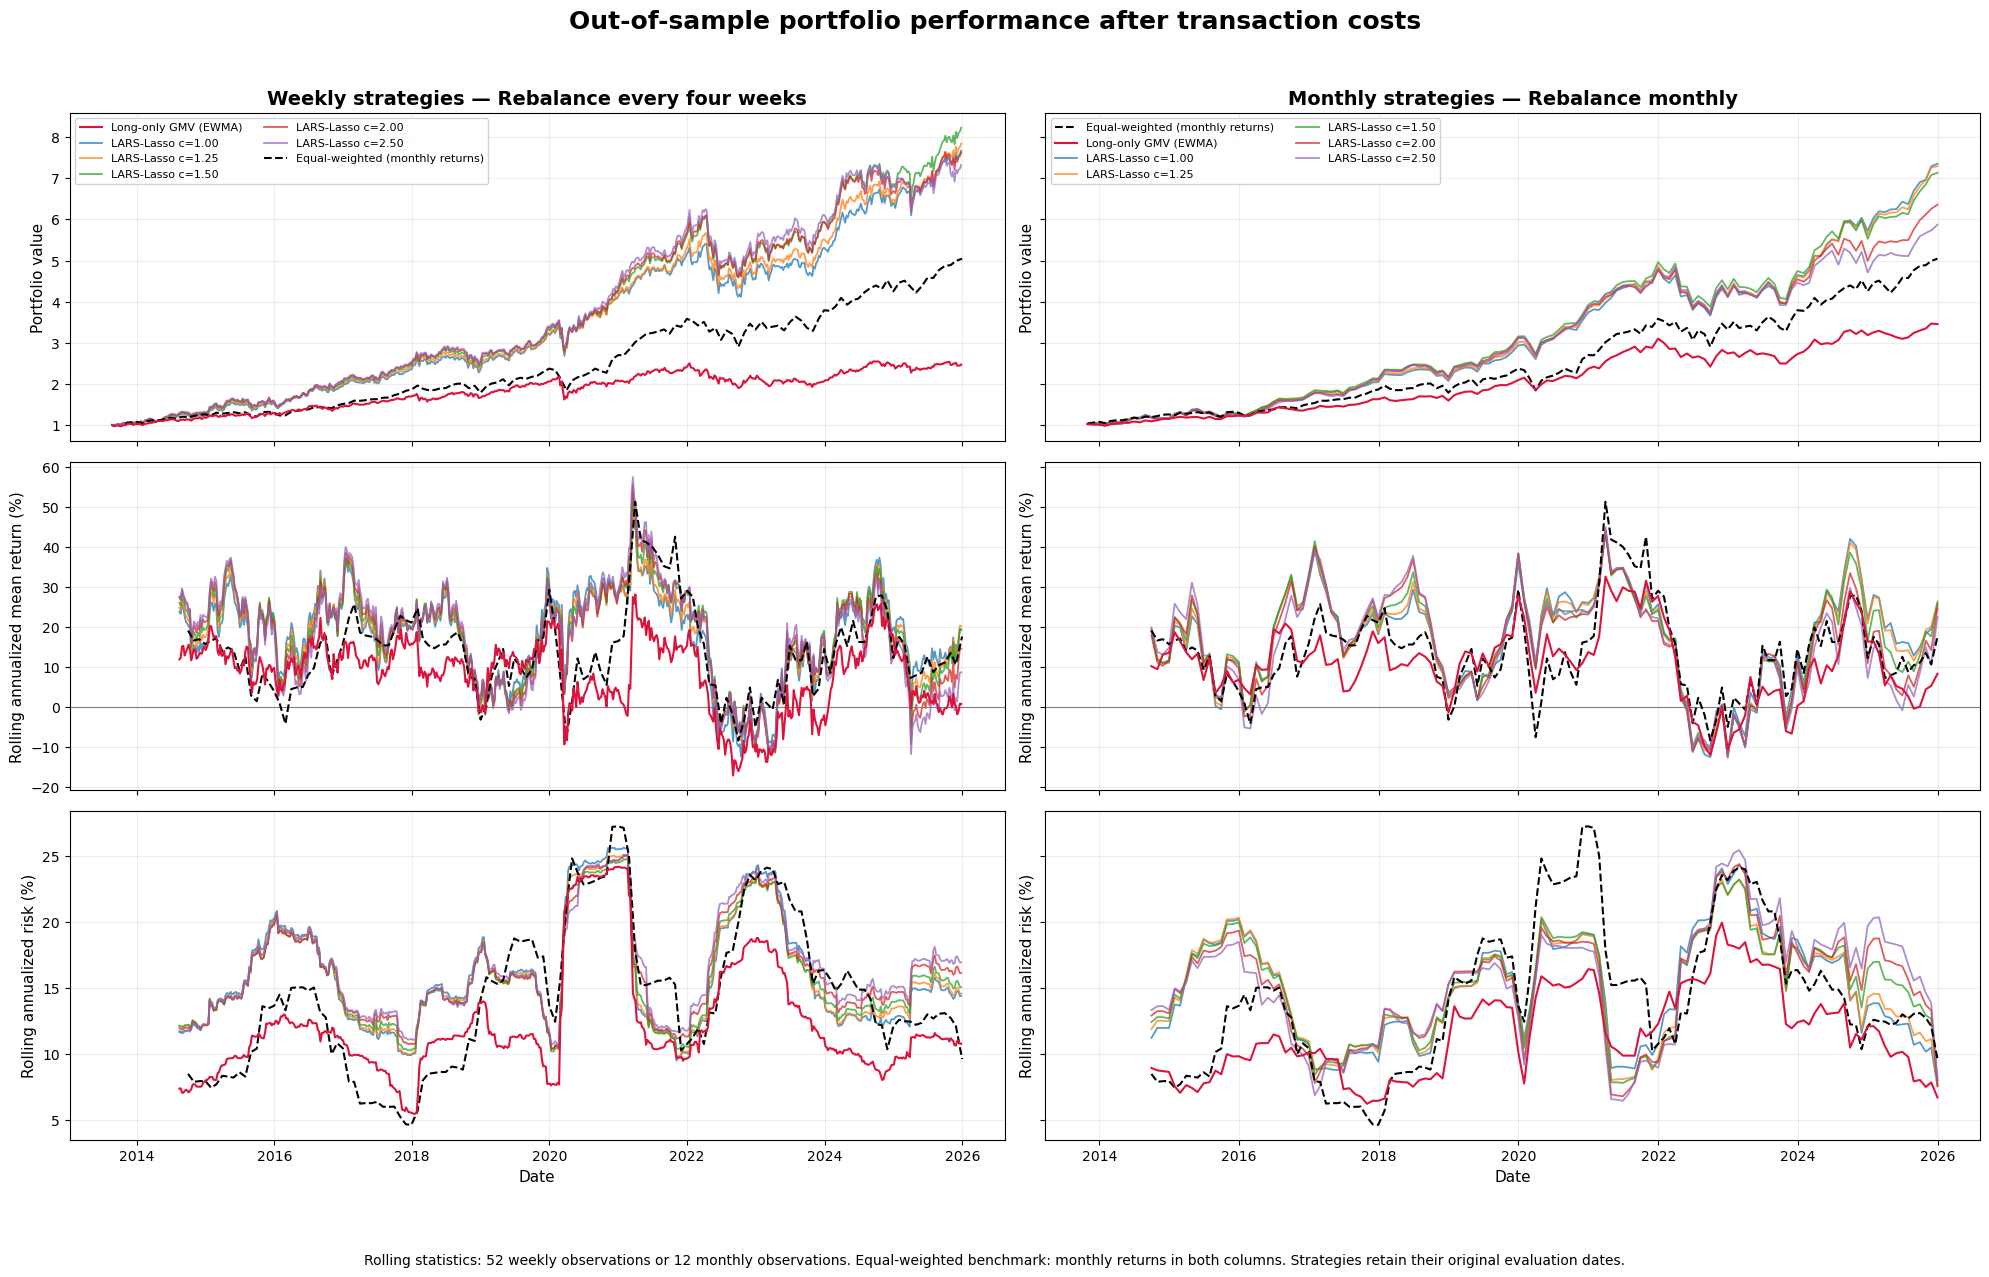

In [46]:
# Combined presentation figure: weekly strategies on the left, monthly on the right.
# Weekly rolling statistics use 52 observations; monthly statistics use 12.
# The existing monthly EW benchmark is also shown on the weekly panels as a
# reference, without resampling it or creating a new weekly trading strategy.
plot_specs = [
    ('portfolio_value', 1, 'Portfolio value'),
    ('rolling_realized_return', 100, 'Rolling annualized mean return (%)'),
    ('rolling_realized_risk', 100, 'Rolling annualized risk (%)'),
]
fig, axes = plt.subplots(3, 2, figsize=(20, 13), sharex='col', sharey='row')
exposure_colors = {c: plt.get_cmap('tab10')(i)
                   for i, c in enumerate(['1.00', '1.25', '1.50', '2.00', '2.50'])}
for column, (frequency, results, gmv_name) in enumerate([
    ('Weekly', weekly_backtests, 'A Constrained GMV - EWMA'),
    ('Monthly', monthly_backtests, 'B Constrained GMV - EWMA'),
]):
    plot_results = {
        name: bt for name, bt in results.items()
        if name.startswith(f'{frequency} Fan LARS-Lasso c=')
        or name in ('Equal Weighted', gmv_name)
    }
    if 'Equal Weighted' in monthly_backtests:
        plot_results['Equal Weighted'] = monthly_backtests['Equal Weighted']
    for strategy_name, bt in plot_results.items():
        if strategy_name == 'Equal Weighted':
            label = 'Equal-weighted (monthly returns)'
            style = dict(color='black', linewidth=1.5, linestyle='--', alpha=1, zorder=5)
        elif strategy_name == gmv_name:
            label = 'Long-only GMV (EWMA)'
            style = dict(color='crimson', linewidth=1.5, linestyle='-', alpha=1, zorder=6)
        else:
            label = strategy_name.replace(f'{frequency} Fan ', '').replace(f'{frequency} ', '')
            exposure = strategy_name.rsplit('c=', 1)[-1]
            style = dict(color=exposure_colors.get(exposure, 'gray'), linewidth=1.3,
                         linestyle='-',
                         alpha=0.75, zorder=2)
        for row, (metric, scale, ylabel) in enumerate(plot_specs):
            axes[row, column].plot(bt.index, bt[metric] * scale, label=label, **style)

    schedule = 'Rebalance every four weeks' if frequency == 'Weekly' else 'Rebalance monthly'
    axes[0, column].set_title(f'{frequency} strategies — {schedule}', fontsize=14, fontweight='bold')
    axes[0, column].legend(fontsize=8, loc='upper left', ncol=2, framealpha=0.9)
    for row, (_, _, ylabel) in enumerate(plot_specs):
        ax = axes[row, column]
        ax.set_ylabel(ylabel, fontsize=11)
        ax.grid(True, alpha=0.22)
        ax.tick_params(labelsize=10)
    axes[1, column].axhline(0, color='gray', linewidth=0.8)
    axes[2, column].set_xlabel('Date', fontsize=11)

fig.suptitle('Out-of-sample portfolio performance after transaction costs',
             fontsize=18, fontweight='bold')
fig.text(0.5, 0.015,
         'Rolling statistics: 52 weekly observations or 12 monthly observations. '
         'Equal-weighted benchmark: monthly returns in both columns. '
         'Strategies retain their original evaluation dates.',
         ha='center', fontsize=10)
fig.tight_layout(rect=(0, 0.065, 1, 0.96))
fig.savefig('backtest_results_combined1.png', dpi=300, bbox_inches='tight')
fig.savefig('backtest_results_combined1.pdf', bbox_inches='tight')
plt.show()
plt.close(fig)


In [39]:
### this are the stock active in the case of c=1 for weekly and monthly return. 
### i notice that in the case of weekly the last rebalancing dates is 2025-12-31 while for monthly return i have the last rebalancing dates 
## is 2025-11-28. I can make a comparison from the difference between the stock selected and the 



def display_active_lars_stocks(weights_by_date, approach_label, tolerance=1e-8):
    latest_date = sorted(weights_by_date.keys())[-1] ## taking the last rebalancing dates
    weights = pd.Series(weights_by_date[latest_date], dtype=float)
    active_weights = weights[weights.abs() > tolerance].sort_values(ascending=False)

    print(f"{approach_label} | latest rebalancing date: {latest_date.date()}")
    print(f"Active stocks: {len(active_weights)} / {len(weights)}")
    print(f"Gross exposure: {weights.abs().sum():.6f}")
    display(active_weights.rename("Weight").to_frame().round(6))
    return active_weights

active_stocks_A_lars_c100 = display_active_lars_stocks(
    weights_A_lars_lasso_c100,
    "Weekly Fan LARS-LASSO, c=1",
)

active_stocks_B_lars_c100 = display_active_lars_stocks(
    weights_B_lars_lasso_c100,
    "Monthly Fan LARS-LASSO, c=1",
)


Weekly Fan LARS-LASSO, c=1 | latest rebalancing date: 2025-12-19
Active stocks: 28 / 100
Gross exposure: 1.000000


,Weight
KR.N,0.106893
GIS.N,0.089350
NEM.N,0.082812
CLX.N,0.068997
OXY.N,0.063492
LLY.N,0.058446
T.N,0.051071
NFLX.O,0.044013
GE.N,0.043647
TM,0.042480


Monthly Fan LARS-LASSO, c=1 | latest rebalancing date: 2025-12-31
Active stocks: 24 / 100
Gross exposure: 1.000000


,Weight
LLY.N,0.112436
SCHW.N,0.099038
T.N,0.091356
NEE.N,0.082173
NEM.N,0.081920
TM,0.064689
AMZN.O,0.060948
CLX.N,0.054641
GIS.N,0.054375
GILD.O,0.045167


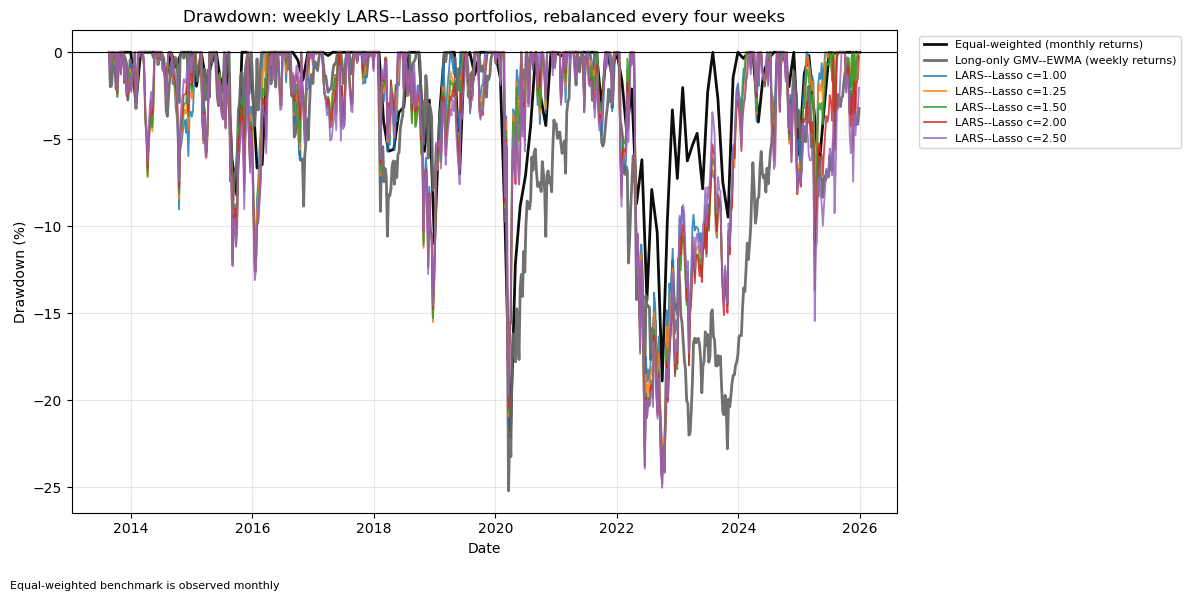

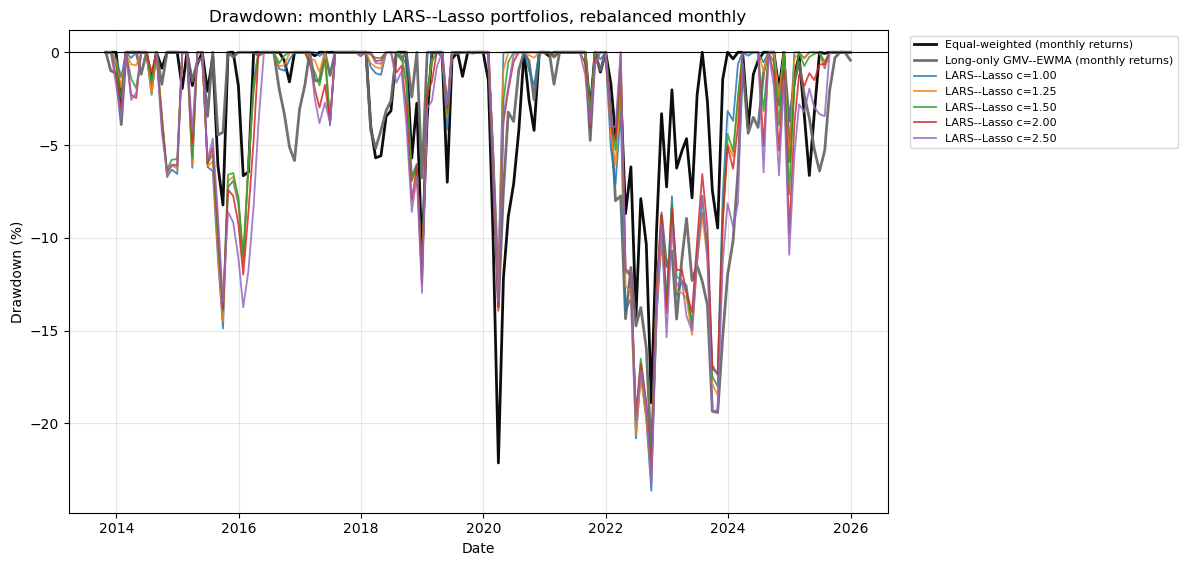


Maximum drawdown comparison - selected strategies:


,Return frequency,Maximum Drawdown (%),Date of Maximum Drawdown
Portfolio,,,
Equal Weighted,Monthly,-22.1340,2020-03-31 00:00:00+00:00
B Constrained GMV - EWMA,Monthly,-21.8211,2022-09-30 00:00:00+00:00
A Constrained GMV - EWMA,Weekly,-25.2063,2020-03-20 00:00:00+00:00
Weekly Fan LARS-Lasso c=1.00,Weekly,-23.8016,2022-09-30 00:00:00+00:00
Weekly Fan LARS-Lasso c=1.25,Weekly,-23.6865,2022-09-30 00:00:00+00:00
Weekly Fan LARS-Lasso c=1.50,Weekly,-24.3033,2022-09-30 00:00:00+00:00
Weekly Fan LARS-Lasso c=2.00,Weekly,-24.8298,2022-09-30 00:00:00+00:00
Weekly Fan LARS-Lasso c=2.50,Weekly,-25.0347,2022-09-30 00:00:00+00:00
Monthly Fan LARS-Lasso c=1.00,Monthly,-23.6362,2022-09-30 00:00:00+00:00


In [40]:

# =============================================================================
# MAXIMUM DRAWDOWN PLOT: SELECTED PORTFOLIO STRATEGIES
# =============================================================================
# We use the same portfolio_backtests dictionary created in the cell above.
# Drawdown measures the percentage loss from the previous portfolio-value peak:
# The running peak starts at the first recorded out-of-sample portfolio value.

if "portfolio_backtests" not in globals(): ## accessing the global portfolios. 
    raise RuntimeError("Run the main backtesting cell before this drawdown plot.")

# Select the strategies that we want to compare in the maximum drawdown plot.
selected_drawdown_strategies = [
    "Equal Weighted",
    #"A GMV - sample covariance",
    #"A Max Trade-Off - sample covariance",
    #"B GMV - sample covariance", 
    #"B Max Trade-Off - sample covariance",
    #"A GMV - EWMA",
    #"B GMV - EWMA",
    #"A Max Trade-Off - EWMA",
    #'B Max Trade-Off - EWMA',
    #"A Max Trade-Off - EWMA",
    #"B Max Trade-Off - EWMA",
    "B Constrained GMV - EWMA",
    "A Constrained GMV - EWMA",
    "Weekly Fan LARS-Lasso c=1.00",
    "Weekly Fan LARS-Lasso c=1.25",
    "Weekly Fan LARS-Lasso c=1.50",
    "Weekly Fan LARS-Lasso c=2.00",
    "Weekly Fan LARS-Lasso c=2.50",
    "Monthly Fan LARS-Lasso c=1.00",
    "Monthly Fan LARS-Lasso c=1.25",
    "Monthly Fan LARS-Lasso c=1.50",
    "Monthly Fan LARS-Lasso c=2.00",
    "Monthly Fan LARS-Lasso c=2.50",
]

available_drawdown_strategies = {
    strategy_name: portfolio_backtests[strategy_name]
    for strategy_name in selected_drawdown_strategies
    if strategy_name in portfolio_backtests
}

missing_drawdown_strategies = [
    strategy_name
    for strategy_name in selected_drawdown_strategies
    if strategy_name not in portfolio_backtests
]

if len(available_drawdown_strategies) == 0:
    raise RuntimeError("None of the selected strategies were found inside portfolio_backtests.")

if len(missing_drawdown_strategies) > 0:
    print("Warning: these requested strategies are missing from portfolio_backtests:")
    print(missing_drawdown_strategies)

max_drawdown_rows = []
drawdown_series = {}

for strategy_name, bt in available_drawdown_strategies.items():
    portfolio_value = bt["portfolio_value"].dropna()
    running_peak = portfolio_value.cummax()
    drawdown = portfolio_value / running_peak - 1.0
    max_drawdown = drawdown.min()

    drawdown_series[strategy_name] = drawdown

    max_drawdown_rows.append({
        "Portfolio": strategy_name,
        "Return frequency": backtest_strategies[strategy_name]["frequency"],
        "Maximum Drawdown (%)": max_drawdown * 100,
        "Date of Maximum Drawdown": drawdown.idxmin(),
    })

# Separate figures retain each series at its original observation frequency.
# The same monthly EW benchmark is shown in both; no weekly benchmark is created.
for frequency, gmv_name in [
    ('Weekly', 'A Constrained GMV - EWMA'),
    ('Monthly', 'B Constrained GMV - EWMA'),
]:
    figure_strategies = [
        name for name in available_drawdown_strategies
        if name in ('Equal Weighted', gmv_name)
        or name.startswith(f'{frequency} Fan LARS-Lasso')
    ]
    fig, ax = plt.subplots(figsize=(12, 6))
    for strategy_name in figure_strategies:
        drawdown = drawdown_series[strategy_name]
        if strategy_name == 'Equal Weighted':
            label = 'Equal-weighted (monthly returns)'
            style = dict(color='black',  linewidth=2.0, alpha=0.95)
        elif strategy_name == gmv_name:
            label = f'Long-only GMV--EWMA ({frequency.lower()} returns)'
            style = dict(color='dimgray',  linewidth=2.0, alpha=0.95)
        else:
            label = strategy_name.replace(f'{frequency} Fan LARS-Lasso', 'LARS--Lasso')
            style = dict(linewidth=1.3, alpha=0.85)
        ax.plot(drawdown.index, drawdown * 100, label=label, **style)

    schedule = 'rebalanced every four weeks' if frequency == 'Weekly' else 'rebalanced monthly'
    ax.set_title(f'Drawdown: {frequency.lower()} LARS--Lasso portfolios, {schedule}')
    ax.set_ylabel('Drawdown (%)')
    ax.set_xlabel('Date')
    ax.axhline(0, color='black', linewidth=0.8)
    ax.grid(True, alpha=0.3)
    ax.legend(loc='upper left', bbox_to_anchor=(1.02, 1.0), fontsize=8)
    if frequency == 'Weekly':
        fig.text(0.01, 0.01, 'Equal-weighted benchmark is observed monthly', fontsize=8)
            
    fig.tight_layout(rect=(0, 0.04, 1, 1))
    fig.savefig(f'max_drawdown_comparison_{frequency.lower()}.png',
                dpi=300, bbox_inches='tight')
    plt.show()
    plt.close(fig)

max_drawdown_comparison = pd.DataFrame(max_drawdown_rows).set_index("Portfolio")
print("\nMaximum drawdown comparison - selected strategies:")
display(max_drawdown_comparison.round(4))
